# Perfil de amenaza tecnológica por departamento: del modelo base al modelo integrado
## Proyecto Integrador · Diseño, implementación y evaluación de un modelo neuronal aplicado (Unidad 3)

**Redes Neuronales · Universidad de La Sabana · Sector elegido: Seguridad y defensa**

| | |
|---|---|
| **Integrantes** | Laura Alejandra Díaz Sastoque (0000288870) · Juan Diego Saldarriaga Muñoz (0000287391) |
| **Actividad** | Actividad 5: Proyecto Integrador (evaluativa, grupal) |
| **Entregas anteriores** | Etapa 1: formulación, variables y dataset (U1) · Etapa 2: modelo base entrenado (U2) |
| **Fecha** | Noviembre de 2026 |
| **Herramientas** | Python · pandas · scikit-learn · TensorFlow / Keras 3 · paquete propio `perfil_amenaza` (este repositorio) |

## Resumen ejecutivo

Este cuaderno cierra el ciclo del proyecto. Toma el modelo base de la U2, un MLP que no superaba la persistencia del
perfil, y lo optimiza con nueve intervenciones derivadas de su diagnóstico. Cada una se acepta o se rechaza con una
regla de retención fijada antes de ejecutarlas, y el modelo final queda integrado en un pipeline reproducible con pruebas
automáticas y un artefacto único de despliegue. Después de la revisión del informe agregamos dos controles que no
cambiaron el modelo: una persistencia calibrada como rival y una validación espacial que también bloquea el tiempo.

| | Resultado |
|---|---|
| Problema | Anticipar con un año de antelación si cada departamento tendrá perfil de amenaza C (convencional) o D (mixto), para orientar ISR, C-UAS y detección de AEI |
| Datos | Panel departamento–año 2021–2026 (171 filas, 30 departamentos, 82 C y 89 D), igual al de la U2. Dos variables nuevas retenidas: memoria del perfil ($m_1$) y composición del último semestre ($d_1$) |
| Modelo final | Ensamble de 10 MLP 9 → 16 ReLU → 1 (177 parámetros por red), L2 = 10⁻³, Adam, 560 pasos |
| Antes → después (origen móvil 2023–2025, n = 87) | Frente al modelo entregado en la U2 (semilla 42): log-loss 0,407 → 0,304. Frente a la misma arquitectura base con ensamble de 10 semillas: 0,376 → 0,304 (Δ −0,072; IC95 por departamento [−0,114; −0,033]) |
| Frente a la inercia | Persistencia cruda: log-loss 0,363 (el modelo gana por calibración; la persistencia tiene mejor AUC y exactitud). Persistencia calibrada: 0,328 (Δ −0,024; IC95 [−0,096; +0,052]). En departamentos nuevos y años futuros: 0,361 del modelo frente a 0,363 de la persistencia y 0,332 de la persistencia calibrada |
| Prueba 2026 (una sola vez) | Log-loss 0,380 (persistencia 0,429; persistencia calibrada 0,351; base U2 con ensamble 0,470); AUC 0,900; exactitud 0,83; sensibilidad C 0,93 |
| Descartadas con evidencia | Actores armados $x_3$ (UCDP), trayectoria $m_2,m_3$, tendencias $d_2,d_3$, vecindad, objetivo blando, salida multitarea A/B, GRU, CNN 1D, cambio de capacidad y calibración. El embedding de departamento cumplió la regla de retención, pero no se adoptó por la regla 8 (agregada al ver este caso); en 2026 fue mejor (log-loss 0,314) y se declara (§9.3) |
| Integración | Paquete `perfil_amenaza`, 10 pruebas automáticas, línea de comandos de 8 etapas, artefacto `.keras` de 152 KB, PSI con piso de ruido y tarjeta del modelo |
| Decisión 2027 | 11 departamentos C consolidados (9 con datos suficientes), 11 en transición y 11 D. Alerta A/B en Guaviare y Cauca. La proyección contradice el perfil de 2026 en 3 departamentos (en la U2, 10), lo que mide cercanía a la inercia y no acierto |

En una frase: con dos variables que resumen la composición reciente del conflicto, la red mejora con claridad frente al
modelo de la U2, pero frente a una inercia bien calibrada su ventaja no está demostrada a escala departamental. Su
debilidad sigue siendo anticipar los cambios de perfil: acierta 2 de 13 transiciones, frente a 3 del modelo de la U2 y 0
de la persistencia.

## Cómo leer este notebook

La guía de la Unidad 3 pide un informe con ocho contenidos y la rúbrica evalúa cinco criterios. Cada fila indica dónde
está la evidencia. La matriz completa, con las cifras, está en §15.

| Contenido exigido (Producto 1) / criterio de la rúbrica | Sección |
|---|---|
| Planteamiento del problema y contexto · **Coherencia metodológica integral** | §1 (trazabilidad U1 → U2 → U3), §13 |
| Descripción del dataset y preprocesamiento · **Preparación y representación de datos** | §2 (datos y variables nuevas), §7 (controles experimentales) |
| Arquitectura del modelo y justificación · **Calidad técnica del modelo y optimización** | §6.6–§6.8, §8 |
| Proceso de entrenamiento y evaluación | §3 (protocolo), §8 (curvas), §9 |
| Optimización realizada y comparación de resultados | §5 (diagnóstico), §6 (intervenciones I1–I9), §9 (antes vs. después) |
| Análisis crítico del desempeño · **Evaluación del desempeño e interpretación** | §9, §10 |
| Integración final del modelo en un pipeline estructurado | §11 (paquete, línea de comandos, pruebas, artefacto único, deriva) |
| Conclusiones técnicas y recomendaciones futuras | §12 (decisión 2027), §13 |
| **Entregables finales y comunicación ejecutiva** (roles, bitácora, IA) | §14, §15, §16 |

> **Reproducibilidad.** El cuaderno se ejecuta de principio a fin desde la carpeta `Proyecto_Unidad_3/` (en local o en
> Colab, subiendo la carpeta). Todo el cálculo está en el paquete `src/perfil_amenaza/`, el mismo que usa la línea de
> comandos de §11. El cuaderno no duplica la lógica: la importa. Las cifras del texto corresponden a la ejecución
> guardada en este archivo (CPU, semillas fijas, determinismo de TensorFlow activado). En otro hardware pueden
> variar en el tercer decimal.

---
# 0. Entorno, semillas y paquete del proyecto

In [1]:
# =============================================================================
# 0.1 Librerías, determinismo y paquete del proyecto
# =============================================================================
import os, sys, time, json, math, platform, subprocess, warnings
from pathlib import Path
from dataclasses import replace, asdict

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from perfil_amenaza import config as C            # fija TF_ENABLE_ONEDNN_OPTS=0 antes de importar TensorFlow
from perfil_amenaza import datos as D, variables as V, modelo as M, evaluacion as E, pipeline as P, graficos as G

import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle, FancyBboxPatch
from matplotlib.lines import Line2D
import tensorflow as tf, keras, sklearn, scipy
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
keras.utils.set_random_seed(C.SEED)
tf.config.experimental.enable_op_determinism()
G.aplicar_estilo(); COL, TINTA, TINTA2, TENUE, GRID, EJE, FONDO = G.COL, G.TINTA, G.TINTA2, G.TENUE, G.GRID, G.EJE, G.FONDO
C.asegurar_carpetas()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
tabla, guardar = G.tabla, G.guardar

display(pd.Series({
    "Python": platform.python_version(), "Sistema": platform.platform(terse=True),
    "NumPy / pandas / SciPy": f"{np.__version__} / {pd.__version__} / {scipy.__version__}",
    "scikit-learn": sklearn.__version__, "TensorFlow / Keras": f"{tf.__version__} / {keras.__version__}",
    "Dispositivos": ", ".join(sorted({d.device_type for d in tf.config.list_physical_devices()})),
    "Semilla global": C.SEED, "Paquete del proyecto": f"perfil_amenaza {__import__('perfil_amenaza').__version__}",
}, name="Valor").to_frame())
T0_CUADERNO = time.time()

,Valor
Python,3.13.18
Sistema,Linux-6.18.44-fc-v236-x86_64-with-glibc2.39
NumPy / pandas / SciPy,2.5.3 / 3.0.5 / 1.18.1
scikit-learn,1.9.1
TensorFlow / Keras,2.21.0 / 3.15.1
Dispositivos,CPU
Semilla global,42
Paquete del proyecto,perfil_amenaza 3.0.0


---
# 1. Problema, contexto y trazabilidad U1 → U2 → U3

**Pregunta orientadora (Unidad 1, textual):**

> *¿Cómo orientar la adquisición, transferencia de tecnología y fabricación de sistemas de seguridad y defensa de las
> Fuerzas de Colombia en función del perfil de amenaza tecnológica predominante de los municipios colombianos según
> las variables de actividad armada histórica, geografía operacional y economías ilícitas, de modo que se optimice la
> inversión de recursos en búsqueda del bienestar de los colombianos y el desarrollo del país?*

La pregunta habla de municipios, pero el export gratuito de ACLED solo desagrega a departamento (hallazgo de la
Etapa 1). Por eso la respondemos a escala departamental y dejamos la migración a municipio como primera recomendación
(R1, §13).

**Formulación operativa (igual a la U2).** Para cada departamento $d$ y año $t$, la etiqueta es

$$
s^{C}_{d,t} = \frac{\#\{\text{eventos de subtipos C en } d,t\}}{\#\{\text{eventos en } d,t\}},\qquad
y_{d,t} = \mathbb{1}\left[s^{C}_{d,t} \ge 0.5\right],\qquad
\hat p_{d,t} = f_{\boldsymbol\theta}\left(\mathbf{x}_{d,t-1}\right) = P\left(y_{d,t} = 1 \mid \mathbf{x}_{d,t-1}\right).
$$

El modelo responde la pregunta que enfrenta quien planea la inversión: *con lo observado hasta el cierre del año,
¿qué perfil tendrá cada territorio el año siguiente?* El rezago $t-1 \rightarrow t$ evita la circularidad entre
predictoras y etiqueta (§1.1 de la U2).

## 1.1 Qué dejó cada etapa y qué cambia en esta

| Etapa | Resultado | Hallazgo que condiciona la siguiente |
|---|---|---|
| **U1** Formulación | Perfiles A/B/C/D con la regla del 50 %; 7 variables; ACLED agregado a departamento | Ningún departamento es A o B dominante → clasificación **C vs. D**; 33 filas no bastan → panel departamento–año |
| **U2** Modelo base | MLP 7 → 16 → 1 (145 parámetros); AUC temporal 0,89; equivalente a la logística | **La inercia domina**: la persistencia (AUC 0,965; log-loss 0,380) supera a la red. La memoria del perfil (E1) es la palanca más fuerte |
| **U3** Integración | Intervenciones I1–I9 derivadas del diagnóstico, controles de datos, pipeline reproducible | La referencia a superar es la persistencia (cruda y, tras la revisión, calibrada). Un modelo aporta sobre ella cuando anticipa transiciones |

## 1.2 Trazabilidad de variables (actualizada)

| ID | Variable de la U1 | Operacionalización | Fuente | U2 | U3 |
|---|---|---|---|---|---|
| $y$ | Perfil predominante | $\mathbb{1}[s^C_{d,t} \ge 0{,}5]$, mapeo de subtipos de la U1 | ACLED | ✅ | ✅ sin cambios + control de la etiqueta parcial de 2026 (§2.3) |
| $x_1$, $x_2$, $x_{2b}$ | Eventos, fatalidades, letalidad | $\log(1+\cdot)$ anualizado en $t-1$; fatalidades/evento | ACLED | ✅ | ✅ |
| $x_3$ | Grupos armados activos | $\log(1+$actores no estatales distintos en $t-1)$ | UCDP GED 26.1 (sustituye a ACLED por evento) | ⏳ | ✅ implementada y evaluada (**I3**, §6.3) |
| $x_4$, $x_5$, $x_6$, $x_7$ | Coca, bosque, distancia, IPM | Igual que la U2 | SIMCI-ODC, GFW, centroides, DANE | ✅ | ✅ |
| $m_1$–$m_3$ | *(derivada de $x_1$: "intensidad histórica")* | Composición C contraída en $t-1$, $t-2$ y su cambio | ACLED | E1 (cruda) | **I1** (§6.1) |
| $d_1$–$d_3$ | *(nueva)* dinámica intra-anual | $s^C$ del 2.º semestre de $t-1$, tendencias semestrales | ACLED semanal | – | **I2** (§6.2) |
| $v_1$, $v_2$ | *(nueva)* contexto espacial | Composición y volumen de los departamentos contiguos en $t-1$ | ACLED + contigüidad IGAC | – | **I4** (§6.4) |

## 1.3 De la predicción a la decisión (sin cambios frente a la U2)

| Perfil proyectado | Lectura operacional | Énfasis tecnológico |
|---|---|---|
| **C consolidado** ($\hat p \ge 0{,}7$) | Domina la violencia directa entre actores armados | ISR, detección temprana, movilidad protegida |
| **Transición** ($0{,}3 \le \hat p < 0{,}7$) | Perfil inestable | Portafolio flexible y monitoreo trimestral |
| **D consolidado** ($\hat p < 0{,}3$) | Protesta, disturbio y violencia mixta | Orden público y capacidades mixtas |
| **Alerta A/B** | Explosivos y drones: poco volumen, alto impacto | C-UAS y detección de AEI, cualquiera sea el perfil |

---
# 2. Datos y preprocesamiento

## 2.1 Contrato y auditoría del export de ACLED

El export es el mismo de la U2 (semana × departamento × subtipo, hasta el 15 de agosto de 2026). La función
`datos.cargar_acled` valida el **contrato de datos**: si falta una columna, el pipeline se detiene con un mensaje
explícito en lugar de producir un modelo silenciosamente distinto.

In [2]:
# =============================================================================
# 2.1 Carga, contrato de datos y auditoría
# =============================================================================
bruto = D.cargar_acled()
acled = D.filtrar_horizonte(bruto)
display(D.auditar(bruto).style.hide(axis="index"))
print(f"Horizonte de estudio: {acled['week'].min():%Y-%m-%d} → {acled['week'].max():%Y-%m-%d} | "
      f"{len(acled):,} registros semanales | {int(acled['events'].sum()):,} eventos | {acled['depto'].nunique()} departamentos")
print(f"Semanas de 2026 disponibles: {int(acled.loc[acled.anio == 2026, 'semana_anio'].max())} de 52")

Verificación,Resultado
Registros / columnas,"17,573 / 12"
Registros fuera de Colombia,32
Cobertura temporal,2019-12-28 → 2026-08-15
Semanas distintas / saltos ≠ 7 días,347 / 0
Valores faltantes,0
Duplicados por llave semana–depto–subtipo,0
"Rangos válidos (events ≥ 1, fatalities ≥ 0)",True
Departamentos de Colombia,33


Horizonte de estudio: 2020-01-04 → 2026-08-15 | 17,533 registros semanales | 33,275 eventos | 33 departamentos
Semanas de 2026 disponibles: 33 de 52


## 2.2 Panel departamento–año y variable objetivo

Se reutiliza sin cambios la construcción de la U2: mapeo de subtipos de la U1, regla del 50 % y umbral de
confiabilidad de 10 eventos (D3). Comprobamos que el panel reproduce los hallazgos de la U2 antes de agregar nada.

In [3]:
# =============================================================================
# 2.2 Panel, etiqueta y persistencia (réplica de la U2)
# =============================================================================
panel = D.construir_panel(acled)
etiq = panel[(panel.anio >= 2021) & panel.confiable]
pv = panel.pivot(index="depto", columns="anio", values="perfil").where(panel.pivot(index="depto", columns="anio", values="confiable"))
pares = pd.concat([pd.DataFrame({"t-1": pv[a - 1].values, "t": pv[a].values}) for a in range(2021, 2027)], ignore_index=True).dropna()
trans = pd.crosstab(pares["t-1"], pares["t"], rownames=["Perfil t-1"], colnames=["Perfil t"])
display(trans)
print(f"Celdas etiquetables 2021-2026: {len(etiq)} | perfil A o B dominante: {int(panel.perfil.isin(['A', 'B']).sum())} | "
      f"persistencia año a año: {np.trace(trans.values) / trans.values.sum():.1%} | cambios de perfil: {int(trans.values.sum() - np.trace(trans.values))}")
prev_anio = etiq.groupby("anio")["y"].agg(["size", "mean"]).rename(columns={"size": "Departamentos", "mean": "Prevalencia C"})
tabla(prev_anio.T, dec=2)

Perfil t,C,D
Perfil t-1,,
C,69,12
D,11,73


Celdas etiquetables 2021-2026: 171 | perfil A o B dominante: 0 | persistencia año a año: 86.1% | cambios de perfil: 23


anio,2021,2022,2023,2024,2025,2026
Departamentos,28,27,29,29,29,29
Prevalencia C,"0,32","0,56","0,48","0,41","0,62","0,48"


## 2.3 Control nuevo: ¿es confiable la etiqueta parcial de 2026?

La prueba de 2026 solo tiene **33 semanas** (enero–agosto). Si la composición de la segunda mitad del año fuera
distinta, la etiqueta parcial no representaría el perfil del año, y la prueba mediría otra cosa. Lo verificamos
con datos que sí están completos: recalculamos la etiqueta de 2021–2025 usando **solo las primeras 33 semanas** de
cada año y la comparamos con la del año completo.

anio,2021,2022,2023,2024,2025
Celdas,28,25,27,28,28
Coincidencia,"0,964","0,920","0,963","0,964","0,929"


Coincidencia global: 94.9% de 136 celdas | discrepancias: 7, de las cuales 100% tienen s_C del año completo a ±10 pp del umbral


departamento,anio,s_C,s_C_parcial,perfil,perfil_parcial,eventos
Chocó,2021,0.48,0.60,D,C,169
Córdoba,2022,0.49,0.52,D,C,114
Magdalena,2022,0.49,0.55,D,C,87
Antioquia,2023,0.53,0.45,C,D,596
Córdoba,2024,0.48,0.56,D,C,92
Córdoba,2025,0.55,0.48,C,D,131
Valle del Cauca,2025,0.52,0.49,C,D,394


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


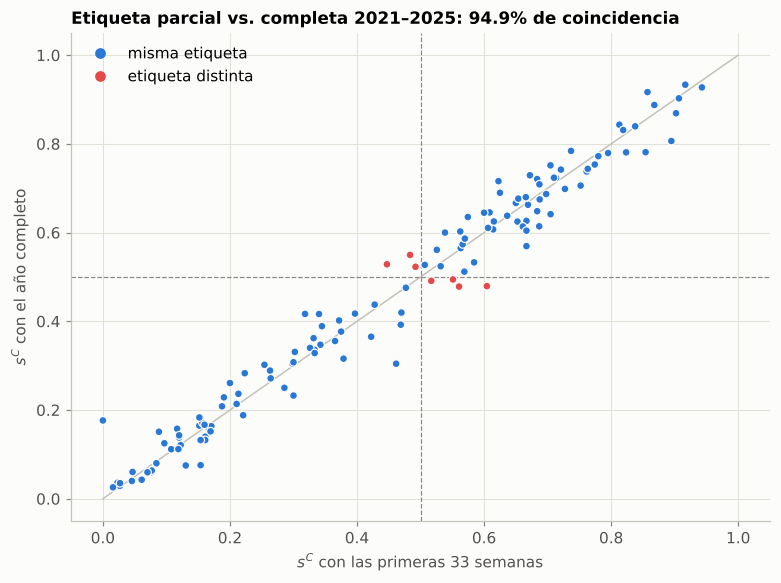

In [4]:
# =============================================================================
# 2.3 Coincidencia entre la etiqueta a la semana 33 y la del año completo (2021-2025)
# =============================================================================
ctrl, N_SEM_2026 = D.control_etiqueta_parcial(acled)
COINCIDENCIA_PARCIAL = ctrl["coincide"].mean()
por_anio = ctrl.groupby("anio")["coincide"].agg(["size", "mean"]).rename(columns={"size": "Celdas", "mean": "Coincidencia"})
tabla(por_anio.T, dec=3)
discrepa = ctrl[~ctrl.coincide].assign(departamento=lambda d: d.depto.map(C.NOMBRE))
cerca = ((discrepa["s_C"] - .5).abs() < .1).mean()
print(f"Coincidencia global: {COINCIDENCIA_PARCIAL:.1%} de {len(ctrl)} celdas | discrepancias: {len(discrepa)}, "
      f"de las cuales {cerca:.0%} tienen s_C del año completo a ±10 pp del umbral")
display(discrepa[["departamento", "anio", "s_C", "s_C_parcial", "perfil", "perfil_parcial", "eventos"]]
        .sort_values("anio").style.format({"s_C": "{:.2f}", "s_C_parcial": "{:.2f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.scatter(ctrl["s_C_parcial"], ctrl["s_C"], s=26, c=np.where(ctrl.coincide, COL["mlp"], COL["A"]), edgecolor=FONDO, lw=.8, zorder=3)
ax.plot([0, 1], [0, 1], color=EJE, lw=1); ax.axvline(.5, color=TENUE, lw=.8, ls="--"); ax.axhline(.5, color=TENUE, lw=.8, ls="--")
ax.set_xlabel(f"$s^C$ con las primeras {N_SEM_2026} semanas"); ax.set_ylabel("$s^C$ con el año completo")
ax.set_title(f"Etiqueta parcial vs. completa 2021–2025: {COINCIDENCIA_PARCIAL:.1%} de coincidencia")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=COL["mlp"], label="misma etiqueta"),
                   Line2D([], [], marker="o", ls="", color=COL["A"], label="etiqueta distinta")], loc="upper left")
fig.tight_layout(); guardar(fig, "fig01_etiqueta_parcial"); plt.show()

**Lectura.** Con las primeras 33 semanas, la etiqueta coincide con la del año completo en el **94,9 %** de las 136
celdas de 2021–2025. Las 7 discrepancias tienen todas un $s^C$ anual a menos de 10 pp del umbral (Córdoba aparece
tres veces). La etiqueta parcial no cambia el perfil de los departamentos con un régimen claro; solo voltea casos que
ya eran ambiguos. Para la prueba de 2026 esperamos entonces **1 o 2 etiquetas** de 29 distintas de las que tendrá el
año cerrado, y todas en la franja ambigua. Por eso, en §9.3 una métrica probabilística (log-loss) es más confiable que
la exactitud.

## 2.4 Dataset de modelado: reproducción de la U2 y variables nuevas

`variables.construir_dataset` arma una fila por departamento–año etiquetable, con todas las predictoras medidas en
$t-1$. Primero comprobamos que las 7 predictoras y la etiqueta de la U2 se reproducen **exactamente**, para que toda
diferencia posterior se deba a las intervenciones y no a la reconstrucción de los datos.

**Variables nuevas.** Cada grupo responde a un hallazgo del diagnóstico de la U2:

| Grupo | Variable | Definición (todas en $t-1$) | Diagnóstico U2 que la motiva |
|---|---|---|---|
| I1 memoria | $m_1$ | $\tilde s^C_{d,t-1} = \dfrac{C_{d,t-1} + \alpha\,p_0}{n_{d,t-1} + \alpha}$, con $\alpha = 4$, $p_0 = 0{,}5$ | La persistencia acierta el 86 %; 57 % de los errores son transiciones |
| | $m_2$, $m_3$ | $\tilde s^C_{d,t-2}$ y $m_1 - m_2$ | ¿Importa la trayectoria, no solo el último año? |
| I2 dinámica | $d_1$ | $\tilde s^C$ de las últimas 26 semanas de $t-1$ | La vista anual promedia cambios de régimen recientes (p. ej., 2025) |
| | $d_2$, $d_3$ | $\log(1+n_{H2}) - \log(1+n_{H1})$ y $\tilde s^C_{H2} - \tilde s^C_{H1}$ | Tendencia de volumen y de composición dentro del año |
| I4 vecindad | $v_1$, $v_2$ | $\tilde s^C$ agregada y $\log$ de eventos medios de los departamentos contiguos | Validación espacial débil (AUC 0,80) |

**¿Por qué contraer las proporciones?** Con $n$ eventos, $s^C$ tiene un error estándar de hasta $\sqrt{0{,}25/n}$.
La etiqueta exige $n \ge 10$ en $t$, pero las predictoras de $t-1$ o de un semestre pueden venir de pocos eventos.
La contracción bayesiana (un prior Beta(2, 2), equivalente a 4 eventos "neutros") acerca a 0,5 las proporciones
basadas en pocos datos y casi no toca las bien medidas: con 100 eventos, el ajuste máximo es de 2 pp. En §7 se
mide qué pasa sin ella.

In [5]:
# =============================================================================
# 2.4 Dataset U3 y verificación contra el dataset de la U2
# =============================================================================
ACTORES = D.cargar_ucdp()                     # None si UCDP GED no está en datos/externos/ (ver §6.3)
datos, SEQ, pext = V.construir_dataset(acled, actores=ACTORES)
datos["x8_memoria_C"] = datos["s_C_prev"]     # memoria cruda, tal como el experimento E1 de la U2
ref_u2 = pd.read_csv(RAIZ / "referencias_u2" / "dataset_modelado_departamento_anio.csv")
cmp_u2 = datos.merge(ref_u2, on=["depto", "anio"], suffixes=("", "_u2"))
dif_max = max(float(np.abs(cmp_u2[f] - cmp_u2[f + "_u2"]).max()) for f in V.BASE)
assert len(cmp_u2) == len(datos) == len(ref_u2) and (cmp_u2.y == cmp_u2.y_u2).all() and dif_max < 1e-9
print(f"Reproducción U2: {len(datos)} filas, {datos.depto.nunique()} departamentos, etiquetas idénticas, "
      f"diferencia máxima en las 7 predictoras = {dif_max:.1e}")
print(f"UCDP (x3): {'disponible, ' + str(len(ACTORES)) + ' filas departamento-año' if ACTORES is not None else 'no disponible en esta ejecución'}")
print(f"Tensor de secuencias trimestrales (comparativos GRU/CNN): {SEQ.shape}")
nuevas = V.MEMORIA + V.DINAMICA + V.VECINDAD
desc = datos[nuevas].describe().T[["mean", "std", "min", "50%", "max"]]
desc.columns = ["Media", "Desv. est.", "Mín.", "Mediana", "Máx."]
tabla(desc.rename(index=V.ETIQ), dec=3)

Reproducción U2: 171 filas, 30 departamentos, etiquetas idénticas, diferencia máxima en las 7 predictoras = 1.7e-13
UCDP (x3): disponible, 843 filas departamento-año
Tensor de secuencias trimestrales (comparativos GRU/CNN): (171, 4, 5)


,Media,Desv. est.,Mín.,Mediana,Máx.
m₁ s_C en t-1,"0,471","0,247","0,033","0,495","0,898"
m₂ s_C en t-2,"0,467","0,256","0,035","0,480","0,898"
m₃ cambio s_C (t-1 − t-2),"0,004","0,140","-0,562","0,000","0,604"
d₁ s_C 2.º semestre t-1,"0,479","0,237","0,040","0,500","0,900"
d₂ tendencia de eventos,"-0,142","0,531","-2,730","-0,045","1,386"
d₃ tendencia de s_C,"0,012","0,123","-0,333","0,014","0,384"
v₁ s_C de vecinos t-1,"0,512","0,179","0,129","0,517","0,855"
v₂ eventos de vecinos (log),"4,947","0,722","2,120","5,083","6,005"


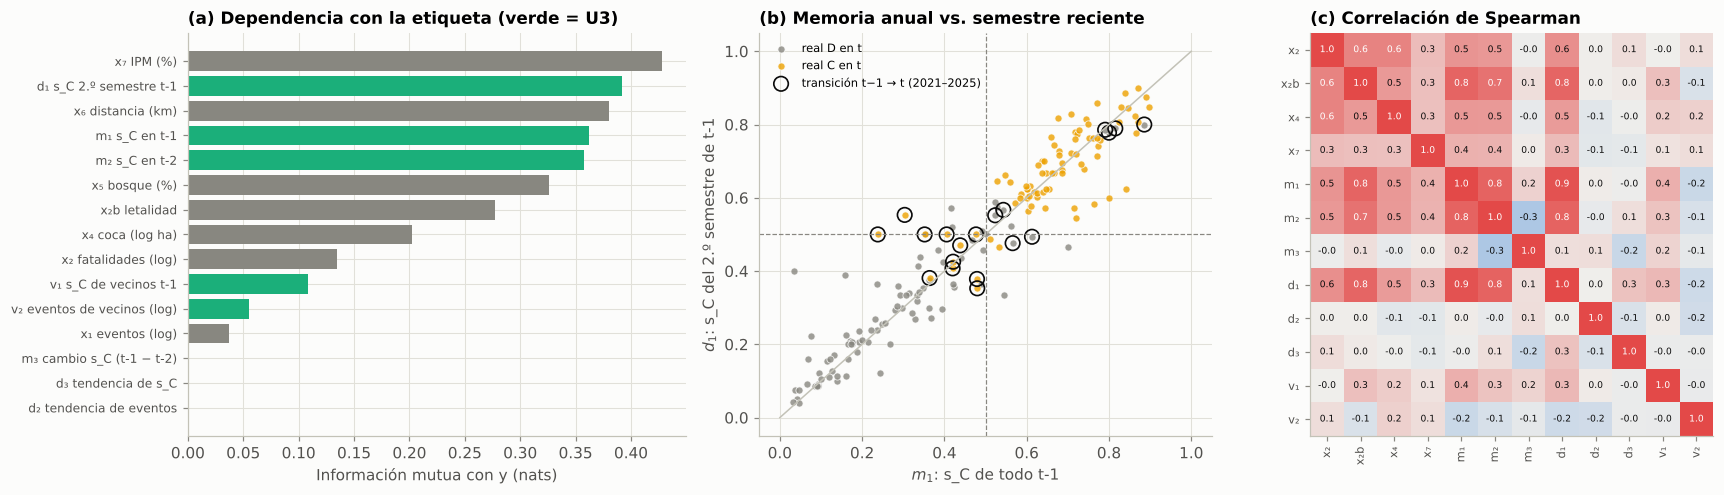

Transiciones 2021-2025 (cambio de perfil confiable, sin la prueba 2026): 19 | en 74% el 2.º semestre de t-1 ya se movía hacia el perfil de t


,ρ Spearman con y,Información mutua
m₁ s_C en t-1,"0,723","0,362"
m₂ s_C en t-2,"0,707","0,357"
m₃ cambio s_C (t-1 − t-2),"-0,030","0,000"
d₁ s_C 2.º semestre t-1,"0,753","0,392"
d₂ tendencia de eventos,"-0,051","0,000"
d₃ tendencia de s_C,"0,160","0,000"
v₁ s_C de vecinos t-1,"0,255","0,109"
v₂ eventos de vecinos (log),"-0,153","0,055"


In [6]:
# =============================================================================
# 2.5 EDA de las variables nuevas: ¿qué información agregan sobre la inercia?
# =============================================================================
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
cand = V.BASE + nuevas
rho = pd.Series({f: stats.spearmanr(datos[f], datos["y"]).correlation for f in cand})
mi = pd.Series(mutual_info_classif(datos[cand], datos["y"], random_state=C.SEED, n_neighbors=5), index=cand)

# En las transiciones, ¿el semestre reciente ya apuntaba hacia el nuevo perfil? Solo 2021-2025: 2026 es la prueba
tr_ = datos[datos.transicion & (datos.anio <= 2025)]
hacia = np.sign(tr_["d1_sC_H2"] - tr_["m1_sC_t1"]) == np.where(tr_["y"] == 1, 1, -1)
ANTICIPA_D1 = hacia.mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ax = axes[0]
orden = mi.sort_values().index
ax.barh(range(len(orden)), mi[orden], color=[COL["u3"] if f in nuevas else COL["D"] for f in orden])
ax.set_yticks(range(len(orden)), [V.ETIQ[f] for f in orden], fontsize=8)
ax.set_xlabel("Información mutua con y (nats)"); ax.set_title("(a) Dependencia con la etiqueta (verde = U3)")
ax = axes[1]
for clase, color in [(0, COL["D"]), (1, COL["C"])]:
    s = datos[datos.y == clase]
    ax.scatter(s["m1_sC_t1"], s["d1_sC_H2"], s=22, color=color, alpha=.8, edgecolor=FONDO, lw=.6, label=f"real {'C' if clase else 'D'} en t")
ax.scatter(tr_["m1_sC_t1"], tr_["d1_sC_H2"], s=90, facecolor="none", edgecolor=TINTA, lw=1.1, label="transición t−1 → t (2021–2025)")
ax.plot([0, 1], [0, 1], color=EJE, lw=1); ax.axhline(.5, color=TENUE, lw=.8, ls="--"); ax.axvline(.5, color=TENUE, lw=.8, ls="--")
ax.set_xlabel("$m_1$: s_C de todo t-1"); ax.set_ylabel("$d_1$: s_C del 2.º semestre de t-1")
ax.set_title("(b) Memoria anual vs. semestre reciente"); ax.legend(fontsize=7.5, loc="upper left")
ax = axes[2]
corr = datos[["x2_fatalidades", "x2b_letalidad", "x4_coca", "x7_ipm"] + nuevas].corr(method="spearman")
im = ax.imshow(corr.values, cmap=G.CMAP_DIV, vmin=-1, vmax=1)
et = [V.ETIQ[c].split(" ")[0] for c in corr.columns]
ax.set_xticks(range(len(et)), et, fontsize=7.5, rotation=90); ax.set_yticks(range(len(et)), et, fontsize=7.5)
for i in range(len(et)):
    for j in range(len(et)):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6, color="white" if abs(corr.values[i, j]) > .6 else TINTA)
ax.grid(False); ax.set_title("(c) Correlación de Spearman")
fig.tight_layout(); guardar(fig, "fig02_eda_variables_nuevas"); plt.show()
print(f"Transiciones 2021-2025 (cambio de perfil confiable, sin la prueba 2026): {len(tr_)} | en {ANTICIPA_D1:.0%} el 2.º semestre "
      f"de t-1 ya se movía hacia el perfil de t")
tabla(pd.DataFrame({"ρ Spearman con y": rho, "Información mutua": mi}).loc[nuevas].rename(index=V.ETIQ), dec=3)

**Lectura.**

* La composición reciente es la información más fuerte. $d_1$ (s_C del segundo semestre de $t-1$) tiene la mayor
  asociación monótona con $y$ (ρ = 0,75) y $m_1$ le sigue (0,72). Superan a cualquier variable estructural de la U1:
  la mejor era la letalidad, con ρ = 0,62.
* $d_1$ adelanta cambios. En el 74 % de las 19 transiciones de perfil de 2021–2025 (dejamos fuera la prueba 2026), el
  segundo semestre del año anterior ya se movía en la dirección del nuevo perfil (panel b: los círculos negros se separan
  de la diagonal). Es la justificación cuantitativa de I2: la vista anual promedia y diluye el giro reciente.
* Las tendencias no traen información propia. $m_3$, $d_2$ y $d_3$ tienen información mutua ≈ 0 con $y$. Son
  diferencias de variables que ya están en el modelo, y con 171 filas es poco probable que aporten. §6 lo comprueba.
* $m_1$, $m_2$ y $d_1$ están muy correlacionadas entre sí (panel c), como se esperaba. Por eso la cascada de §6 agrega
  una a la vez y exige que cada una mejore sobre la anterior.

---
# 3. Protocolo experimental de la Unidad 3

## 3.1 Reglas del protocolo

Las reglas 1 a 7 se fijaron antes de ejecutar las intervenciones. La regla 8 la agregamos durante las intervenciones,
al encontrar el caso del embedding de departamento (§6.7), y lo declaramos así. La persistencia calibrada de la regla 3
se agregó después de la revisión del informe y no cambió el modelo adoptado.

1. **Selección solo con origen móvil 2023–2025.** Para cada año $v \in \{2023, 2024, 2025\}$ se entrena con
   $t < v$ y se predice $v$ (87 predicciones fuera de muestra). El escalador se ajusta en cada pliegue solo con su
   entrenamiento (prueba automática en §11.3).
2. **2026 es la prueba final y se usa una sola vez**, con el modelo ya elegido. Hay que declararlo: la U2 ya reportó
   métricas sobre 2026, así que no es un conjunto virgen. Ninguna decisión de esta unidad se tomó mirándolo.
3. **La referencia es la persistencia** ($\hat p_{d,t} = s^C_{d,t-1}$; AUC 0,973 y log-loss 0,363 en 2023–2025).
   Como usa una proporción como si fuera una probabilidad, tras la revisión agregamos su versión calibrada: una
   logística de dos parámetros sobre $\mathrm{logit}(m_1)$, entrenada solo con los años anteriores al validado.
   Se reporta además a qué transiciones acierta cada modelo, porque la persistencia acierta 0 por construcción.
4. **Métrica de decisión: log-loss** (calidad probabilística completa), con AUC, Brier, MCC y ECE como métricas de
   apoyo. La exactitud con umbral fijo es la métrica menos estable con 29 departamentos por año (U2 §11.2).
5. **Regla de retención de una intervención.** Cada variante se entrena con las **mismas 5 semillas** que su
   referencia. Se conserva si la mejora media de la log-loss supera **un error estándar** de la diferencia pareada
   entre semillas, $\overline{\Delta LL} + \mathrm{EE}(\Delta LL) < 0$, y no baja el AUC medio más de 0,01. Si no se
   cumple, se prefiere la variante más simple (espíritu de la regla de 1 EE de la U2, D7). El EE mide el ruido del
   entrenamiento entre semillas, no el del muestreo de departamentos. En I4, cuya hipótesis es espacial, la regla se
   aplica a la validación espacial y se exige no empeorar la temporal. La regla está en `evaluacion.regla_retencion`.
   Las tablas de decisión agregan, como información y no como criterio, el IC 95 % de la misma diferencia
   remuestreando departamentos completos (`evaluacion.ic_pareado_semillas`), que sí refleja el muestreo de territorios.
6. **Presupuesto de entrenamiento fijo** de 560 pasos de gradiente (D10 de la U2), salvo cuando el presupuesto es
   la variable estudiada (§6.8). Así ninguna partición usa sus propios datos de prueba para detener el
   entrenamiento.
7. **Los controles de §7 verifican, no seleccionan.** Ponen a prueba decisiones de preprocesamiento heredadas de la
   U1 y la U2. Si un control favorece quitar una transformación, se reporta y queda como tarea para la siguiente
   iteración, pero no cambia el modelo dentro de esta. Si lo cambiara, se sumarían grados de libertad a la
   selección sobre las mismas 87 predicciones.
8. **Objetivo del proyecto por encima de la métrica (agregada durante las intervenciones, §6.7).** Una variante que gana en log-loss solo porque se parece más a
   la persistencia (menos transiciones acertadas) o porque no puede aplicarse a territorios nuevos se documenta como
   alternativa, pero no se adopta. El valor diferencial de un modelo frente a la inercia está en los cambios de
   perfil y en la migración a municipio (M3 de la U2).

Persistencia, origen móvil 2023-2025 (n = 87): AUC 0.973 | log-loss 0.363 | Brier 0.106 | transiciones acertadas 0 de 9
Persistencia calibrada (logística sobre logit(m1), años anteriores): AUC 0.966 | log-loss 0.328 | Brier 0.099 | ECE 0.116


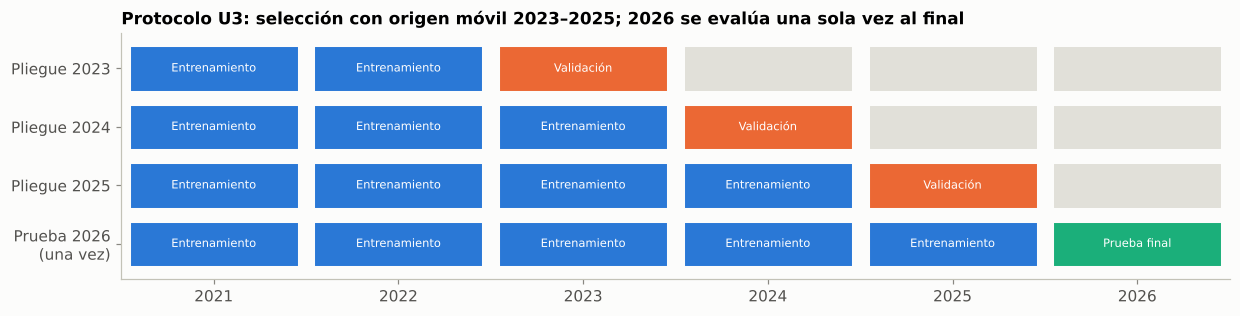

In [7]:
# =============================================================================
# 3.2 Herramientas de evaluación: semillas pareadas, regla de retención y caché de resultados
# =============================================================================
SEM5 = (1, 2, 3, 4, 5)
RES = {}          # nombre -> {"oos": predicciones, "por_semilla": métricas, "P": matriz semillas x filas}

def evaluar(spec, semillas=SEM5, particiones="movil", base=None, seq=None, clave=None):
    # La lógica está en pipeline.evaluar_semillas (cada semilla por separado en cada pliegue); aquí solo se guarda
    # el resultado en la caché RES para compararlo después.
    base = datos if base is None else base; seq = SEQ if seq is None else seq
    RES[clave or spec.nombre] = P.evaluar_semillas(spec, base, seq, semillas, particiones)
    return RES[clave or spec.nombre]

def resumen(claves, ensamble=False):
    # Tabla media ± desv. entre semillas (o métricas del ensamble de semillas si ensamble=True).
    filas = {}
    for k in claves:
        r = RES[k]
        if ensamble:
            filas[k] = E.metricas(r["oos"]["y"], r["oos"]["p"], transicion=r["oos"]["transicion"])
        else:
            ps = r["por_semilla"]
            filas[k] = {**{c: ps[c].mean() for c in E.COLS_PRINCIPALES}, "Log-loss (DE)": ps["Log-loss"].std(ddof=1) if len(ps) > 1 else 0.0,
                        "Transiciones acertadas": ps["Transiciones acertadas"].mean(), "Transiciones": ps["Transiciones"].iloc[0]}
    return pd.DataFrame(filas).T

def decidir(candidata, referencia, nombre=None):
    # Regla de retención (§3.1, regla 5) con diferencias pareadas por semilla; la regla vive en el paquete.
    a, b = RES[candidata]["por_semilla"], RES[referencia]["por_semilla"]
    r = E.regla_retencion(a["Log-loss"].values, b["Log-loss"].values, a["ROC-AUC"].values, b["ROC-AUC"].values)
    # IC 95 % de la misma diferencia remuestreando departamentos (muestreo de territorios, no solo de semillas)
    oa, ob = RES[candidata].get("oos"), RES[referencia].get("oos")
    ic = "–"
    if oa is not None and ob is not None and "P" in RES[candidata] and "P" in RES[referencia] \
            and len(oa) == len(ob) and (oa["fila"].values == ob["fila"].values).all():
        c = E.ic_pareado_semillas(oa["y"], RES[candidata]["P"], RES[referencia]["P"], oa["depto"])
        ic = f"[{c['IC95 inf']:+.3f}; {c['IC95 sup']:+.3f}]".replace(".", ",")
    return {"Intervención": nombre or candidata, "Referencia": referencia, "ΔLog-loss": r["ΔLog-loss"], "EE": r["EE"],
            "IC95 Δ (depto)": ic, "ΔAUC": r["ΔAUC"], "Decisión": "se retiene" if r["retiene"] else "no se retiene"}

def persistencia_oos(particiones="movil", base=None, calibrada=False):
    base = datos if base is None else base
    fn_p = P.persistencia_calibrada if calibrada else P.persistencia
    return E.validar(base, lambda tr, te: {"p": fn_p(base, tr, te)}, E.particiones(particiones, base))

PERS = persistencia_oos()
M_PERS = E.metricas(PERS["y"], PERS["p"], transicion=PERS["transicion"])
PERS_CAL = persistencia_oos(calibrada=True)      # rival agregado tras la revisión (no interviene en la selección)
M_PERS_CAL = E.metricas(PERS_CAL["y"], PERS_CAL["p"], transicion=PERS_CAL["transicion"])
print(f"Persistencia, origen móvil 2023-2025 (n = {len(PERS)}): AUC {M_PERS['ROC-AUC']:.3f} | log-loss {M_PERS['Log-loss']:.3f} | "
      f"Brier {M_PERS['Brier']:.3f} | transiciones acertadas {M_PERS['Transiciones acertadas']} de {M_PERS['Transiciones']}")
print(f"Persistencia calibrada (logística sobre logit(m1), años anteriores): AUC {M_PERS_CAL['ROC-AUC']:.3f} | "
      f"log-loss {M_PERS_CAL['Log-loss']:.3f} | Brier {M_PERS_CAL['Brier']:.3f} | ECE {M_PERS_CAL['ECE']:.3f}")

fig, ax = plt.subplots(figsize=(13, 2.9))
for fila, v in enumerate((2023, 2024, 2025, 2026)):
    for anio in range(2021, 2027):
        rol = ("Entrenamiento", COL["train"]) if anio < v else (("Validación" if v < 2026 else "Prueba final"), COL["val"] if v < 2026 else COL["test"]) if anio == v else ("", GRID)
        ax.add_patch(Rectangle((anio - .46, 3 - fila - .4), .92, .8, facecolor=rol[1], edgecolor=FONDO, lw=2))
        if rol[0]:
            ax.text(anio, 3 - fila, rol[0], ha="center", va="center", fontsize=7.5, color="white" if rol[1] != GRID else TINTA)
ax.set_yticks(range(4), ["Prueba 2026\n(una vez)", "Pliegue 2025", "Pliegue 2024", "Pliegue 2023"])
ax.set_xticks(range(2021, 2027)); ax.set_xlim(2020.5, 2026.5); ax.set_ylim(-.6, 3.6); ax.grid(False)
ax.set_title("Protocolo U3: selección con origen móvil 2023–2025; 2026 se evalúa una sola vez al final")
guardar(fig, "fig03_protocolo"); plt.show()

---
# 4. Línea base de la U2 reproducida

Antes de intervenir comprobamos que el modelo base de la U2 se reproduce con el paquete nuevo. Primero con el mismo
protocolo de la U2 (origen móvil 2023–2026, semilla 42, 560 pasos), contra las cifras guardadas en
`referencias_u2/`. Después, con el protocolo de esta unidad (2023–2025, 5 semillas), que es la línea "antes" de §9.

In [8]:
# =============================================================================
# 4.1 Reproducción con el protocolo de la U2 (2023-2026) y con el de la U3 (2023-2025)
# =============================================================================
CFG_U2 = M.ConfigRed()                                       # 7 -> 16 ReLU -> 1, L2 1e-3, Adam 1e-3, lote 16, 560 pasos
BASE_U2 = P.Especificacion("MLP base U2", V.BASE, CFG_U2)
LOG_BASE = P.Especificacion("Logística base", V.BASE, None)

def fn_u2(tr, te):
    out = {"Persistencia": P.persistencia(datos, tr, te)}
    for s in (replace(BASE_U2, semillas=(C.SEED,)), LOG_BASE):
        m_, e_ = P.entrenar_especificacion(datos, SEQ, s, tr)
        out[s.nombre] = P.predecir_especificacion(m_, e_, datos, SEQ, s, te)
    return out
OOS_U2 = E.validar(datos, fn_u2, E.particiones_origen_movil(datos, (2023, 2024, 2025, 2026)))
rep = E.resumir(OOS_U2, ["MLP base U2", "Logística base", "Persistencia"])[["ROC-AUC", "Log-loss", "Brier", "Exactitud", "MCC"]]
doc = pd.read_csv(RAIZ / "referencias_u2" / "experimento_E1_memoria.csv").query("Validación == 'Temporal'").set_index("Modelo")
doc = doc.rename(index={"MLP base (x1-x7)": "MLP base U2", "Logística base (x1-x7)": "Logística base"}).loc[rep.index, ["ROC-AUC", "Log-loss", "Brier", "Exactitud", "MCC"]]
comp_rep = pd.concat({"Documentado en la U2": doc, "Reproducido (U3)": rep}, axis=1)
tabla(comp_rep, dec=3)
DIF_REP = float((comp_rep["Reproducido (U3)"] - comp_rep["Documentado en la U2"]).abs().max().max())
print(f"Diferencia máxima entre lo documentado y lo reproducido: {DIF_REP:.4f}")

# Protocolo U3
evaluar(BASE_U2); evaluar(LOG_BASE)
evaluar(P.Especificacion("U2 E1 (memoria cruda x8)", V.BASE + ["x8_memoria_C"], CFG_U2))
tabla(pd.concat([resumen(["MLP base U2", "Logística base", "U2 E1 (memoria cruda x8)"]),
                 pd.DataFrame({**{c: M_PERS[c] for c in E.COLS_PRINCIPALES}, "Transiciones acertadas": 0,
                               "Transiciones": M_PERS["Transiciones"]}, index=["Persistencia"])]), dec=3)

Diferencia máxima entre lo documentado y lo reproducido: 0.0015


,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Log-loss (DE),Transiciones acertadas,Transiciones
MLP base U2,"0,921","0,383","0,123","0,632","0,808","0,086","0,021","2,400",9
Logística base,"0,903","0,412","0,131","0,660","0,828","0,063","0,000",3,9
U2 E1 (memoria cruda x8),"0,938","0,347","0,110","0,664","0,826","0,088","0,009","2,400",9
Persistencia,"0,973","0,363","0,106","0,795","0,897","0,173",–,"0,000",9


**Lectura.** La reproducción es casi exacta. La logística y la persistencia coinciden al dígito con la U2, y el MLP
difiere en 0,0015 de AUC (0,894 vs. 0,892), lo esperable al pasar de Windows a Linux con el mismo TensorFlow
2.21. Con el protocolo de la U3 (2023–2025, 5 semillas), el punto de partida es:

* **El MLP base (log-loss 0,383 ± 0,021) pierde contra la persistencia (0,363)**, y también en AUC (0,921 vs. 0,973).
  Es el problema que esta unidad debe resolver.
* El experimento E1 de la U2 (memoria cruda $x_8$) ya baja la log-loss a 0,347 y supera a la persistencia. Lo
  confirmamos con más semillas y un protocolo más estricto: la memoria es la palanca correcta.
* El modelo base acierta en promedio 2,4 de las 9 transiciones de 2023–2025. La persistencia acierta 0.

---
# 5. Diagnóstico de la U2 → plan de intervención

Cada intervención responde a un hallazgo medido en la U2 y tiene una hipótesis que puede fallar. La columna "qué
la refutaría" se escribió antes de ejecutar los experimentos.

| # | Diagnóstico U2 (evidencia) | Intervención | Hipótesis | Qué la refutaría |
|---|---|---|---|---|
| I1 | La inercia domina: persistencia AUC 0,965; 57 % de los errores son transiciones | Memoria $m_1$–$m_3$ | Se acerca a la persistencia y la supera en log-loss | ΔLL dentro del ruido entre semillas |
| I2 | Solo vista anual; los errores de 2025 son escaladas recientes | Dinámica intra-anual $d_1$–$d_3$ | Mejora en transiciones | Sin ganancia en transiciones ni en LL |
| I3 | Arauca: C los seis años con P ≈ 0,36; falta $x_3$ | Actores armados (UCDP) | Corrige departamentos con actor dominante | Arauca sigue mal clasificada |
| I4 | Sin información espacial; validación espacial débil | Vecindad $v_1$, $v_2$ | Mejora la validación espacial | Sin mejora espacial |
| I5 | 20 % de las celdas a ±10 pp del umbral | Objetivo blando ($s^C$) ponderado por eventos | Menos ruido de etiqueta, mejor LL | LL peor incluso tras calibrar |
| I6 | 4 neuronas mejor que 16 a largo plazo; brecha sin cerrar | Capacidad, activación, L2 y presupuesto, con validación anidada | Baja la varianza | Lo elegido no transfiere al año siguiente |
| I7 | AUC 0,848 ± 0,024 entre semillas | Ensamble de semillas | Estabilidad | Sin reducción de dispersión |
| I8 | Subestima P(C); el umbral F2 no se transfiere | Calibración (Platt / temperatura) y umbral multianual | Mejor Brier y umbral estable | La calibración no mejora fuera de muestra |
| I9 | A/B nunca dominan: la etiqueta binaria las diluye | Salida multitarea de composición A/B/C/D | Alerta A/B modelada | No supera a la persistencia de la composición |
| – | Arquitectura MLP sin estructura temporal | Comparativos: GRU, CNN 1D, embedding de departamento | Una arquitectura secuencial aprovecha los trimestres | No ganan al MLP con las mismas variables |

Las intervenciones sobre **variables** (I1–I4) se aplican en cascada: cada una se evalúa sobre la mejor
especificación retenida hasta ese momento. Las de **modelo** (I5–I9) se evalúan después sobre el conjunto de
variables ya fijado, para no mezclar efectos.

---
# 6. Intervenciones incrementales

Cada experimento entrena la variante con las mismas 5 semillas que su referencia y la evalúa en los tres pliegues
de origen móvil. Se reportan la **media entre semillas** (lo que vale una red individual) y la decisión de la
regla 5 de §3.1. El ensamble de semillas se estudia aparte en I7, para no confundir su efecto con el de las
variables.

## 6.1 I1: memoria del perfil

In [9]:
# =============================================================================
# 6.1 I1 memoria: m1 (s_C contraída de t-1) y la trayectoria m1, m2, m3
# =============================================================================
DECISIONES, ESCALERA = [], [("Modelo base U2", "MLP base U2")]
evaluar(P.Especificacion("I1a +m1", V.BASE + ["m1_sC_t1"], CFG_U2))
evaluar(P.Especificacion("I1b +m1 m2 m3", V.BASE + V.MEMORIA, CFG_U2))
VARS, REF = list(V.BASE), "MLP base U2"
d = decidir("I1a +m1", REF, "I1 memoria m1"); DECISIONES.append(d)
if d["Decisión"] == "se retiene":
    VARS, REF = VARS + ["m1_sC_t1"], "I1a +m1"; ESCALERA.append(("+ I1 memoria m₁", REF))
d = decidir("I1b +m1 m2 m3", REF, "I1 trayectoria m2, m3"); DECISIONES.append(d)
if d["Decisión"] == "se retiene":
    VARS, REF = list(V.BASE) + V.MEMORIA, "I1b +m1 m2 m3"; ESCALERA.append(("+ I1 trayectoria", REF))
tabla(resumen(["MLP base U2", "U2 E1 (memoria cruda x8)", "I1a +m1", "I1b +m1 m2 m3"]), dec=3)
display(pd.DataFrame(DECISIONES).style.format({"ΔLog-loss": "{:+.4f}", "EE": "{:.4f}", "ΔAUC": "{:+.4f}"}).hide(axis="index"))
print("Variables retenidas tras I1:", [v for v in VARS if v not in V.BASE])

,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Log-loss (DE),Transiciones acertadas,Transiciones
MLP base U2,"0,921","0,383","0,123","0,632","0,808","0,086","0,021","2,400",9
U2 E1 (memoria cruda x8),"0,938","0,347","0,110","0,664","0,826","0,088","0,009","2,400",9
I1a +m1,"0,939","0,347","0,110","0,664","0,826","0,084","0,010","2,400",9
I1b +m1 m2 m3,"0,938","0,349","0,108","0,681","0,838","0,086","0,025","1,600",9


Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
I1 memoria m1,MLP base U2,-0.0358,0.0094,"[-0,056; -0,019]",+0.0174,se retiene
"I1 trayectoria m2, m3",I1a +m1,+0.0016,0.0110,"[-0,036; +0,055]",-0.0001,no se retiene


Variables retenidas tras I1: ['m1_sC_t1']


**Lectura.**

* **I1 se retiene.** Agregar $m_1$ baja la log-loss media de 0,383 a 0,347 (Δ = −0,036, más de tres errores
  estándar, EE = 0,009; IC 95 % remuestreando departamentos [−0,056; −0,019]) y sube el AUC de 0,921 a 0,939. Con esto la red individual ya supera a la persistencia en
  log-loss (0,347 vs. 0,363).
* **La trayectoria ($m_2$, $m_3$) no aporta** (Δ = +0,002, dentro del ruido): lo que importa es el estado reciente,
  no la pendiente. Se descarta por la regla de la variante más simple.
* **Contracción vs. memoria cruda.** $m_1$ contraída y $x_8$ cruda dan la misma log-loss (0,347). Era lo esperado:
  casi todas las filas de $t-1$ tienen decenas de eventos y la contracción apenas las mueve. Su efecto se mide en §7,
  donde la cuidan las variables semestrales con menos eventos.
* **Hipótesis.** Se confirma que la memoria acerca la red a la persistencia y la supera en log-loss. No se confirma
  que mejore las transiciones: se mantienen en 2,4 de 9.

## 6.2 I2: dinámica intra-anual

In [10]:
# =============================================================================
# 6.2 I2 dinámica intra-anual sobre la especificación retenida
# =============================================================================
evaluar(P.Especificacion("I2a +d1", VARS + ["d1_sC_H2"], CFG_U2))
evaluar(P.Especificacion("I2b +d1 d2 d3", VARS + V.DINAMICA, CFG_U2))
ref_i2 = REF
d = decidir("I2a +d1", REF, "I2 semestre reciente d1"); DECISIONES.append(d)
if d["Decisión"] == "se retiene":
    VARS, REF = VARS + ["d1_sC_H2"], "I2a +d1"; ESCALERA.append(("+ I2 semestre d₁", REF))
d = decidir("I2b +d1 d2 d3", REF, "I2 tendencias d2, d3"); DECISIONES.append(d)
if d["Decisión"] == "se retiene":
    VARS, REF = [v for v in VARS if v != "d1_sC_H2"] + V.DINAMICA, "I2b +d1 d2 d3"; ESCALERA.append(("+ I2 tendencias", REF))
tabla(resumen([ref_i2, "I2a +d1", "I2b +d1 d2 d3"]), dec=3)
display(pd.DataFrame(DECISIONES[-2:]).style.format({"ΔLog-loss": "{:+.4f}", "EE": "{:.4f}", "ΔAUC": "{:+.4f}"}).hide(axis="index"))

# ¿Dónde aporta? Log-loss por año y aciertos en transiciones
por_anio = pd.DataFrame({k: RES[k]["oos"].assign(p=RES[k]["P"].mean(0)).groupby("particion").apply(lambda g: E.bce(g.y, g.p))
                         for k in ["MLP base U2", "I1a +m1", "I2a +d1"]})
por_anio["Persistencia"] = PERS.groupby("particion").apply(lambda g: E.bce(g.y, g.p))
tabla(por_anio.T.rename(columns=str), dec=3)
print("Variables retenidas tras I2:", [v for v in VARS if v not in V.BASE])

,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Log-loss (DE),Transiciones acertadas,Transiciones
I1a +m1,"0,939","0,347","0,110","0,664","0,826","0,084","0,010","2,400",9
I2a +d1,"0,951","0,310","0,097","0,740","0,865","0,077","0,010",2,9
I2b +d1 d2 d3,"0,945","0,323","0,102","0,691","0,842","0,071","0,012","2,200",9


Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
I2 semestre reciente d1,I1a +m1,-0.0374,0.0068,"[-0,066; -0,011]",+0.0127,se retiene
"I2 tendencias d2, d3",I2a +d1,+0.0130,0.0087,"[-0,030; +0,071]",-0.0059,no se retiene


particion,2023,2024,2025
MLP base U2,"0,367","0,316","0,434"
I1a +m1,"0,351","0,272","0,386"
I2a +d1,"0,313","0,224","0,362"
Persistencia,"0,344","0,346","0,399"


Variables retenidas tras I2: ['m1_sC_t1', 'd1_sC_H2']


**Lectura.**

* **I2 se retiene.** El semestre reciente $d_1$ baja la log-loss de 0,347 a **0,310** (Δ = −0,037; EE = 0,007; IC 95 %
  por departamento [−0,066; −0,011]) y sube el AUC a 0,951. El intervalo no incluye el cero aunque se remuestreen
  territorios, no solo semillas. Es la mayor ganancia individual de la unidad, y el EDA anticipaba por qué: $d_1$ registra los
  giros de la segunda mitad del año que el promedio anual diluye.
* **Las tendencias $d_2$, $d_3$ empeoran** (Δ = +0,013): con 113–142 filas, dos variables de ruido cuestan más de lo
  que aportan. Se descartan.
* **La ganancia es general, no solo en 2025.** Por año, la red con $m_1 + d_1$ supera a la persistencia en log-loss en
  los tres pliegues (2023: 0,313 vs. 0,344; 2024: 0,224 vs. 0,346; 2025: 0,362 vs. 0,399). El modelo base solo lo
  lograba en 2024.
* **Hipótesis parcialmente refutada.** Esperábamos que I2 mejorara las transiciones, y no lo hizo (2,0 de 9 frente a
  2,4). $d_1$ mejora la confianza en los perfiles estables más que la detección de cambios. Las transiciones siguen
  siendo el límite del modelo (§10).

## 6.3 I3: actores armados activos ($x_3$, UCDP GED)

$x_3$ está pendiente desde la Etapa 1, porque el export gratuito de ACLED no trae actores. La fuente sustituta
verificada es **UCDP GED 26.1** (`ged261-csv.zip`, archivo `GEDEvent_v26_1.csv`, 39 MB). Cubre Colombia hasta 2025,
trae `adm_1` en el 99,8 % de los eventos desde 2020 y registra los dos bandos (`side_a`, `side_b`). La variable cuenta
los actores **no estatales** distintos por departamento–año: excluye gobiernos y "Civilians" y separa pares como
"ELN, FARC-EMC". Como UCDP solo registra violencia organizada letal, es un indicador **aproximado** de grupos
activos.

Como el archivo completo pesa 39 MB, el repositorio incluye `herramientas/preparar_ucdp.py`. El script lo reduce a
Colombia (`ucdp_colombia.csv`, unos cientos de KB) y a $x_3$ ya agregado (`ucdp_actores_departamento_anio.csv`, unos
pocos KB). La celda siguiente corre I3 si cualquiera de esos archivos está en `datos/externos/`. Si no está, lo declara
y sigue: el resto del cuaderno no depende de esta intervención.

In [11]:
# =============================================================================
# 6.3 I3 actores armados (condicionada a la disponibilidad de UCDP GED)
# =============================================================================
if ACTORES is not None and "x3_actores" in datos:
    evaluar(P.Especificacion("I3 +x3", VARS + ["x3_actores"], CFG_U2))
    d = decidir("I3 +x3", REF, "I3 actores armados x3"); DECISIONES.append(d)
    tabla(resumen([REF, "I3 +x3"]), dec=3)
    display(pd.DataFrame([d]).style.hide(axis="index"))
    ar = RES["I3 +x3"]["oos"].assign(p_x3=RES["I3 +x3"]["P"].mean(0), p_ref=RES[REF]["P"].mean(0)).query("depto == 'arauca'")
    display(ar[["departamento", "anio", "perfil", "p_ref", "p_x3"]])
    if d["Decisión"] == "se retiene":
        VARS, REF = VARS + ["x3_actores"], "I3 +x3"; ESCALERA.append(("+ I3 actores x₃", REF))
    I3_ESTADO = "evaluada"
else:
    I3_ESTADO = "pendiente de fuente"
    DECISIONES.append({"Intervención": "I3 actores armados x3", "Referencia": REF, "ΔLog-loss": np.nan, "EE": np.nan,
                       "ΔAUC": np.nan, "Decisión": "pendiente: UCDP GED no disponible en esta ejecución"})
    display(Markdown("**I3 no se ejecutó:** `GEDEvent_v26_1.csv` no está en `datos/externos/`. Descárguelo de "
                     "https://ucdp.uu.se/downloads/ged/ged261-csv.zip, cópielo en esa carpeta y vuelva a ejecutar el cuaderno."))

,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Log-loss (DE),Transiciones acertadas,Transiciones
I2a +d1,"0,951","0,310","0,097","0,740","0,865","0,077","0,010",2,9
I3 +x3,"0,937","0,335","0,105","0,684","0,840","0,064","0,020","1,400",9


Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
I3 actores armados x3,I2a +d1,0.024955,0.005638,"[-0,002; +0,063]",-0.014482,no se retiene


,departamento,anio,perfil,p_ref,p_x3
2,Arauca,2023,C,0.823462,0.907339
31,Arauca,2024,C,0.742372,0.815017
60,Arauca,2025,C,0.837484,0.842019


**Lectura.** **I3 se rechaza.** Con UCDP GED (843 filas departamento–año), $x_3$ empeora el modelo: la log-loss sube de
0,310 a **0,335** (Δ = +0,025, unas 4 veces su EE), el AUC baja de 0,951 a 0,937 y las transiciones acertadas pasan
de 2,0 a 1,4. Tres razones lo explican:

* **Redundancia.** El número de actores se asocia con el perfil C (ρ = 0,46), pero casi todo lo que aporta ya está en
  las fatalidades (ρ = 0,77 con $x_3$) y en la memoria. Agrega una dimensión más sin información nueva.
* **Ruido conceptual.** UCDP cuenta toda organización armada con muertes, incluidas bandas urbanas. Atlántico, que es
  D todos los años, pasa de 0 a 3 actores desde 2023 (Los Costeños, Los Pepes). Esas bandas no producen un perfil
  convencional en el sentido de la U1.
* **Cambio de cobertura.** UCDP registra 173 eventos en Colombia en 2022 y 422 en 2023. Parte del salto es de
  codificación, no de conflicto, y la variable deriva justo dentro de la ventana de validación.

El caso que motivaba $x_3$ ya estaba resuelto: Arauca, mal clasificada todos los años en la U2 (P ≈ 0,36), recibe
P(C) entre 0,74 y 0,84 sin $x_3$ (entre 0,82 y 0,91 con ella). La memoria del perfil capta de forma indirecta la
presencia sostenida del ELN. Los actores pueden importar; lo que no funcionó fue medirlos con un conteo anual
departamental. A escala municipal, el cambio en los actores presentes (entradas y
salidas de grupos) es la versión que vale la pena probar (R2, §13).

## 6.4 I4: vecindad espacial

La hipótesis de I4 es **espacial**: la composición de los vecinos debería ayudar sobre todo con departamentos que el
modelo nunca vio. Por eso la evaluamos con los dos protocolos de la U2, el temporal y el espacial (5 pliegues
agrupados por departamento, años hasta 2025). Se retiene si mejora la validación espacial según la regla 5 sin
empeorar la temporal.

In [12]:
# =============================================================================
# 6.4 I4 vecindad: validación temporal y espacial
# =============================================================================
spec_ref, ref_i4 = RES[REF]["spec"], REF
evaluar(P.Especificacion("I4 +v1 v2", VARS + V.VECINDAD, CFG_U2))
d_t = decidir("I4 +v1 v2", REF, "I4 vecindad (temporal)")
for k, s in [("esp: MLP base U2", BASE_U2), ("esp: referencia", spec_ref), ("esp: I4 +v1 v2", RES["I4 +v1 v2"]["spec"]),
             ("esp: logística base", LOG_BASE), ("esp: logística referencia", P.Especificacion("lr", VARS, None))]:
    evaluar(replace(s, nombre=k), particiones="espacial", clave=k)
PERS_E = persistencia_oos("espacial")
d_e = decidir("esp: I4 +v1 v2", "esp: referencia", "I4 vecindad (espacial)")
retener_i4 = d_e["Decisión"] == "se retiene" and d_t["ΔLog-loss"] < d_t["EE"]
d_t["Decisión"] = d_e["Decisión"] = "se retiene" if retener_i4 else "no se retiene"
DECISIONES += [d_t, d_e]
if retener_i4:
    VARS, REF = VARS + V.VECINDAD, "I4 +v1 v2"; ESCALERA.append(("+ I4 vecindad", REF))
esp = resumen(["esp: MLP base U2", "esp: logística base", "esp: referencia", "esp: logística referencia", "esp: I4 +v1 v2"])
M_PERS_E = E.metricas(PERS_E.y, PERS_E.p)
esp.loc["esp: persistencia", E.COLS_PRINCIPALES] = [M_PERS_E[c] for c in E.COLS_PRINCIPALES]
tabla(pd.concat({"Temporal 2023-2025": resumen([ref_i4, "I4 +v1 v2"])[E.COLS_PRINCIPALES],
                 "Espacial (deptos. nunca vistos)": esp[E.COLS_PRINCIPALES]}), dec=3)
display(pd.DataFrame([d_t, d_e]).style.format({"ΔLog-loss": "{:+.4f}", "EE": "{:.4f}", "ΔAUC": "{:+.4f}"}).hide(axis="index"))
VARS_FINAL, REF_VARS = list(VARS), REF
print(f"Especificación de variables fijada ({len(VARS_FINAL)}):", VARS_FINAL)

Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
I4 vecindad (temporal),I2a +d1,-0.0040,0.0019,"[-0,035; +0,027]",+0.0020,no se retiene
I4 vecindad (espacial),esp: referencia,+0.0094,0.0037,"[-0,023; +0,046]",-0.0054,no se retiene


Especificación de variables fijada (9): ['x1_eventos', 'x2_fatalidades', 'x2b_letalidad', 'x4_coca', 'x5_bosque', 'x6_distancia', 'x7_ipm', 'm1_sC_t1', 'd1_sC_H2']


**Lectura.**

* I4 no se retiene. Su hipótesis era espacial, así que la regla se aplica a la validación espacial: ahí la vecindad
  empeora (log-loss 0,389 frente a 0,379; Δ = +0,009). En el eje temporal da una mejora mínima (Δ = −0,004, unas 2
  veces su EE), que por sí sola cumpliría la regla. Con 30 departamentos, la composición de los vecinos suma colinealidad
  con la memoria propia sin aportar información que se transfiera.
* El hallazgo espacial importante es otro. Con $m_1 + d_1$, la red individual pasa de log-loss 0,475 (modelo base) a
  0,379 en departamentos nunca vistos, y el AUC de 0,854 a 0,914. En la U2 las variables estructurales casi constantes
  funcionaban como identificadores; con información de composición la red ya no necesita memorizar firmas
  departamentales. §9.2 repite la comparación con un esquema que además respeta el tiempo.
* La logística con las mismas variables queda empatada en este eje (0,373).

## 6.5 I5: objetivo blando ponderado por eventos

En lugar de la etiqueta dura $y = \mathbb{1}[s^C \ge 0{,}5]$, la red aprende directamente $s^C_{d,t}$, con la
entropía cruzada aplicada a un objetivo continuo, opcionalmente ponderada por $\sqrt{n_{d,t}}$. La idea es que una
celda con $s^C = 0{,}51$ no le "enseñe" lo mismo que una con $s^C = 0{,}95$. La salida pasa a estimar la
**proporción esperada**, no la probabilidad de que la proporción supere 0,5. Por eso la comparación justa es después
de **calibrar** ambas variantes con el mismo método (temperatura con encadenamiento hacia adelante: el pliegue $v$
se calibra solo con los pliegues anteriores).

In [13]:
# =============================================================================
# 6.5 I5 objetivo blando (con y sin ponderación por eventos), crudo y calibrado
# =============================================================================
def calibrar_adelante(oos, p, metodo="temperatura"):
    # Calibración con encadenamiento hacia adelante (modelo.calibrar_adelante): el pliegue v se calibra con los pliegues < v.
    return M.calibrar_adelante(oos["particion"].values, p, oos["y"].values, metodo)

def registrar_calibrado(clave, metodo="temperatura"):
    r = RES[clave]; oos = r["oos"]
    Pc = np.array([calibrar_adelante(oos, p, metodo) for p in r["P"]])
    filas = [{"semilla": s, **E.metricas(oos.y, pc, transicion=oos.transicion)} for s, pc in zip(r["por_semilla"].index, Pc)]
    RES[clave + " · cal"] = {"oos": oos.assign(p=Pc.mean(0)), "por_semilla": pd.DataFrame(filas).set_index("semilla"), "P": Pc, "spec": r["spec"]}

CFG_REF = RES[REF_VARS]["spec"].red
evaluar(P.Especificacion("I5 blando", VARS_FINAL, replace(CFG_REF, objetivo="blando")))
evaluar(P.Especificacion("I5 blando + peso eventos", VARS_FINAL, replace(CFG_REF, objetivo="blando", peso_eventos="raiz")))
for k in (REF_VARS, "I5 blando", "I5 blando + peso eventos"):
    registrar_calibrado(k)
d_crudo = decidir("I5 blando", REF_VARS, "I5 objetivo blando (sin calibrar)")
d_cal = decidir("I5 blando · cal", REF_VARS + " · cal", "I5 objetivo blando (ambos calibrados)")
DECISIONES += [d_crudo, d_cal]
OBJETIVO = "blando" if d_cal["Decisión"] == "se retiene" else "duro"
tabla(resumen([REF_VARS, "I5 blando", "I5 blando + peso eventos", REF_VARS + " · cal", "I5 blando · cal", "I5 blando + peso eventos · cal"]), dec=3)
display(pd.DataFrame([d_crudo, d_cal]).style.format({"ΔLog-loss": "{:+.4f}", "EE": "{:.4f}", "ΔAUC": "{:+.4f}"}).hide(axis="index"))
print("Objetivo de entrenamiento elegido:", OBJETIVO)

,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Log-loss (DE),Transiciones acertadas,Transiciones
I2a +d1,"0,951","0,310","0,097","0,740","0,865","0,077","0,010",2,9
I5 blando,"0,947","0,429","0,132","0,731","0,861","0,172","0,003","2,800",9
I5 blando + peso eventos,"0,945","0,431","0,135","0,709","0,847","0,159","0,007","2,400",9
I2a +d1 · cal,"0,944","0,317","0,099","0,740","0,865","0,069","0,020",2,9
I5 blando · cal,"0,929","0,385","0,117","0,731","0,861","0,110","0,035","2,800",9
I5 blando + peso eventos · cal,"0,929","0,401","0,123","0,709","0,847","0,113","0,033","2,400",9


Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
I5 objetivo blando (sin calibrar),I2a +d1,+0.1193,0.0044,"[+0,054; +0,184]",-0.0044,no se retiene
I5 objetivo blando (ambos calibrados),I2a +d1 · cal,+0.0678,0.0078,"[+0,028; +0,107]",-0.0152,no se retiene


Objetivo de entrenamiento elegido: duro


**Lectura.** **I5 se rechaza.** Sin calibrar, el objetivo blando empeora mucho la log-loss (0,429 vs. 0,310). Era lo
previsto: la red aprende la proporción esperada, que se concentra cerca de 0,5, y no la probabilidad de cruzar el
umbral. Incluso después de calibrar ambas variantes con el mismo método, sigue peor (0,385 vs. 0,317) y pierde AUC
(0,929 vs. 0,944). La ponderación por $\sqrt{n}$ no ayuda. Concluimos que el ruido de etiqueta cerca del umbral no es
lo que limita al modelo: la etiqueta dura de la U1 se mantiene, y con ella la trazabilidad de la variable objetivo.

## 6.6 I9: salida multitarea de composición A/B/C/D

La etiqueta binaria diluye el hallazgo crítico de la U1: explosivos (A) y drones (B) son de bajo volumen y alto
impacto. Agregamos a la red una **segunda cabeza softmax** que predice la composición completa
$(s^A, s^B, s^C, s^D)_{d,t}$, con un tronco oculto compartido:

$$
\mathcal{L} = \underbrace{\mathrm{BCE}(y, \hat p)}_{\text{perfil C}} \;+\; \lambda \cdot
\underbrace{\sum_k s^k \log \frac{s^k}{\hat s^k}}_{\mathrm{KL}(\mathbf s \,\|\, \hat{\mathbf s})} \;+\; \lambda_2 \lVert \mathbf W \rVert^2 .
$$

Se evalúa de dos formas: (1) si la tarea auxiliar ayuda o perjudica a $\hat p$ (regla 5) y (2) si la composición
predicha anticipa la **alerta A/B** mejor que repetir la composición del año anterior.

In [14]:
# =============================================================================
# 6.6 I9 multitarea: efecto sobre P(C) y calidad de la composición predicha
# =============================================================================
for lam in (0.5, 1.0):
    evaluar(P.Especificacion(f"I9 multitarea λ={lam:g}", VARS_FINAL, replace(CFG_REF, tipo="multitarea", lambda_comp=lam, objetivo=OBJETIVO)))
d9 = [decidir(f"I9 multitarea λ={lam:g}", REF_VARS, f"I9 multitarea λ={lam:g} (efecto en P(C))") for lam in (0.5, 1.0)]

# Composición fuera de muestra (ensamble de 5 semillas por pliegue)
spec9 = replace(RES["I9 multitarea λ=0.5"]["spec"], semillas=SEM5)
comp_oos = []
for v, tr, te in E.particiones_origen_movil(datos):
    m_, e_ = P.entrenar_especificacion(datos, SEQ, spec9, tr)
    comp_oos.append(P.predecir_especificacion(m_, e_, datos, SEQ, spec9, te, composicion=True))
comp_oos = np.concatenate(comp_oos)
te_ = datos.anio.isin(C.ANIOS_SELECCION).values
real = datos.loc[te_, V.COMPOSICION].values
prev_ab = datos.loc[te_, ["depto", "anio"]].merge(pext[["depto", "anio", "s_A", "s_B"]].assign(anio=lambda d: d.anio + 1), on=["depto", "anio"], how="left")
sAB_real, sAB_pers, sAB_mod = real[:, 0] + real[:, 1], (prev_ab.s_A + prev_ab.s_B).fillna(0).values, comp_oos[:, 0] + comp_oos[:, 1]
umbral_ab = pd.Series(sAB_real).groupby(datos.loc[te_, "anio"].values).transform(lambda s: 2 * s.mean()).values
alto_ab = sAB_real >= umbral_ab
calidad = pd.DataFrame({
    "Modelo multitarea (λ=0,5)": [np.mean(np.abs(sAB_mod - sAB_real)), stats.spearmanr(sAB_mod, sAB_real).correlation, roc_auc_score(alto_ab, sAB_mod)],
    "Persistencia de la composición": [np.mean(np.abs(sAB_pers - sAB_real)), stats.spearmanr(sAB_pers, sAB_real).correlation, roc_auc_score(alto_ab, sAB_pers)]},
    index=["MAE de s_A + s_B", "ρ de Spearman con s_A + s_B real", "AUC para detectar alerta A/B (≥ 2× media del año)"])
I9_COMPOSICION_GANA = calidad.iloc[2, 0] > calidad.iloc[2, 1] and calidad.iloc[0, 0] < calidad.iloc[0, 1]
for x in d9:
    if x["Decisión"] == "se retiene" and not I9_COMPOSICION_GANA:
        x["Decisión"] = "no se retiene (no aporta en P(C) ni en A/B)"
    elif x["Decisión"] != "se retiene" and I9_COMPOSICION_GANA and x["ΔLog-loss"] < x["EE"]:
        x["Decisión"] = "se retiene (no empeora P(C) y anticipa A/B)"
DECISIONES += d9
TIPO = "multitarea" if any(x["Decisión"].startswith("se retiene") for x in d9) else "mlp"
CFG_ACTUAL = RES["I9 multitarea λ=0.5"]["spec"].red if TIPO == "multitarea" else replace(CFG_REF, objetivo=OBJETIVO)
tabla(resumen([REF_VARS, "I9 multitarea λ=0.5", "I9 multitarea λ=1"]), dec=3)
tabla(calidad, dec=3)
display(pd.DataFrame(d9).style.format({"ΔLog-loss": "{:+.4f}", "EE": "{:.4f}", "ΔAUC": "{:+.4f}"}).hide(axis="index"))
print(f"Filas con alerta A/B real en 2023-2025: {alto_ab.sum()} de {len(alto_ab)} | tipo de red elegido: {TIPO}")

,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Log-loss (DE),Transiciones acertadas,Transiciones
I2a +d1,"0,951","0,310","0,097","0,740","0,865","0,077","0,010",2,9
I9 multitarea λ=0.5,"0,951","0,311","0,097","0,740","0,865","0,085","0,009","2,200",9
I9 multitarea λ=1,"0,947","0,319","0,099","0,731","0,861","0,082","0,015","2,400",9


,"Modelo multitarea (λ=0,5)",Persistencia de la composición
MAE de s_A + s_B,"0,035","0,030"
ρ de Spearman con s_A + s_B real,"0,465","0,601"
AUC para detectar alerta A/B (≥ 2× media del año),"0,682","0,700"


Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
I9 multitarea λ=0.5 (efecto en P(C)),I2a +d1,+0.0013,0.0027,"[-0,006; +0,010]",-0.0001,no se retiene
I9 multitarea λ=1 (efecto en P(C)),I2a +d1,+0.0095,0.0052,"[-0,002; +0,023]",-0.0042,no se retiene


Filas con alerta A/B real en 2023-2025: 14 de 87 | tipo de red elegido: mlp


**Lectura.** **I9 se rechaza, y el resultado negativo es informativo.**

* Con λ = 0,5, la tarea auxiliar no perjudica a $\hat p$ (Δ = +0,001), pero tampoco ayuda. Con λ = 1 empeora
  (Δ = +0,010).
* La composición A/B predicha **no supera a la persistencia de la composición**: MAE 0,035 vs. 0,030, ρ = 0,47 vs.
  0,60, y AUC para detectar la alerta A/B de 0,68 vs. 0,70 (14 de las 87 filas tienen alerta).
* La proporción de explosivos y drones de un departamento es tan persistente como su perfil, y la red no encuentra en
  las variables de la U1 nada que anticipe mejor sus cambios. La alerta A/B operativa sigue siendo la regla
  descriptiva de la U2 (proporción observada en 2025–2026 de al menos el doble de la nacional). Modelarla exigiría
  datos por evento y municipio, donde A y B tienen variación suficiente.

## 6.7 Comparativos de arquitectura: ¿una red secuencial o con identidad territorial?

Con las mismas variables tabulares, comparamos el MLP con:

* **GRU** y **CNN 1D** sobre la secuencia de los 4 trimestres de $t-1$ (eventos, fatalidades, $\tilde s^A$,
  $\tilde s^B$, $\tilde s^C$), concatenada a las variables tabulares. Responde si la forma de la trayectoria
  trimestral aporta más que su resumen semestral ($d_1$).
* **Embedding de departamento** (dimensión 2): un vector aprendido por territorio. Captura efectos fijos, pero no
  puede generalizar a departamentos nunca vistos, así que lo evaluamos también en la validación espacial.
* **MLP profundo** (16, 8) y **regresión logística** con las mismas variables (¿aporta la no linealidad?).

In [15]:
# =============================================================================
# 6.7 Comparativos: GRU, CNN 1D, embedding, MLP profundo y logística con las mismas variables
# =============================================================================
comparativos = {
    "GRU trimestral": replace(CFG_REF, tipo="gru", unidades_seq=8),
    "CNN 1D trimestral": replace(CFG_REF, tipo="cnn", unidades_seq=8),
    "Embedding de departamento": replace(CFG_REF, tipo="embedding", emb_dim=2),
    "MLP profundo (16, 8)": replace(CFG_REF, capas=(16, 8)),
}
for k, cfg_k in comparativos.items():
    evaluar(P.Especificacion(k, VARS_FINAL, cfg_k))
LOG_F = P.Especificacion("Logística (mismas variables)", VARS_FINAL, None)
evaluar(LOG_F)
d7 = [decidir(k, REF_VARS, k) for k in [*comparativos, "Logística (mismas variables)"]]
emb = next(x for x in d7 if x["Intervención"] == "Embedding de departamento")
TR_EMB = RES["Embedding de departamento"]["por_semilla"]["Transiciones acertadas"].mean()
TR_REF = RES[REF_VARS]["por_semilla"]["Transiciones acertadas"].mean()
if emb["Decisión"] == "se retiene" and TR_EMB < TR_REF:
    emb["Decisión"] = (f"cumple la regla 5, no se adopta por la regla 8: acierta {TR_EMB:.1f} de {int(M_PERS['Transiciones'])} "
                       f"transiciones (referencia {TR_REF:.1f}) y en departamentos nuevos se reduce al MLP sin embedding")
DECISIONES += d7
evaluar(P.Especificacion("esp: embedding", VARS_FINAL, comparativos["Embedding de departamento"]), particiones="espacial", clave="esp: embedding")
tab7 = resumen([REF_VARS, *comparativos, "Logística (mismas variables)"])
tab7["Parámetros"] = [RES[k]["spec"].red and M.n_parametros(M.construir_red(len(VARS_FINAL), RES[k]["spec"].red, SEQ.shape[1:] if RES[k]["spec"].red.tipo in ("gru", "cnn") else None)) or len(VARS_FINAL) + 1 for k in tab7.index]
tabla(tab7, dec=3)
display(pd.DataFrame(d7).style.format({"ΔLog-loss": "{:+.4f}", "EE": "{:.4f}", "ΔAUC": "{:+.4f}"}).hide(axis="index"))
print(f"Embedding en validación espacial: log-loss {RES['esp: embedding']['por_semilla']['Log-loss'].mean():.3f} "
      f"vs. MLP sin embedding {RES['esp: referencia']['por_semilla']['Log-loss'].mean():.3f}")

,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Log-loss (DE),Transiciones acertadas,Transiciones,Parámetros
I2a +d1,"0,951","0,310","0,097","0,740","0,865","0,077","0,010",2,9,177
GRU trimestral,"0,948","0,319","0,104","0,706","0,849","0,076","0,015","1,800",9,665
CNN 1D trimestral,"0,945","0,324","0,103","0,724","0,858","0,078","0,023","1,800",9,393
Embedding de departamento,"0,968","0,284","0,090","0,732","0,863","0,081","0,018","0,800",9,275
"MLP profundo (16, 8)","0,954","0,309","0,098","0,731","0,863","0,083","0,025","1,600",9,305
Logística (mismas variables),"0,949","0,306","0,097","0,737","0,863","0,068","0,000",1,9,10


Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
GRU trimestral,I2a +d1,+0.0098,0.0045,"[-0,024; +0,053]",-0.0033,no se retiene
CNN 1D trimestral,I2a +d1,+0.0143,0.0142,"[-0,026; +0,062]",-0.0064,no se retiene
Embedding de departamento,I2a +d1,-0.0259,0.0103,"[-0,046; -0,005]",+0.0163,"cumple la regla 5, no se adopta por la regla 8: acierta 0.8 de 9 transiciones (referencia 2.0) y en departamentos nuevos se reduce al MLP sin embedding"
"MLP profundo (16, 8)",I2a +d1,-0.0004,0.0135,"[-0,022; +0,024]",+0.0026,no se retiene
Logística (mismas variables),I2a +d1,-0.0035,0.0043,"[-0,053; +0,059]",-0.0025,no se retiene


Embedding en validación espacial: log-loss 0.369 vs. MLP sin embedding 0.379


**Lectura.**

* GRU (665 parámetros) y CNN 1D (393) empeoran (log-loss 0,319 y 0,324 frente a 0,310). Los cuatro trimestres de
  $t-1$ no contienen más información que su resumen semestral $d_1$, y la red secuencial paga en varianza los
  parámetros extra. Con 4 pasos de tiempo y 142 filas, una arquitectura recurrente no tiene de dónde aprender.
* El MLP profundo (16, 8) empata (Δ = −0,0004; EE = 0,014): la profundidad no aporta, igual que en la U2.
* La logística con las mismas variables empata (0,306 frente a 0,310; Δ = −0,003, EE 0,0043, que no cumple la regla).
  A escala departamental la información nueva pesa más que la flexibilidad del modelo, como en la U2 (§11.4). Mantenemos
  el MLP por lo que muestra §9.2: en departamentos nuevos el ensamble de redes obtiene menos log-loss que la logística,
  aunque con un intervalo que incluye el cero.
* El embedding de departamento es el único que cumple la regla 5 (log-loss 0,284; Δ = −0,026; EE = 0,010). No se adopta
  por la regla 8, que agregamos al encontrar este caso, y lo declaramos así:
  1. Acierta 0,8 de 9 transiciones frente a 2,0 de la referencia. Un vector fijo por territorio acerca el modelo a la
     persistencia, que ya está disponible sin modelo.
  2. En departamentos nuevos se reduce al MLP sin embedding: su log-loss espacial (0,369) es similar a la del MLP sin
     embedding (0,379) porque los departamentos nunca vistos reciben el vector inicial, cercano a cero. Su ganancia
     temporal viene de efectos fijos memorizados.
  3. Es incompatible con la migración a municipio (M3), donde la mayoría de unidades no tendría historia suficiente
     para estimar su vector.

  Para transparencia, en §9.3 reportamos también su desempeño en 2026.

## 6.8 I6: capacidad, activación, regularización y presupuesto, con validación anidada

La U2 dejó dos señales contradictorias: 4 neuronas generalizaban mejor con 400 épocas fijas, pero la búsqueda con
parada temprana eligió 16. Exploramos una rejilla de **48 configuraciones**: 4 capacidades × 2 L2 × 2 activaciones
(ReLU, tanh) × 3 presupuestos (280, 560 y 1.120 pasos), con 3 semillas, sobre las variables ya fijadas. Además
hacemos una **validación anidada** que pone a prueba el propio proceso de selección: elegimos la configuración con
los pliegues 2023–2024 y medimos si lo elegido es mejor en 2025, el año que no participó en la elección.

48 configuraciones × 3 semillas × 3 pliegues = 432 entrenamientos en 274 s
Mejor media: ('(32,)', np.float64(0.01), 'relu', np.int64(1120)) LL 0.289 ± 0.028 | configuraciones dentro de 1 EE: 31 de 48
Configuración vigente ('(16,)', 0.001, 'relu', 560): LL 0.303 (puesto 18 de 48; dentro de 1 EE del mejor)


,Configuración,LL 2023-2024 (selección),LL 2025 (fuera de la selección)
Mínimo en 2023-2024,"('(32,)', np.float64(0.001), 'relu', np.int64(1120))","0,234","0,423"
Regla 1 EE en 2023-2024,"('(4,)', np.float64(0.001), 'tanh', np.int64(1120))","0,259","0,411"
Vigente (U2),"('(16,)', 0.001, 'relu', 560)","0,275","0,359"
"Oráculo (mejor en 2025, inalcanzable)","('(32,)', np.float64(0.001), 'relu', np.int64(280))",–,"0,333"


,ROC-AUC,Log-loss,Log-loss (DE),Brier
I2a +d1,"0,951","0,310","0,010","0,097"
I6 lr=0.0003,"0,886","0,452","0,070","0,147"
I6 lr=0.003,"0,950","0,319","0,017","0,101"


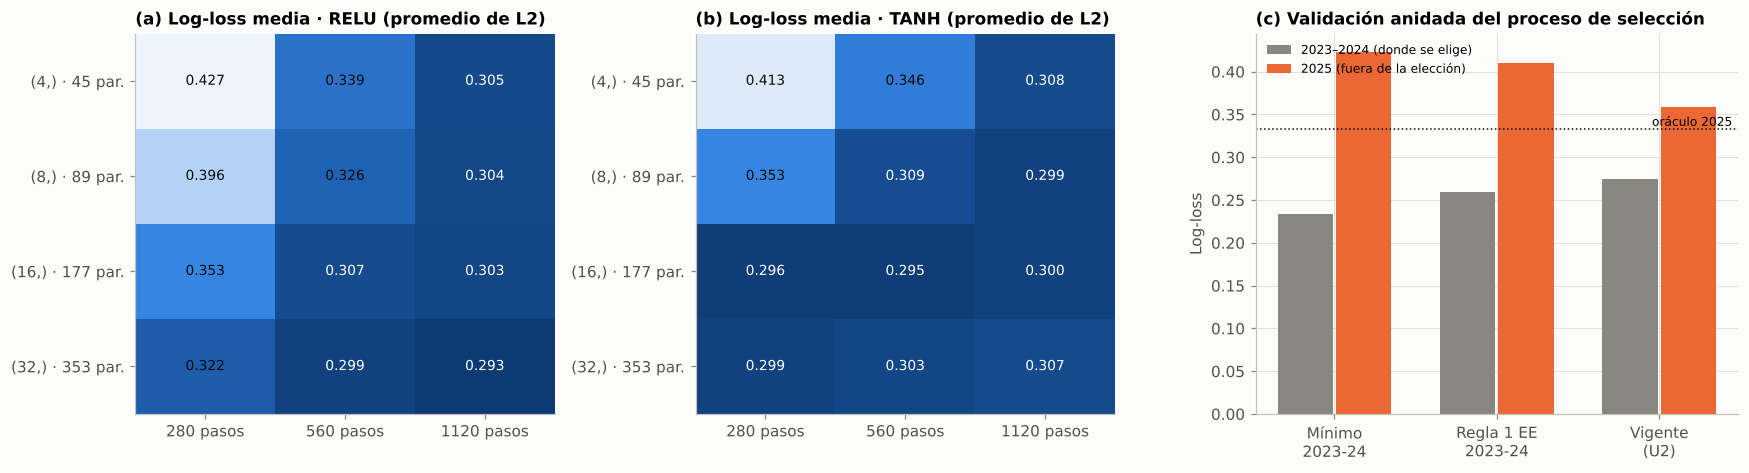

In [16]:
# =============================================================================
# 6.8 I6 rejilla de capacidad x L2 x activación x presupuesto (3 semillas, 3 pliegues)
# =============================================================================
t0 = time.time(); filas = []
REJILLA = [(c, l2, act, pasos) for c in [(4,), (8,), (16,), (32,)] for l2 in [1e-3, 1e-2] for act in ["relu", "tanh"] for pasos in [280, 560, 1120]]
for capas, l2, act, pasos in REJILLA:
    cfg_g = replace(CFG_ACTUAL, capas=capas, l2=l2, activacion=act, pasos=pasos)
    for s in (1, 2, 3):
        sp = P.Especificacion("g", VARS_FINAL, cfg_g, semillas=(s,))
        oos = E.validar(datos, P.ajustar_predecir(datos, SEQ, sp), E.particiones_origen_movil(datos))
        for v, g in oos.groupby("particion"):
            filas.append({"capas": str(capas), "L2": l2, "activación": act, "pasos": pasos, "semilla": s, "año": int(v), "LL": E.bce(g.y, g.g)})
REJ = pd.DataFrame(filas)
print(f"{len(REJILLA)} configuraciones × 3 semillas × 3 pliegues = {len(REJILLA) * 9} entrenamientos en {time.time() - t0:.0f} s")
K_ = ["capas", "L2", "activación", "pasos"]
N_PAR = {c: M.n_parametros(M.construir_red(len(VARS_FINAL), replace(CFG_ACTUAL, capas=eval(c)))) for c in REJ.capas.unique()}

def seleccionar(df):
    a = df.groupby(K_)["LL"].agg(media="mean", ee=lambda s: s.std(ddof=1) / np.sqrt(len(s))).reset_index()
    a["parámetros"] = a.capas.map(N_PAR)
    mejor = a.loc[a.media.idxmin()]
    cand = a[a.media <= mejor.media + mejor.ee].sort_values(["parámetros", "pasos", "media"])
    return a.sort_values("media"), mejor, cand.iloc[0], len(cand)

TAB_REJ, MEJOR, UNO_EE, N_CAND = seleccionar(REJ)
DEF = (str(CFG_ACTUAL.capas), CFG_ACTUAL.l2, CFG_ACTUAL.activacion, CFG_ACTUAL.pasos)
ll_def = TAB_REJ.set_index(K_).loc[DEF]
print(f"Mejor media: {tuple(MEJOR[K_])} LL {MEJOR.media:.3f} ± {MEJOR.ee:.3f} | configuraciones dentro de 1 EE: {N_CAND} de {len(TAB_REJ)}")
print(f"Configuración vigente {DEF}: LL {ll_def.media:.3f} (puesto {int((TAB_REJ.media < ll_def.media).sum()) + 1} de {len(TAB_REJ)}; "
      f"{'dentro' if ll_def.media <= MEJOR.media + MEJOR.ee else 'fuera'} de 1 EE del mejor)")

# Validación anidada: seleccionar con 2023-2024 y medir en 2025
_, m_in, u_in, _ = seleccionar(REJ[REJ["año"] < 2025])
ll25 = REJ[REJ["año"] == 2025].groupby(K_)["LL"].agg(["mean", "std"])
ANIDADA = pd.DataFrame({
    "Configuración": [str(tuple(m_in[K_])), str(tuple(u_in[K_])), str(DEF), str(tuple(ll25["mean"].idxmin()))],
    "LL 2023-2024 (selección)": [m_in.media, u_in.media, REJ[REJ["año"] < 2025].groupby(K_)["LL"].mean().loc[DEF], np.nan],
    "LL 2025 (fuera de la selección)": [ll25.loc[tuple(m_in[K_]), "mean"], ll25.loc[tuple(u_in[K_]), "mean"], ll25.loc[DEF, "mean"], ll25["mean"].min()],
}, index=["Mínimo en 2023-2024", "Regla 1 EE en 2023-2024", "Vigente (U2)", "Oráculo (mejor en 2025, inalcanzable)"])
tabla(ANIDADA, dec=3)
SELECCION_TRANSFIERE = min(ANIDADA.iloc[0, 2], ANIDADA.iloc[1, 2]) < ANIDADA.iloc[2, 2]
CFG_I6 = CFG_ACTUAL if not SELECCION_TRANSFIERE else replace(CFG_ACTUAL, capas=eval(UNO_EE.capas), l2=float(UNO_EE.L2), activacion=UNO_EE["activación"], pasos=int(UNO_EE.pasos))
DECISIONES.append({"Intervención": "I6 capacidad / activación / L2 / presupuesto", "Referencia": str(DEF), "ΔLog-loss": ANIDADA.iloc[1, 2] - ANIDADA.iloc[2, 2],
                   "EE": np.nan, "ΔAUC": np.nan, "Decisión": "se retiene" if SELECCION_TRANSFIERE else "no se retiene (la selección no transfiere a 2025)"})

# Tasa de aprendizaje (con el presupuesto vigente)
for lr in (3e-4, 3e-3):
    evaluar(P.Especificacion(f"I6 lr={lr:g}", VARS_FINAL, replace(CFG_I6, lr=lr)))
tabla(resumen([REF_VARS, "I6 lr=0.0003", "I6 lr=0.003"])[["ROC-AUC", "Log-loss", "Log-loss (DE)", "Brier"]], dec=3)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for ax, act in zip(axes[:2], ["relu", "tanh"]):
    m_ = REJ[REJ["activación"] == act].groupby(["capas", "pasos"])["LL"].mean().unstack().loc[["(4,)", "(8,)", "(16,)", "(32,)"]]
    im = ax.imshow(m_.values, cmap=G.CMAP_P.reversed(), vmin=TAB_REJ.media.min(), vmax=.42, aspect="auto")
    for i in range(m_.shape[0]):
        for j in range(m_.shape[1]):
            ax.text(j, i, f"{m_.values[i, j]:.3f}", ha="center", va="center", fontsize=9, color="white" if m_.values[i, j] < .31 else TINTA)
    ax.set_xticks(range(3), [f"{p} pasos" for p in m_.columns]); ax.set_yticks(range(4), [f"{c} · {N_PAR[c]} par." for c in m_.index])
    ax.grid(False); ax.set_title(f"({'ab'[act == 'tanh']}) Log-loss media · {act.upper()} (promedio de L2)")
ax = axes[2]
x = np.arange(len(ANIDADA) - 1)
ax.bar(x - .18, ANIDADA.iloc[:3, 1], width=.34, color=COL["D"], label="2023–2024 (donde se elige)")
ax.bar(x + .18, ANIDADA.iloc[:3, 2], width=.34, color=COL["val"], label="2025 (fuera de la elección)")
ax.axhline(ANIDADA.iloc[3, 2], color=TINTA, lw=1, ls=":"); ax.text(2.45, ANIDADA.iloc[3, 2], " oráculo 2025", fontsize=8, va="bottom", ha="right")
ax.set_xticks(x, ["Mínimo\n2023-24", "Regla 1 EE\n2023-24", "Vigente\n(U2)"]); ax.set_ylabel("Log-loss")
ax.set_title("(c) Validación anidada del proceso de selección"); ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); guardar(fig, "fig04_rejilla_anidada"); plt.show()

**Lectura.**

* La superficie es plana. De 48 configuraciones, 31 quedan dentro de un error estándar de la mejor (32 neuronas,
  L2 = 10⁻², 1.120 pasos; log-loss 0,289 ± 0,028). La vigente de la U2 (16 ReLU, L2 = 10⁻³, 560 pasos) queda en el
  puesto 18 (0,303), dentro de esa banda. Los mapas (a) y (b) muestran el único patrón robusto: las redes pequeñas (4–8
  neuronas) necesitan más pasos, y con 280 pasos no alcanzan a converger. Con 560 o más, casi todo es equivalente.
  ReLU y tanh también empatan.
* Validación anidada de un solo pliegue externo. La configuración con mejor log-loss en 2023–2024 (0,234) obtiene 0,423
  en 2025, y la que elige la regla de 1 EE en 2023–2024 obtiene 0,411. La vigente obtiene 0,359, pero la comparación la
  favorece: su capacidad se eligió en la U2 con validación de origen móvil que incluía 2025, y su presupuesto de 560 pasos
  es la mediana de la parada temprana sobre 2025 (D10). Por eso no la leemos como prueba de que la vigente sea mejor,
  sino como señal de que, con 58 filas de validación, la rejilla no ofrece una alternativa que se sostenga al año
  siguiente (Cawley y Talbot, 2010).
* Tasa de aprendizaje. Con el presupuesto fijo, η = 3×10⁻⁴ deja la red sin entrenar (log-loss 0,452) y η = 3×10⁻³
  no mejora (0,319). η = 10⁻³ es el valor adecuado para 560 pasos.
* Decisión: mantenemos la configuración de la U2 por parsimonia. La capacidad no es el factor limitante y la rejilla no
  muestra una alternativa estable.

## 6.9 I7: ensamble de semillas

,LL media,LL p5,LL p95,AUC media,LL DE
K,,,,,
1,"0,3077","0,2833","0,3366","0,9531","0,0142"
2,"0,3010","0,2859","0,3168","0,9556","0,0094"
3,"0,2991","0,2859","0,3107","0,9566","0,0076"
5,"0,2980","0,2905","0,3079","0,9566","0,0052"
7,"0,2978","0,2909","0,3043","0,9573","0,0042"
10,"0,2970","0,2924","0,3018","0,9574","0,0028"
15,"0,2969","0,2940","0,2993","0,9579","0,0017"
20,"0,2965","0,2965","0,2965","0,9567","0,0000"


Dispersión de P(C) entre semillas por fila: mediana 0.047, máx. 0.128 | filas con predicción unánime entre 20 redes: 85%


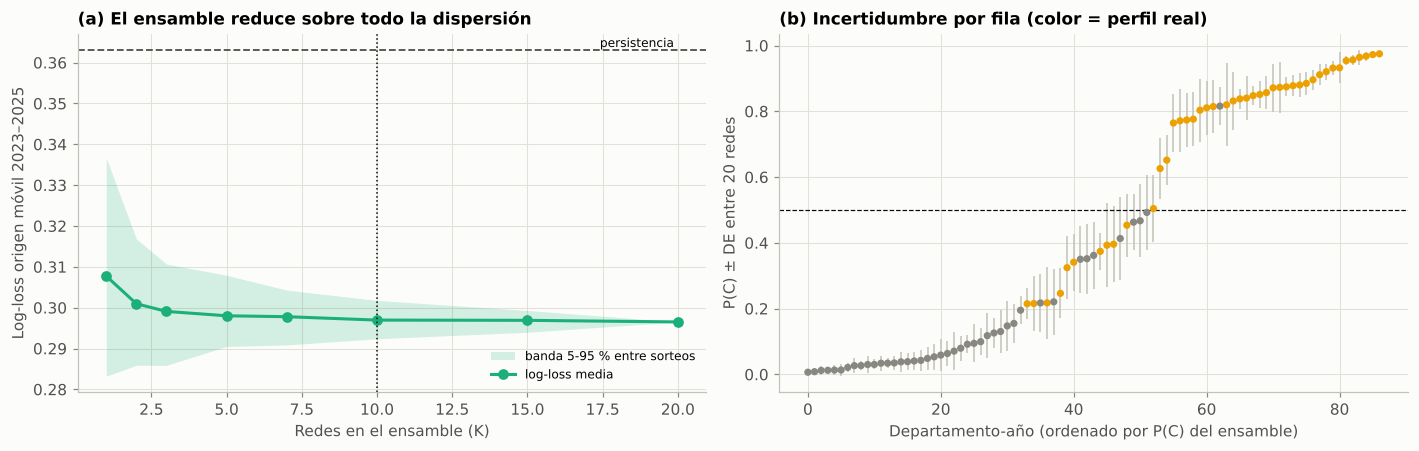

In [17]:
# =============================================================================
# 6.9 I7 ensamble: 20 semillas de la especificación vigente y curva de tamaño del ensamble
# =============================================================================
SPEC_I7 = P.Especificacion("I7 base de semillas", VARS_FINAL, CFG_I6)
r20 = evaluar(SPEC_I7, semillas=tuple(range(1, 21)), clave="I7 20 semillas")
P20, y_oos = r20["P"], r20["oos"]["y"].values
rng_k = np.random.default_rng(C.SEED); curva = []
for k in (1, 2, 3, 5, 7, 10, 15, 20):
    ll = [E.bce(y_oos, P20[rng_k.choice(20, k, replace=False)].mean(0)) for _ in range(200 if k < 20 else 1)]
    au = [roc_auc_score(y_oos, P20[rng_k.choice(20, k, replace=False)].mean(0)) for _ in range(200 if k < 20 else 1)]
    curva.append({"K": k, "LL media": np.mean(ll), "LL p5": np.percentile(ll, 5), "LL p95": np.percentile(ll, 95), "AUC media": np.mean(au), "LL DE": np.std(ll)})
CURVA_K = pd.DataFrame(curva).set_index("K")
K_ENS = 10
desv_ind = P20.std(0)
unan = np.mean(((P20 >= .5).mean(0) == 0) | ((P20 >= .5).mean(0) == 1))
tabla(CURVA_K, dec=4)
print(f"Dispersión de P(C) entre semillas por fila: mediana {np.median(desv_ind):.3f}, máx. {desv_ind.max():.3f} | "
      f"filas con predicción unánime entre 20 redes: {unan:.0%}")
RANGO_K = (CURVA_K.loc[1, "LL p95"] - CURVA_K.loc[1, "LL p5"], CURVA_K.loc[K_ENS, "LL p95"] - CURVA_K.loc[K_ENS, "LL p5"])
DECISIONES.append({"Intervención": f"I7 ensamble de {K_ENS} semillas", "Referencia": "1 red", "ΔLog-loss": CURVA_K.loc[K_ENS, "LL media"] - CURVA_K.loc[1, "LL media"],
                   "EE": np.nan, "ΔAUC": CURVA_K.loc[K_ENS, "AUC media"] - CURVA_K.loc[1, "AUC media"], "Decisión": "se retiene (estabilidad)"})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.fill_between(CURVA_K.index, CURVA_K["LL p5"], CURVA_K["LL p95"], color=COL["u3"], alpha=.18, lw=0, label="banda 5-95 % entre sorteos")
ax.plot(CURVA_K.index, CURVA_K["LL media"], color=COL["u3"], marker="o", label="log-loss media")
ax.axhline(M_PERS["Log-loss"], color=COL["pers"], ls="--", lw=1.2); ax.text(20, M_PERS["Log-loss"], "persistencia ", ha="right", va="bottom", fontsize=8)
ax.axvline(K_ENS, color=TINTA, lw=1, ls=":"); ax.set_xlabel("Redes en el ensamble (K)"); ax.set_ylabel("Log-loss origen móvil 2023–2025")
ax.set_title("(a) El ensamble reduce sobre todo la dispersión"); ax.legend(fontsize=8)
ax = axes[1]
orden = np.argsort(r20["oos"]["p"].values)
ax.errorbar(np.arange(len(orden)), P20.mean(0)[orden], yerr=desv_ind[orden], fmt="none", ecolor=EJE, lw=1)
ax.scatter(np.arange(len(orden)), P20.mean(0)[orden], s=14, c=np.where(y_oos[orden] == 1, COL["C"], COL["D"]), zorder=3)
ax.axhline(.5, color=TINTA, lw=.8, ls="--"); ax.set_xlabel("Departamento-año (ordenado por P(C) del ensamble)"); ax.set_ylabel("P(C) ± DE entre 20 redes")
ax.set_title("(b) Incertidumbre por fila (color = perfil real)")
fig.tight_layout(); guardar(fig, "fig05_ensamble"); plt.show()

**Lectura.** **I7 se retiene por estabilidad, no por desempeño medio.** Una red individual tiene log-loss esperada de
0,308, pero según la semilla puede caer en cualquier punto entre 0,283 y 0,337 (banda del 5–95 %). Con 10 redes la
media apenas cambia (0,297), pero la banda se estrecha a **0,292–0,302**, unas 6 veces menos. Más allá de 10 la ganancia
es marginal. La dispersión de $P(C)$ entre redes por fila tiene mediana de 0,047 y máximo de 0,128, y el 85 % de las
filas recibe la misma clasificación de las 20 redes. El ensamble convierte un resultado que dependía de la semilla
(el problema de la semilla 42 en la U2, D10) en uno reproducible, y su desviación entre redes sirve de medida de
incertidumbre por departamento en §12.

## 6.10 I8: calibración y umbral de decisión

La U2 vio probabilidades por debajo de la frecuencia real de C fuera de muestra y un umbral F2 (0,17) que no se
transfirió a 2026. Probamos dos calibradores sobre el ensamble ($K = 10$): **Platt** ($\sigma(a\,\mathrm{logit}\,p + b)$),
que corrige escala y sesgo, y **temperatura** ($\sigma(\mathrm{logit}\,p / T)$), que solo corrige la escala. Se
evalúan de dos formas:

* **Encadenamiento hacia adelante** (honesta en el tiempo): 2024 se calibra con 2023, y 2025 con 2023–2024.
* **Validación cruzada por año** (dejar un año fuera): usa más datos, pero calibra 2023 con información de 2025.

Si la calibración solo sirve cuando se mira el futuro, no se adopta.

,LL 2024-2025,Brier 2024-2025,ECE 2024-2025,LL 2023-2025,ECE 2023-2025
Calibración,,,,,
Sin calibrar,"0,298","0,093","0,142","0,304","0,124"
Platt · adelante,"0,302","0,099","0,097","0,307","0,068"
Temperatura · adelante,"0,306","0,100","0,100","0,310","0,071"
Platt · dejar un año fuera,"0,330","0,113","0,048","0,348","0,061"
Temperatura · dejar un año fuera,"0,316","0,102","0,102","0,313","0,071"


Parámetros de Platt ajustados en cada año por separado (muestran si el sesgo es estable):


,2023,2024,2025
a (escala),"1,312","3,379","93,448"
b (sesgo),"0,053","0,132","151,575"
Prevalencia C,"0,483","0,414","0,621"


Umbral que maximiza el MCC en cada año: {'2023': 0.2, '2024': 0.51, '2025': 0.15, 'Agregado 2023-2025': 0.2}
MCC con umbral 0,5: 0.691 | con el óptimo agregado 0.20: 0.810


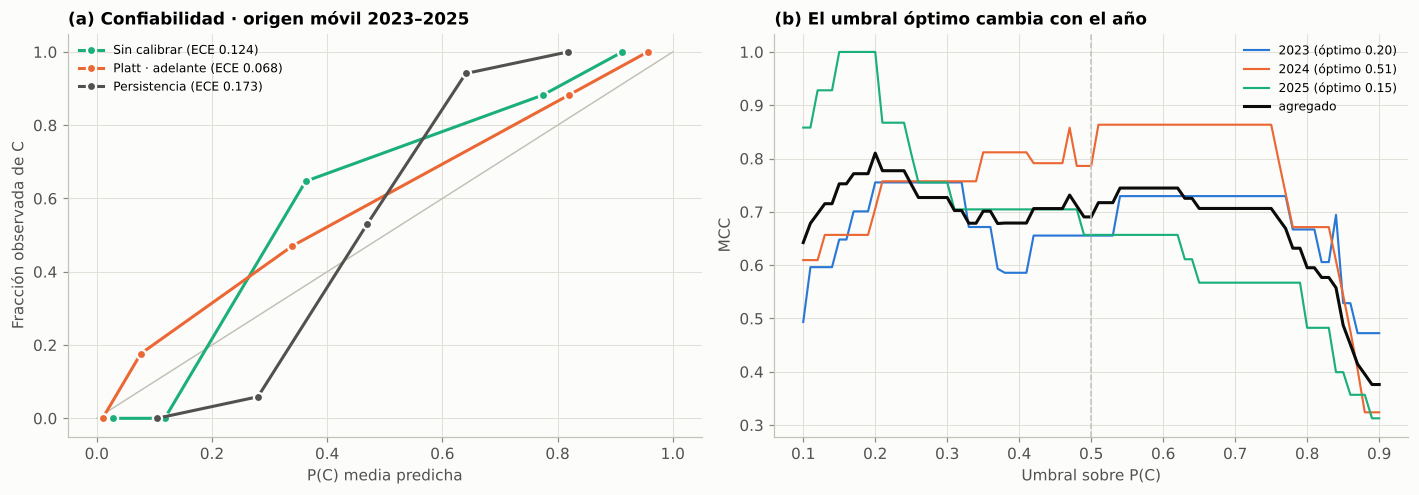

Calibración adoptada: ninguna | umbral operativo: 0.5


In [18]:
# =============================================================================
# 6.10 I8 calibración (Platt / temperatura) y estabilidad del umbral óptimo entre años
# =============================================================================
oos7 = r20["oos"]; p_ens = P20[:K_ENS].mean(0); yv = oos7["y"].values
def calibrar_lofo(p, metodo):
    q = p.copy()
    for v in oos7["particion"].unique():
        m = (oos7["particion"] == v).values
        q[m] = M.Calibrador(metodo).ajustar(p[~m], yv[~m]).aplicar(p[m])
    return q
mask_fwd = oos7["particion"].isin(["2024", "2025"]).values           # el encadenamiento no calibra el primer pliegue
filas = []
for nombre, q in [("Sin calibrar", p_ens), ("Platt · adelante", calibrar_adelante(oos7, p_ens, "platt")),
                  ("Temperatura · adelante", calibrar_adelante(oos7, p_ens, "temperatura")),
                  ("Platt · dejar un año fuera", calibrar_lofo(p_ens, "platt")), ("Temperatura · dejar un año fuera", calibrar_lofo(p_ens, "temperatura"))]:
    filas.append({"Calibración": nombre, "LL 2024-2025": E.bce(yv[mask_fwd], q[mask_fwd]), "Brier 2024-2025": np.mean((q[mask_fwd] - yv[mask_fwd]) ** 2),
                  "ECE 2024-2025": E.ece(yv[mask_fwd], q[mask_fwd]), "LL 2023-2025": E.bce(yv, q), "ECE 2023-2025": E.ece(yv, q)})
CAL = pd.DataFrame(filas).set_index("Calibración")
tabla(CAL, dec=3)
par_anio = pd.DataFrame({v: (lambda c: {"a (escala)": c.a, "b (sesgo)": c.b, "Prevalencia C": yv[(oos7.particion == v).values].mean()})(
    M.Calibrador("platt").ajustar(p_ens[(oos7.particion == v).values], yv[(oos7.particion == v).values])) for v in sorted(oos7.particion.unique())})
print("Parámetros de Platt ajustados en cada año por separado (muestran si el sesgo es estable):")
tabla(par_anio, dec=3)
mejor_cal = CAL.iloc[1:3]["LL 2024-2025"].idxmin()
CALIBRACION = ("platt" if "Platt" in mejor_cal else "temperatura") if CAL.loc[mejor_cal, "LL 2024-2025"] < CAL.loc["Sin calibrar", "LL 2024-2025"] - 0.005 else "ninguna"
DECISIONES.append({"Intervención": "I8 calibración", "Referencia": "sin calibrar", "ΔLog-loss": CAL.loc[mejor_cal, "LL 2024-2025"] - CAL.loc["Sin calibrar", "LL 2024-2025"],
                   "EE": np.nan, "ΔAUC": 0.0, "Decisión": "se retiene" if CALIBRACION != "ninguna" else "no se retiene (no mejora sin mirar el futuro)"})

# Umbral: ¿el umbral óptimo es estable entre años?
from sklearn.metrics import matthews_corrcoef
umbrales = np.round(np.linspace(.1, .9, 81), 2)
U = pd.DataFrame({v: [matthews_corrcoef(yv[(oos7.particion == v).values], p_ens[(oos7.particion == v).values] >= u) for u in umbrales]
                  for v in sorted(oos7.particion.unique())}, index=umbrales)
U["Agregado 2023-2025"] = [matthews_corrcoef(yv, p_ens >= u) for u in umbrales]
U_OPT = U.idxmax()
print("Umbral que maximiza el MCC en cada año:", U_OPT.round(2).to_dict())
U_AGR = float(U_OPT["Agregado 2023-2025"]); UMBRAL = 0.5
print(f"MCC con umbral 0,5: {U.loc[0.5, 'Agregado 2023-2025']:.3f} | con el óptimo agregado {U_AGR:.2f}: {U['Agregado 2023-2025'].max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]; ax.plot([0, 1], [0, 1], color=EJE, lw=1)
for nombre, q, color in [("Sin calibrar", p_ens, COL["u3"]), ("Platt · adelante", calibrar_adelante(oos7, p_ens, "platt"), COL["logit"]), ("Persistencia", PERS["p"].values, COL["pers"])]:
    yy_ = yv if nombre != "Persistencia" else PERS["y"].values
    fr, mp = calibration_curve(yy_, q, n_bins=5, strategy="quantile")
    ax.plot(mp, fr, marker="o", color=color, mec=FONDO, mew=1.5, label=f"{nombre} (ECE {E.ece(yy_, q):.3f})")
ax.set_xlabel("P(C) media predicha"); ax.set_ylabel("Fracción observada de C"); ax.set_title("(a) Confiabilidad · origen móvil 2023–2025"); ax.legend(fontsize=8)
ax = axes[1]
for v, color in zip(sorted(oos7.particion.unique()), [COL["mlp"], COL["logit"], COL["test"]]):
    ax.plot(U.index, U[v], color=color, lw=1.4, label=f"{v} (óptimo {U_OPT[v]:.2f})")
ax.plot(U.index, U["Agregado 2023-2025"], color=TINTA, lw=2, label="agregado"); ax.axvline(.5, color=EJE, lw=1, ls="--")
ax.set_xlabel("Umbral sobre P(C)"); ax.set_ylabel("MCC"); ax.set_title("(b) El umbral óptimo cambia con el año"); ax.legend(fontsize=8)
fig.tight_layout(); guardar(fig, "fig06_calibracion_umbral"); plt.show()
print("Calibración adoptada:", CALIBRACION, "| umbral operativo:", UMBRAL)

**Lectura.** I8 se rechaza para la probabilidad y el umbral se mantiene en 0,5.

* La calibración solo mejora si se mira el futuro. Con encadenamiento hacia adelante (la única evaluación que respeta el
  tiempo), Platt baja el ECE de 0,142 a 0,097, pero sube la log-loss de 0,298 a 0,302 y el Brier de 0,093 a 0,099 en
  2024–2025. La temperatura también empeora (0,306).
* La corrección no es estable. Ajustado año por año, el parámetro de escala de Platt vale $a$ = 1,31 en 2023 y 3,38 en
  2024. En 2025 no converge ($a \approx 93$, $b \approx 152$) porque la red separa perfectamente las clases ese año
  (AUC = 1,0), aunque con umbral 0,5 clasifica mal seis escaladas: sin solapamiento entre clases, la mejor calibración es
  un escalón. El desajuste depende de la prevalencia de cada año (41 % a 62 % de C) y una corrección estimada con el
  pasado no sirve para el año siguiente.
* El umbral óptimo tampoco se transfiere. El que maximiza el MCC es 0,20 en 2023, 0,51 en 2024 y 0,15 en 2025.
  Usar 0,20 sobre el agregado subiría el MCC de 0,69 a 0,81, pero sería elegirlo con los mismos datos que lo evalúan:
  es el error que la U2 documentó con el umbral F2 (0,17), que no transfirió a 2026.
* Para la decisión no usamos un umbral único sino las bandas de §1.3: un departamento con $\hat p$ entre 0,3 y 0,7 es
  "transición" y recibe portafolio flexible. La incertidumbre de calibración queda así en la decisión.

## 6.11 Síntesis de las intervenciones

Intervención,Referencia,ΔLog-loss,EE,IC95 Δ (depto),ΔAUC,Decisión
I1 memoria m1,MLP base U2,-0.0358,0.0094,"[-0,056; -0,019]",+0.0174,se retiene
"I1 trayectoria m2, m3",I1a +m1,+0.0016,0.0110,"[-0,036; +0,055]",-0.0001,no se retiene
I2 semestre reciente d1,I1a +m1,-0.0374,0.0068,"[-0,066; -0,011]",+0.0127,se retiene
"I2 tendencias d2, d3",I2a +d1,+0.0130,0.0087,"[-0,030; +0,071]",-0.0059,no se retiene
I3 actores armados x3,I2a +d1,+0.0250,0.0056,"[-0,002; +0,063]",-0.0145,no se retiene
I4 vecindad (temporal),I2a +d1,-0.0040,0.0019,"[-0,035; +0,027]",+0.0020,no se retiene
I4 vecindad (espacial),esp: referencia,+0.0094,0.0037,"[-0,023; +0,046]",-0.0054,no se retiene
I5 objetivo blando (sin calibrar),I2a +d1,+0.1193,0.0044,"[+0,054; +0,184]",-0.0044,no se retiene
I5 objetivo blando (ambos calibrados),I2a +d1 · cal,+0.0678,0.0078,"[+0,028; +0,107]",-0.0152,no se retiene
I9 multitarea λ=0.5 (efecto en P(C)),I2a +d1,+0.0013,0.0027,"[-0,006; +0,010]",-0.0001,no se retiene


,LL media,LL DE,AUC,Brier,Transiciones acertadas
Paso,,,,,
Modelo base U2,"0,383","0,021","0,921","0,123","2,400"
+ I1 memoria m₁,"0,347","0,010","0,939","0,110","2,400"
+ I2 semestre d₁,"0,310","0,010","0,951","0,097",2
+ I7 ensamble (10),"0,304","0,000","0,956","0,095",2


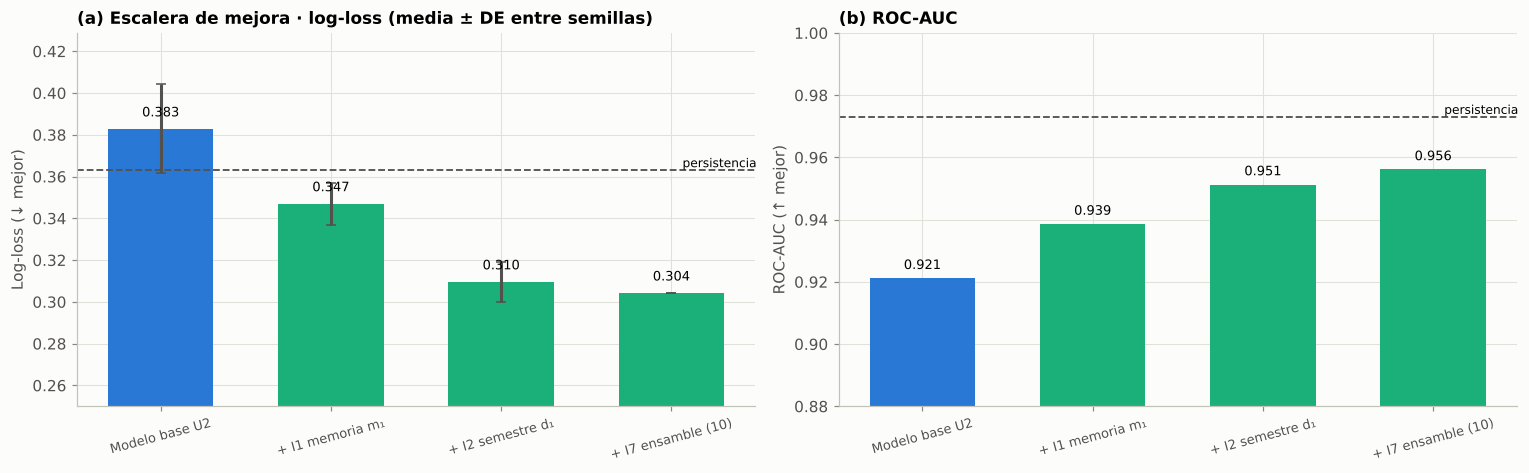

In [19]:
# =============================================================================
# 6.11 Tabla de decisiones y escalera de mejora
# =============================================================================
DEC = pd.DataFrame(DECISIONES)
display(DEC.style.format({"ΔLog-loss": "{:+.4f}", "EE": "{:.4f}", "ΔAUC": "{:+.4f}"}, na_rep="–").hide(axis="index")
        .map(lambda v: f"color: {COL['u3']}; font-weight: 600" if isinstance(v, str) and v.startswith("se retiene") else "", subset=["Decisión"]))
ESCALERA_T = [(e, k) for e, k in ESCALERA]
filas = []
for etiqueta, k in ESCALERA_T:
    ps = RES[k]["por_semilla"]
    filas.append({"Paso": etiqueta, "LL media": ps["Log-loss"].mean(), "LL DE": ps["Log-loss"].std(ddof=1), "AUC": ps["ROC-AUC"].mean(), "Brier": ps["Brier"].mean(),
                  "Transiciones acertadas": ps["Transiciones acertadas"].mean()})
m10 = E.metricas(yv, p_ens, transicion=oos7["transicion"])
filas.append({"Paso": f"+ I7 ensamble ({K_ENS})", "LL media": m10["Log-loss"], "LL DE": 0, "AUC": m10["ROC-AUC"], "Brier": m10["Brier"], "Transiciones acertadas": m10["Transiciones acertadas"]})
ESC = pd.DataFrame(filas).drop_duplicates("Paso").set_index("Paso")
tabla(ESC, dec=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, col, et in [(axes[0], "LL media", "Log-loss (↓ mejor)"), (axes[1], "AUC", "ROC-AUC (↑ mejor)")]:
    x = np.arange(len(ESC))
    ax.bar(x, ESC[col], color=[COL["mlp"]] + [COL["u3"]] * (len(ESC) - 1), yerr=ESC["LL DE"] if col == "LL media" else None, ecolor=TINTA2, capsize=3, width=.62)
    for xi, v in zip(x, ESC[col]):
        ax.text(xi, v + (0.006 if col == "LL media" else 0.003), f"{v:.3f}", ha="center", fontsize=8.5)
    ref_p = M_PERS["Log-loss" if col == "LL media" else "ROC-AUC"]
    ax.axhline(ref_p, color=COL["pers"], ls="--", lw=1.2); ax.text(len(ESC) - .5, ref_p, "persistencia", ha="right", va="bottom", fontsize=8)
    ax.set_xticks(x, ESC.index, fontsize=8.5, rotation=15); ax.set_ylabel(et)
    ax.set_ylim((0.25, max(ESC[col].max(), ref_p) * 1.12) if col == "LL media" else (0.88, 1.0))
axes[0].set_title("(a) Escalera de mejora · log-loss (media ± DE entre semillas)"); axes[1].set_title("(b) ROC-AUC")
fig.tight_layout(); guardar(fig, "fig07_escalera_mejora"); plt.show()

**Lectura de la síntesis.** De las intervenciones evaluadas se retienen tres: $m_1$ (I1), $d_1$ (I2) y el ensamble (I7).
Juntas bajan la log-loss de 0,383 a 0,304 y suben el AUC de 0,921 a 0,956. El resto se descarta con una razón
cuantitativa registrada en la tabla: no cumplieron la regla de retención, salvo la vecindad, que mejoró solo en el eje
que no era el de su hipótesis, y el embedding, que la cumplió y se descartó por la regla 8. La escalera muestra que la
mejora vino de la representación de los datos: las dos variables retenidas resumen el estado reciente del conflicto, que
es lo que la U2 identificó como información faltante, mientras que capacidad, profundidad, redes secuenciales, salida
multitarea y calibración no cambiaron el resultado. El modelo final es tan simple como el de la U2 (una capa de 16
neuronas), con dos entradas más y unas seis veces menos dispersión entre semillas.

---
# 7. Controles experimentales de la preparación de datos

Cada decisión de preprocesamiento se pone a prueba **quitándola** (o introduciendo a propósito un error conocido)
y midiendo el efecto con el mismo protocolo, las mismas 5 semillas y la especificación final de variables. Un
control "pasa" cuando el resultado se mueve en la dirección que predice la teoría.

| Control | Qué se cambia | Qué esperamos si la decisión original es correcta |
|---|---|---|
| Sin estandarización | Variables en escala original (km, %, log) | Peor convergencia: el gradiente lo dominan las variables de gran escala (distancia, bosque) |
| Sin logaritmos | $x_1$, $x_2$, $x_4$ en conteos y hectáreas crudas | Peor: colas extremas (Cauca, Nariño) dominan el ajuste |
| Sin pesos de clase | BCE sin $\omega_c$ | Efecto pequeño (clases casi balanceadas), algo peor en sensibilidad |
| Sin contracción ($\alpha \approx 0$) | $m_1$, $d_1$ con proporciones crudas | Peor: semestres con pocos eventos producen proporciones extremas |
| Escalador con fuga (control negativo) | Media y desviación ajustadas también con el año de prueba | Mejora artificial pequeña: cuantifica cuánto inflaría una fuga típica |
| `MIN_EVENTOS` = 5 / 20 | Umbral de confiabilidad de la etiqueta en el entrenamiento | 10 equilibra tamaño y ruido de etiqueta (D3) |
| Mapeo alternativo (M8) | *Shelling* → B y *Sexual violence* → C | Sin cambio material (1 etiqueta de 171 cambia, U2 §3.4) |
| Etiquetas barajadas (cordura) | Se entrena con $y$ permutada | AUC ≈ 0,5: el modelo no "aprende" ruido |

In [20]:
# =============================================================================
# 7.1 Ablaciones de preprocesamiento (5 semillas, origen móvil 2023-2025)
# =============================================================================
t0 = time.time()
REF_CTRL = P.Especificacion("ctrl: referencia", VARS_FINAL, CFG_I6)
evaluar(REF_CTRL)
evaluar(replace(REF_CTRL, nombre="ctrl: sin estandarización", escalar=False))
evaluar(replace(REF_CTRL, nombre="ctrl: escalador con fuga", fuga_escalador=True))
evaluar(replace(REF_CTRL, nombre="ctrl: sin pesos de clase", red=replace(CFG_I6, pesos_clase=False)))
d_nolog = datos.copy()
for x_ in ["x1_eventos", "x2_fatalidades", "x4_coca"]:
    d_nolog[x_] = np.expm1(datos[x_])
evaluar(replace(REF_CTRL, nombre="ctrl: sin logaritmos"), base=d_nolog)
V.ALFA = 1e-9
d_cruda, S_cruda, _ = V.construir_dataset(acled, actores=ACTORES)
V.ALFA = 4.0
evaluar(replace(REF_CTRL, nombre="ctrl: sin contracción"), base=d_cruda, seq=S_cruda)
d_alt, S_alt, _ = V.construir_dataset(acled, mapa=C.MAPA_ALTERNATIVO, actores=ACTORES)
evaluar(replace(REF_CTRL, nombre="ctrl: mapeo alternativo"), base=d_alt, seq=S_alt)

# Etiquetas barajadas: se entrena con y permutada y se evalúa contra la etiqueta real
rng_p = np.random.default_rng(0); idx_p = rng_p.permutation(len(datos))
d_perm = datos.copy(); d_perm["y"] = datos["y"].values[idx_p]; d_perm["s_C"] = datos["s_C"].values[idx_p]
filas = []
for s in SEM5:
    sp = replace(REF_CTRL, semillas=(s,)); ps, ys, ts = [], [], []
    for v, tr, te in E.particiones_origen_movil(datos):
        m_, e_ = P.entrenar_especificacion(d_perm, SEQ, sp, tr)
        ps.append(P.predecir_especificacion(m_, e_, datos, SEQ, sp, te)); ys.append(datos.loc[te, "y"].values); ts.append(datos.loc[te, "transicion"].values)
    filas.append({"semilla": s, **E.metricas(np.concatenate(ys), np.concatenate(ps), transicion=np.concatenate(ts))})
RES["ctrl: etiquetas barajadas"] = {"por_semilla": pd.DataFrame(filas).set_index("semilla"), "spec": REF_CTRL}

# Umbral de confiabilidad: se entrena con MIN_EVENTOS = 5, 10, 20 y se evalúa en las mismas filas (>= 20 eventos)
d5, S5, _ = V.construir_dataset(acled, min_eventos=5, actores=ACTORES)
MINEV = []
for m_ev in (5, 10, 20):
    for s in SEM5:
        sp = replace(REF_CTRL, semillas=(s,)); ps, ys = [], []
        for v in C.ANIOS_SELECCION:
            tr = ((d5.anio < v) & (d5.eventos >= m_ev)).values; te = ((d5.anio == v) & (d5.eventos >= 20)).values
            m_, e_ = P.entrenar_especificacion(d5, S5, sp, tr)
            ps.append(P.predecir_especificacion(m_, e_, d5, S5, sp, te)); ys.append(d5.loc[te, "y"].values)
        MINEV.append({"MIN_EVENTOS": m_ev, "semilla": s, "filas de entrenamiento (último pliegue)": int(tr.sum()),
                      "LL": E.bce(np.concatenate(ys), np.concatenate(ps)), "AUC": roc_auc_score(np.concatenate(ys), np.concatenate(ps))})
MINEV = pd.DataFrame(MINEV)
print(f"Controles en {time.time() - t0:.0f} s")

ctrl_k = ["ctrl: sin estandarización", "ctrl: sin logaritmos", "ctrl: sin pesos de clase", "ctrl: sin contracción",
          "ctrl: escalador con fuga", "ctrl: mapeo alternativo", "ctrl: etiquetas barajadas"]
CTRL = pd.DataFrame([decidir(k, "ctrl: referencia") for k in ctrl_k]).set_index("Intervención")[["ΔLog-loss", "EE", "ΔAUC"]]
CTRL["LL media"] = [RES[k]["por_semilla"]["Log-loss"].mean() for k in ctrl_k]
CTRL["AUC media"] = [RES[k]["por_semilla"]["ROC-AUC"].mean() for k in ctrl_k]
ll_ref = RES["ctrl: referencia"]["por_semilla"]["Log-loss"].mean()
mv = MINEV.groupby("MIN_EVENTOS")[["LL", "AUC", "filas de entrenamiento (último pliegue)"]].mean()
print(f"Referencia: LL {ll_ref:.3f} | AUC {RES['ctrl: referencia']['por_semilla']['ROC-AUC'].mean():.3f}")
tabla(CTRL, dec=4)
print("Umbral de confiabilidad (evaluación común: filas con >= 20 eventos):")
tabla(mv, dec=3)

Controles en 102 s


Referencia: LL 0.310 | AUC 0.951


,ΔLog-loss,EE,ΔAUC,LL media,AUC media
Intervención,,,,,
ctrl: sin estandarización,"5,7803","1,4454","-0,4180","6,0899","0,5332"
ctrl: sin logaritmos,"-0,0117","0,0031","0,0049","0,2979","0,9561"
ctrl: sin pesos de clase,"0,0154","0,0019","-0,0003","0,3250","0,9510"
ctrl: sin contracción,"0,0021","0,0010","-0,0015","0,3117","0,9498"
ctrl: escalador con fuga,"-0,0024","0,0012","0,0002","0,3072","0,9515"
ctrl: mapeo alternativo,"0,0072","0,0007","-0,0045","0,3168","0,9467"
ctrl: etiquetas barajadas,"0,5057","0,0119","-0,6351","0,8153","0,3162"


Umbral de confiabilidad (evaluación común: filas con >= 20 eventos):


,LL,AUC,filas de entrenamiento (último pliegue)
MIN_EVENTOS,,,
5,"0,300","0,951",120
10,"0,307","0,951",113
20,"0,338","0,940",104


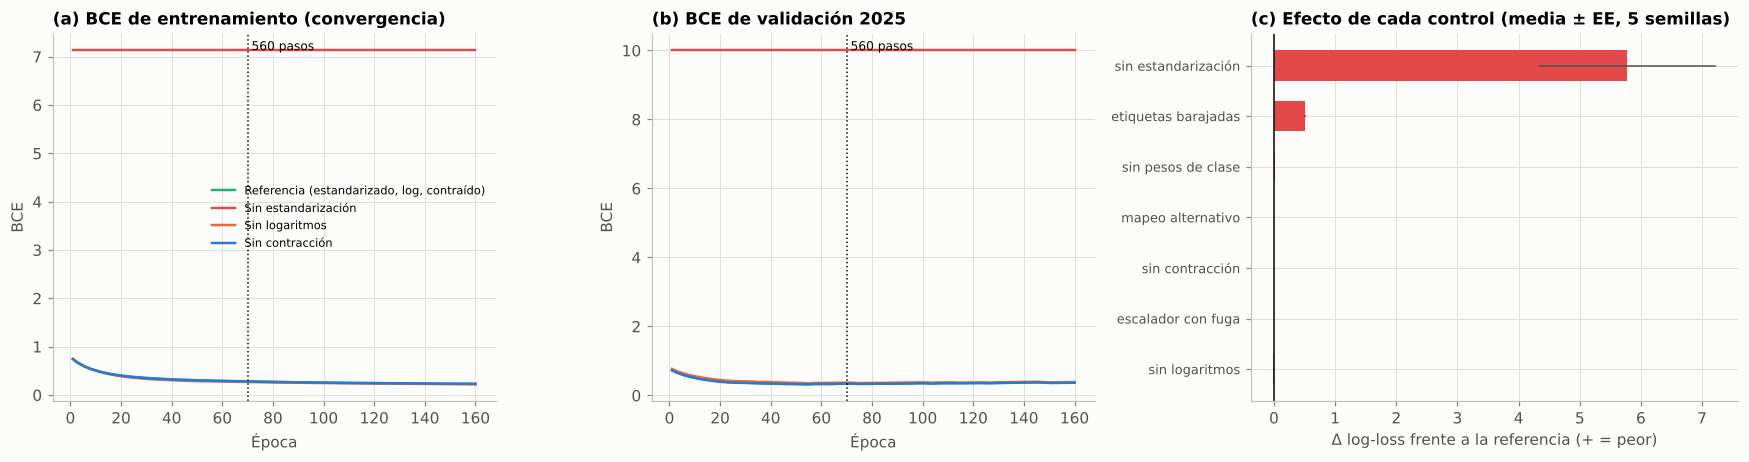

,BCE train época 10,BCE train época 70,BCE val época 70,BCE val mínima
"Referencia (estandarizado, log, contraído)","0,510","0,280","0,340","0,320"
Sin estandarización,"7,132","7,132","10,004","10,004"
Sin logaritmos,"0,507","0,266","0,373","0,353"
Sin contracción,"0,506","0,277","0,342","0,321"


In [21]:
# =============================================================================
# 7.2 Impacto en el entrenamiento: curvas de pérdida con y sin cada transformación (pliegue 2025)
# =============================================================================
def curva_entrenamiento(base, spec, epocas=160, semilla=1):
    tr, va = (base.anio < 2025).values, (base.anio == 2025).values
    esc = M.Escalador().ajustar(base.loc[tr, spec.variables].values)
    if not spec.escalar:
        esc.mu, esc.sd = np.zeros_like(esc.mu), np.ones_like(esc.sd)
    Xa, Xv = esc.transformar(base.loc[tr, spec.variables].values), esc.transformar(base.loc[va, spec.variables].values)
    y_obj = base.loc[tr, "s_C"].values if spec.red.objetivo == "blando" else base.loc[tr, "y"].values
    r = M.entrenar(Xa, y_obj, spec.red, semilla=semilla, y_duro=base.loc[tr, "y"].values, eventos=base.loc[tr, "eventos"].values,
                   comp=base.loc[tr, V.COMPOSICION].values, val=(Xv, base.loc[va, "y"].values), diagnostico=True, epocas=epocas)
    return r.historial
curvas_c = {"Referencia (estandarizado, log, contraído)": curva_entrenamiento(datos, REF_CTRL),
            "Sin estandarización": curva_entrenamiento(datos, replace(REF_CTRL, escalar=False)),
            "Sin logaritmos": curva_entrenamiento(d_nolog, REF_CTRL),
            "Sin contracción": curva_entrenamiento(d_cruda, REF_CTRL)}
EP_560 = math.ceil(560 / math.ceil((datos.anio < 2025).sum() / CFG_I6.batch))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1, 1, 1.1]})
colores_c = [COL["u3"], COL["A"], COL["logit"], COL["B"]]
for (nombre, H), color in zip(curvas_c.items(), colores_c):
    axes[0].plot(H["epoca"], H["bce_tr"], color=color, lw=1.6, label=nombre)
    axes[1].plot(H["epoca"], H["bce_va"], color=color, lw=1.6, label=nombre)
for ax, t in zip(axes[:2], ["(a) BCE de entrenamiento (convergencia)", "(b) BCE de validación 2025"]):
    ax.axvline(EP_560, color=TINTA, lw=1, ls=":"); ax.text(EP_560, ax.get_ylim()[1] * .98, " 560 pasos", fontsize=8, va="top")
    ax.set_xlabel("Época"); ax.set_title(t); ax.set_ylabel("BCE")
axes[0].legend(fontsize=7.5)
ax = axes[2]
orden = CTRL["ΔLog-loss"].sort_values().index
ax.barh(range(len(orden)), CTRL.loc[orden, "ΔLog-loss"], xerr=CTRL.loc[orden, "EE"], color=[COL["A"] if v > 0 else COL["u3"] for v in CTRL.loc[orden, "ΔLog-loss"]],
        error_kw=dict(ecolor=TINTA2, lw=1), height=.6)
ax.axvline(0, color=TINTA, lw=1); ax.set_yticks(range(len(orden)), [o.replace("ctrl: ", "") for o in orden], fontsize=8.5)
ax.set_xlabel("Δ log-loss frente a la referencia (+ = peor)"); ax.set_title("(c) Efecto de cada control (media ± EE, 5 semillas)")
fig.tight_layout(); guardar(fig, "fig08_controles_datos"); plt.show()
conv = pd.DataFrame({k: {"BCE train época 10": H["bce_tr"][9], f"BCE train época {EP_560}": H["bce_tr"][EP_560 - 1],
                         f"BCE val época {EP_560}": H["bce_va"][EP_560 - 1], "BCE val mínima": min(H["bce_va"])} for k, H in curvas_c.items()}).T
tabla(conv, dec=3)

**Lectura de los controles.**

* La estandarización es indispensable. Sin ella la red no converge: la BCE de entrenamiento queda en 7,1 desde la
  época 10. Las variables en km (distancia hasta 800) y en % (bosque hasta 98) saturan las ReLU y la sigmoide de salida,
  y el gradiente se anula. La log-loss fuera de muestra sube de 0,310 a 6,09 (probabilidades saturadas en 0 o 1) y el
  AUC cae a 0,53. Es el impacto más directo del preprocesamiento sobre el entrenamiento (panel a).
* Los pesos de clase se justifican (sin ellos, Δ = +0,015, unas 8 veces el EE). En entrenamiento la prevalencia de C es
  44 % y en los años validados llega a 62 %; sin la ponderación la red se inclina hacia D.
* La contracción aporta poco, en la dirección correcta (sin ella, Δ = +0,002, unas 2 veces el EE): estabiliza las
  proporciones semestrales con pocos eventos.
* La fuga deliberada del escalador da una mejora artificial de 0,002. Mide cuánto inflaría la métrica ajustar la media
  y la desviación con el año de prueba. Es pequeña porque la estandarización es lineal y las distribuciones cambian poco
  entre años; las pruebas automáticas de §11 detectarían una fuga así.
* El mapeo alternativo de subtipos empeora un poco (+0,007): la regla de la U1 se sostiene.
* Con etiquetas barajadas (control negativo) el modelo no aprende (log-loss 0,815; AUC 0,32). El valor exacto depende de
  la permutación, pero queda lejos de la referencia: el desempeño medido proviene de señal real.
* `MIN_EVENTOS`. Evaluando en las mismas filas (≥ 20 eventos), entrenar con 5 (log-loss 0,300) o con 10 (0,307) es
  equivalente, y con 20 empeora (0,338) porque se pierden filas. El umbral de 10 de la U2 queda en la zona correcta.
* Un resultado que no anticipábamos: sin logaritmos, la log-loss mejora levemente (0,298 frente a 0,310; Δ = −0,012,
  unas 4 veces el EE). Con la memoria en el modelo, las variables de volumen pasan a segundo plano y la red tolera bien
  sus colas. Por la regla 7, no cambiamos el modelo en esta iteración. En el pliegue 2025, el más exigente, la curva (b)
  muestra lo contrario (BCE de validación 0,373 sin logaritmos frente a 0,340), y el logaritmo protege la proyección
  frente a valores extremos nuevos. Queda como tarea para la escala municipal.

---
# 8. Modelo final integrado

## 8.1 Configuración documentada

In [22]:
# =============================================================================
# 8.1 Especificación final, resumen de Keras y configuración exportada
# =============================================================================
FINAL = P.Especificacion("MLP U3", VARS_FINAL, CFG_I6, semillas=tuple(range(1, K_ENS + 1)))
miembro = M.construir_red(len(VARS_FINAL), FINAL.red)
miembro.summary()
N_PAR_FINAL = M.n_parametros(miembro)
n_tr_2025 = int((datos.anio <= 2025).sum())
print(f"\nParámetros por red: {N_PAR_FINAL} | redes en el ensamble: {K_ENS} | filas 2021-2025: {n_tr_2025} | "
      f"parámetros por observación (una red): {N_PAR_FINAL / n_tr_2025:.2f}")
config_final = pd.DataFrame([
    ("Variables de entrada", f"{len(VARS_FINAL)}: " + ", ".join(VARS_FINAL)),
    ("Arquitectura", f"{len(VARS_FINAL)} → {' → '.join(map(str, FINAL.red.capas))} {FINAL.red.activacion.upper()} → 1 sigmoide" + (" + softmax(4)" if FINAL.red.tipo == "multitarea" else "")),
    ("Inicialización", "He normal (ReLU) / Glorot (tanh)"), ("Regularización", f"L2 = {FINAL.red.l2:g}; dropout = {FINAL.red.dropout:g}"),
    ("Pérdida", "BCE ponderada por clase" + (" con objetivo blando" if FINAL.red.objetivo == "blando" else "") + (f" + {FINAL.red.lambda_comp:g}·KL" if FINAL.red.tipo == "multitarea" else "")),
    ("Optimizador", f"Adam, η = {FINAL.red.lr:g}, lote {FINAL.red.batch}"), ("Presupuesto", f"{FINAL.red.pasos} pasos de gradiente por red"),
    ("Ensamble", f"{K_ENS} semillas (1-{K_ENS}), promedio de probabilidades"), ("Calibración", CALIBRACION), ("Umbral operativo", f"{UMBRAL}"),
    ("Escalado", "Estandarización ajustada solo con el entrenamiento de cada pliegue"),
], columns=["Componente", "Elección"]).set_index("Componente")
display(config_final)

CONFIG = {
    "descripcion": "Configuración del modelo final de la U3 (generada por la §8.1 del cuaderno).",
    "especificacion_final": FINAL.a_dict(),
    "especificacion_base_u2": replace(BASE_U2, semillas=(C.SEED,)).a_dict(),
    "calibracion": CALIBRACION, "umbral": UMBRAL,
    "protocolo": {"seleccion_origen_movil": list(C.ANIOS_SELECCION), "prueba": C.ANIO_PRUEBA, "min_eventos": C.MIN_EVENTOS,
                  "alfa_contraccion": V.ALFA, "semillas_intervenciones": list(SEM5)},
    "decisiones": [{k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in d.items()} for d in DECISIONES],
}
C.RUTA_CONFIG.write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(f"Configuración escrita en {C.RUTA_CONFIG.name}")

Model: "red_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ x_t_1 (InputLayer)              │ (None, 9)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ P_C (Dense)                     │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177 (708.00 B)

 Trainable params: 177 (708.00 B)

 Non-trainable params: 0 (0.00 B)


Parámetros por red: 177 | redes en el ensamble: 10 | filas 2021-2025: 142 | parámetros por observación (una red): 1.25


,Elección
Componente,
Variables de entrada,"9: x1_eventos, x2_fatalidades, x2b_letalidad, ..."
Arquitectura,9 → 16 RELU → 1 sigmoide
Inicialización,He normal (ReLU) / Glorot (tanh)
Regularización,L2 = 0.001; dropout = 0
Pérdida,BCE ponderada por clase
Optimizador,"Adam, η = 0.001, lote 16"
Presupuesto,560 pasos de gradiente por red
Ensamble,"10 semillas (1-10), promedio de probabilidades"
Calibración,ninguna


Configuración escrita en configuracion.json


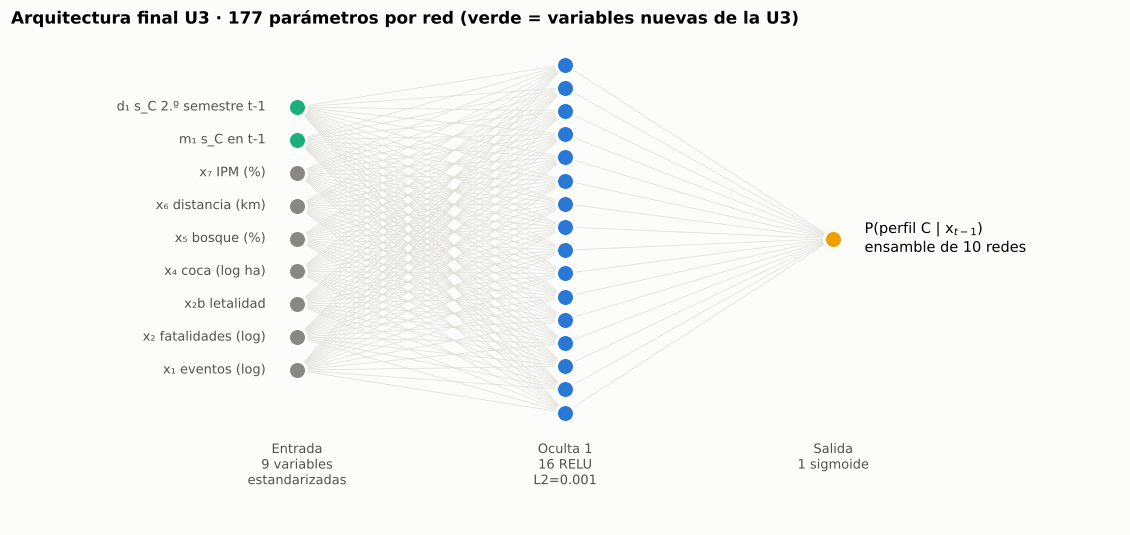

In [23]:
# =============================================================================
# 8.2 Esquema de la arquitectura final
# =============================================================================
def dibujar_arquitectura(cfg, nombres):
    tam = [len(nombres), *cfg.capas, 1]
    fig, ax = plt.subplots(figsize=(13, 5.8)); ax.axis("off"); ax.grid(False)
    xs = np.arange(len(tam)) * 3.0
    pos = [[(x, y) for y in np.linspace(-(n - 1) / 2, (n - 1) / 2, n) * min(.62, 7 / max(n, 1))] for x, n in zip(xs, tam)]
    for a, b in zip(pos[:-1], pos[1:]):
        for (x1, y1) in a:
            for (x2, y2) in b:
                ax.plot([x1, x2], [y1, y2], color=GRID, lw=.5, zorder=1)
    nuevas_ = set(V.MEMORIA + V.DINAMICA + V.VECINDAD + V.ACTORES)
    for k, capa in enumerate(pos):
        for j, (x, y) in enumerate(capa):
            color = (COL["u3"] if nombres[j] in nuevas_ else COL["D"]) if k == 0 else (COL["C"] if k == len(pos) - 1 else COL["mlp"])
            ax.scatter(x, y, s=140, color=color, edgecolor=FONDO, lw=2, zorder=3)
    for (x, y), n in zip(pos[0], nombres):
        ax.text(x - .35, y, V.ETIQ.get(n, n), ha="right", va="center", fontsize=8.5, color=TINTA2)
    ax.text(pos[-1][0][0] + .35, 0, f"P(perfil C | x$_{{t-1}}$)\nensamble de {K_ENS} redes", ha="left", va="center", fontsize=9.5)
    top = max(max(abs(y) for _, y in c) for c in pos)
    desc = [f"Entrada\n{len(nombres)} variables\nestandarizadas"] + [f"Oculta {i}\n{u} {cfg.activacion.upper()}\nL2={cfg.l2:g}" for i, u in enumerate(cfg.capas, 1)] + ["Salida\n1 sigmoide"]
    for x, d_ in zip(xs, desc):
        ax.text(x, -top - .55, d_, ha="center", va="top", fontsize=8.5, color=TINTA2)
    ax.set_title(f"Arquitectura final U3 · {N_PAR_FINAL} parámetros por red (verde = variables nuevas de la U3)")
    ax.set_xlim(xs[0] - 3.2, xs[-1] + 3.2); ax.set_ylim(-top - 2.1, top + .6)
    return fig
fig = dibujar_arquitectura(FINAL.red, VARS_FINAL); guardar(fig, "fig09_arquitectura_final"); plt.show()

## 8.2 Curvas de desempeño del modelo final frente al base

Entrenamos las dos especificaciones con 2021–2024 y registramos la BCE de entrenamiento y de validación (2025) en
cada época, con 5 semillas y hasta 3 veces el presupuesto. Así se ve si los 560 pasos caen cerca del óptimo de
generalización también con las variables nuevas, y cómo cambia la brecha entre entrenamiento y validación.

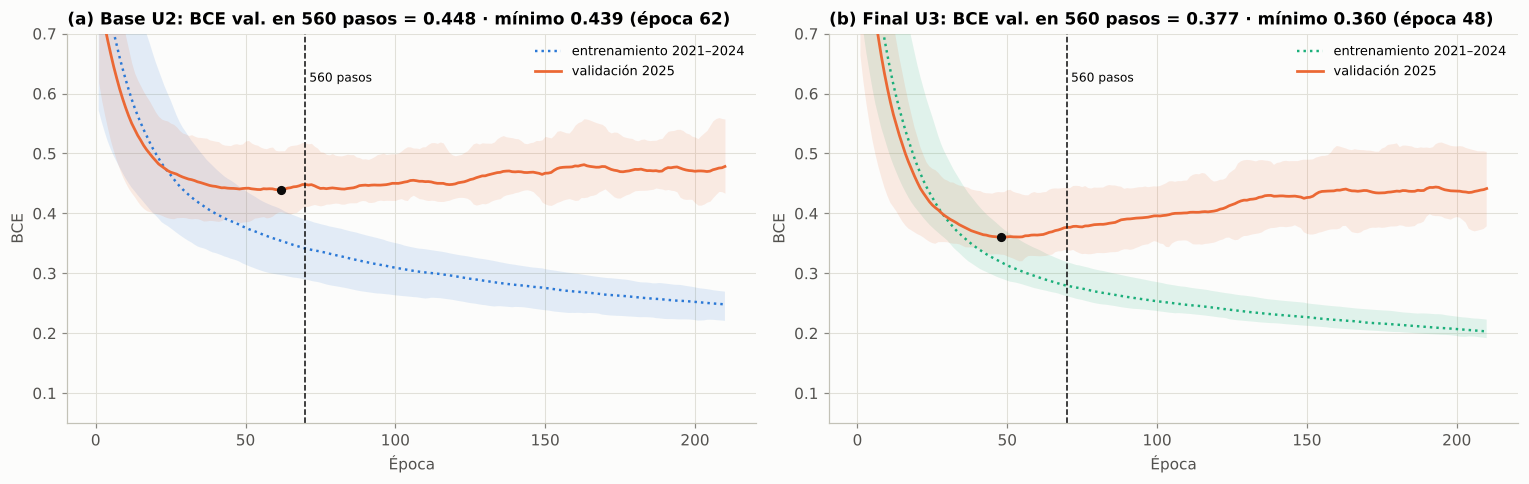

,BCE train (560 pasos),BCE val (560 pasos),Brecha val − train,BCE val mínima (media),BCE val al final (3x)
Base U2,"0,341","0,448","0,107","0,439","0,478"
Final U3,"0,279","0,377","0,097","0,360","0,441"


In [24]:
# =============================================================================
# 8.3 Curvas de aprendizaje (2021-2024 -> validación 2025), 5 semillas, 3x el presupuesto
# =============================================================================
CURVAS = {}
for nombre, spec_c in [("Base U2", BASE_U2), ("Final U3", FINAL)]:
    CURVAS[nombre] = [curva_entrenamiento(datos, replace(spec_c, semillas=(s,)), epocas=3 * EP_560, semilla=s) for s in SEM5]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (nombre, Hs), color in zip(axes, CURVAS.items(), [COL["mlp"], COL["u3"]]):
    tr_ = np.array([h["bce_tr"] for h in Hs]); va_ = np.array([h["bce_va"] for h in Hs]); ep_ = Hs[0]["epoca"]
    ax.fill_between(ep_, tr_.min(0), tr_.max(0), color=color, alpha=.12, lw=0); ax.plot(ep_, tr_.mean(0), color=color, lw=1.6, ls=":", label="entrenamiento 2021–2024")
    ax.fill_between(ep_, va_.min(0), va_.max(0), color=COL["val"], alpha=.12, lw=0); ax.plot(ep_, va_.mean(0), color=COL["val"], lw=1.8, label="validación 2025")
    k_min = int(np.argmin(va_.mean(0))); ax.scatter(ep_[k_min], va_.mean(0)[k_min], color=TINTA, zorder=4, s=25)
    ax.axvline(EP_560, color=TINTA, lw=1, ls="--"); ax.text(EP_560, .62, " 560 pasos", fontsize=8)
    ax.set_ylim(.05, .7); ax.set_xlabel("Época"); ax.set_ylabel("BCE"); ax.legend(fontsize=8.5)
    ax.set_title(f"({'ab'[nombre == 'Final U3']}) {nombre}: BCE val. en 560 pasos = {va_.mean(0)[EP_560 - 1]:.3f} · mínimo {va_.mean(0)[k_min]:.3f} (época {ep_[k_min]})")
fig.tight_layout(); guardar(fig, "fig10_curvas_aprendizaje"); plt.show()
resumen_curvas = pd.DataFrame({n: {"BCE train (560 pasos)": np.mean([h["bce_tr"][EP_560 - 1] for h in Hs]), "BCE val (560 pasos)": np.mean([h["bce_va"][EP_560 - 1] for h in Hs]),
                                   "Brecha val − train": np.mean([h["bce_va"][EP_560 - 1] - h["bce_tr"][EP_560 - 1] for h in Hs]),
                                   "BCE val mínima (media)": float(np.min(np.array([h["bce_va"] for h in Hs]).mean(0))),
                                   "BCE val al final (3x)": np.mean([h["bce_va"][-1] for h in Hs])} for n, Hs in CURVAS.items()}).T
tabla(resumen_curvas, dec=3)

**Lectura de las curvas.**

* El presupuesto de 560 pasos (70 épocas) sigue cerca del óptimo de generalización. En el modelo final, la BCE de
  validación 2025 en el paso 560 es 0,377 (media de 5 semillas), frente a un mínimo de 0,360. Entrenar 3 veces más la
  sube a 0,441, que es sobreajuste. El presupuesto de la U2 (D10) sigue siendo válido con las variables nuevas. Este
  0,377 y el 0,359 de la rejilla de §6.8 son la misma configuración con distintas semillas (5 aquí, 3 allá).
* El modelo final aprende más y generaliza mejor a la vez: baja la BCE de entrenamiento (0,341 → 0,279) y la de
  validación (0,448 → 0,377), y la brecha entre ambas se reduce de 0,107 a 0,097. La capacidad es la misma, así que la
  mejora viene de la información de entrada, coherente con §6.11.
* Las bandas entre semillas son estrechas en ambas curvas: el entrenamiento es estable (convergencia verificada en la
  U2, §11.1).

---
# 9. Evaluación antes vs. después

## 9.1 Origen móvil 2023–2025 (selección)

Comparamos dos versiones del "antes". La primera es el modelo base entregado en la U2 (MLP 7 → 16 → 1, semilla 42),
que la U2 documentó en la cola desfavorable entre semillas. La segunda es la misma arquitectura base promediada sobre
las mismas 10 semillas del modelo final, para que la diferencia no mezcle el efecto de las variables con el del
ensamble. "Después" es el modelo final de la U3 (ensamble de 10 redes). Como rival agregamos, además de la persistencia,
su versión calibrada (§3.1, regla 3). Las comparaciones pareadas y los intervalos usan bootstrap por departamento: se
remuestrean territorios completos con sus tres años, porque los años de un mismo departamento no son independientes.

In [25]:
# =============================================================================
# 9.1 Antes vs. después en el origen móvil 2023-2025, con IC y pruebas pareadas
# =============================================================================
evaluar(replace(BASE_U2, nombre="MLP base U2 (semilla 42)"), semillas=(C.SEED,))
evaluar(replace(BASE_U2, nombre=f"MLP base U2 (ensamble {K_ENS})"), semillas=tuple(range(1, K_ENS + 1)))
r_fin = RES["I7 20 semillas"]; oosF = r_fin["oos"].copy(); oosF["final"] = P20[:K_ENS].mean(0)
if CALIBRACION != "ninguna":
    oosF["final"] = calibrar_adelante(oosF, oosF["final"].values, CALIBRACION)
oosF["antes"] = RES["MLP base U2 (semilla 42)"]["oos"]["p"].values
oosF["antes10"] = RES[f"MLP base U2 (ensamble {K_ENS})"]["oos"]["p"].values
oosF["logistica"] = RES["Logística (mismas variables)"]["oos"]["p"].values
oosF["pers"] = PERS["p"].values
oosF["pers_cal"] = PERS_CAL["p"].values
assert (oosF["y"].values == PERS["y"].values).all() and (oosF["y"].values == PERS_CAL["y"].values).all()
MODELOS_9 = {"Persistencia": "pers", "Persistencia calibrada (rival agregado tras la revisión)": "pers_cal",
             "Antes: MLP base U2 (semilla 42, entregado)": "antes", f"Antes: MLP base U2 (ensamble {K_ENS})": "antes10",
             "Logística (mismas variables)": "logistica", "Después: MLP U3 (ensamble)": "final"}
T91 = pd.DataFrame({k: E.metricas(oosF.y, oosF[c], transicion=oosF.transicion) for k, c in MODELOS_9.items()}).T
tabla(T91[["ROC-AUC", "Log-loss", "Brier", "ECE", "MCC", "Exactitud", "Sensibilidad C", "Especificidad D", "Transiciones acertadas", "Transiciones"]], dec=3)
ic = {k: {m: "[{:.3f} – {:.3f}]".format(*E.bootstrap_ic(oosF.y, oosF[c], fn, grupos=oosF.depto)) for m, fn in [("ROC-AUC", roc_auc_score), ("Log-loss", E.bce)]} for k, c in MODELOS_9.items()}
display(pd.DataFrame(ic).T.rename(columns=lambda c: f"IC95 {c} (por departamento)"))
PAR_91 = pd.DataFrame({f"Después vs. {k}": E.comparar_pareado(oosF.y, oosF.final, oosF[c], grupos=oosF.depto)
                       for k, c in [("persistencia", "pers"), ("persistencia calibrada", "pers_cal"), ("antes (U2, semilla 42)", "antes"),
                                    (f"antes (U2, ensamble {K_ENS})", "antes10"), ("logística", "logistica")]}).T
display(PAR_91[["n", "ΔLog-loss", "IC95 ΔLog-loss", "P(ΔLog-loss mejora)", "ΔBrier", "IC95 ΔBrier", "ΔAUC", "IC95 ΔAUC", "solo A acierta", "solo B acierta", "p McNemar"]]
        .style.format({"ΔLog-loss": "{:+.3f}", "ΔBrier": "{:+.3f}", "ΔAUC": "{:+.3f}", "P(ΔLog-loss mejora)": "{:.2f}", "p McNemar": "{:.3f}"}))

,ROC-AUC,Log-loss,Brier,ECE,MCC,Exactitud,Sensibilidad C,Especificidad D,Transiciones acertadas,Transiciones
Persistencia,"0,973","0,363","0,106","0,173","0,795","0,897","0,864","0,930","0,000",9
Persistencia calibrada (rival agregado tras la revisión),"0,966","0,328","0,099","0,116","0,778","0,885","0,818","0,953",1,9
"Antes: MLP base U2 (semilla 42, entregado)","0,913","0,407","0,132","0,084","0,659","0,816","0,682","0,953",2,9
Antes: MLP base U2 (ensamble 10),"0,933","0,376","0,120","0,094","0,644","0,816","0,727","0,907",3,9
Logística (mismas variables),"0,949","0,306","0,097","0,068","0,737","0,862","0,773","0,953",1,9
Después: MLP U3 (ensamble),"0,956","0,304","0,095","0,124","0,691","0,839","0,750","0,930",2,9


,IC95 ROC-AUC (por departamento),IC95 Log-loss (por departamento)
Persistencia,[0.916 – 0.996],[0.290 – 0.443]
Persistencia calibrada (rival agregado tras la revisión),[0.903 – 0.994],[0.236 – 0.428]
"Antes: MLP base U2 (semilla 42, entregado)",[0.812 – 0.978],[0.250 – 0.576]
Antes: MLP base U2 (ensamble 10),[0.837 – 0.987],[0.245 – 0.521]
Logística (mismas variables),[0.868 – 0.990],[0.176 – 0.453]
Después: MLP U3 (ensamble),[0.877 – 0.994],[0.186 – 0.435]


,n,ΔLog-loss,IC95 ΔLog-loss,P(ΔLog-loss mejora),ΔBrier,IC95 ΔBrier,ΔAUC,IC95 ΔAUC,solo A acierta,solo B acierta,p McNemar
Después vs. persistencia,87,-0.059,[-0.142; +0.028],0.92,-0.011,[-0.044; +0.023],-0.017,[-0.054; +0.002],2,7,0.180
Después vs. persistencia calibrada,87,-0.024,[-0.096; +0.052],0.74,-0.003,[-0.033; +0.028],-0.010,[-0.042; +0.010],2,6,0.289
"Después vs. antes (U2, semilla 42)",87,-0.103,[-0.185; -0.033],1.00,-0.036,[-0.068; -0.009],+0.043,[+0.005; +0.105],3,1,0.625
"Después vs. antes (U2, ensamble 10)",87,-0.072,[-0.114; -0.033],1.00,-0.024,[-0.043; -0.008],+0.023,[+0.002; +0.053],3,1,0.625
Después vs. logística,87,-0.002,[-0.060; +0.045],0.52,-0.002,[-0.023; +0.016],+0.007,[-0.023; +0.041],1,3,0.625


**Lectura de la comparación (2023–2025).**

* Contra el modelo de la U2 la mejora es clara. Frente al modelo entregado (semilla 42), la log-loss baja de 0,407 a
  0,304 (Δ = −0,103, IC95 por departamento [−0,185; −0,033]). Esa semilla estaba en la cola desfavorable, así que la
  comparación justa es con la misma arquitectura base promediada sobre las mismas 10 semillas: 0,376 → 0,304
  (Δ = −0,072; IC95 [−0,114; −0,033]). La mejora atribuible a $m_1$ y $d_1$ se mantiene con los dos criterios.
* Contra la persistencia cruda la ventaja es de calibración. Δ log-loss = −0,059 con IC95 [−0,142; +0,028] (el modelo
  gana en el 92 % de los remuestreos). La persistencia ordena mejor (AUC 0,973 frente a 0,956) y con umbral 0,5 clasifica
  mejor (exactitud 0,897 frente a 0,839; acierta 7 casos que el modelo falla y el modelo 2 que ella falla, McNemar
  p = 0,18), pero sus probabilidades son peores (ECE 0,173 frente a 0,124) porque usa $s^C$ como si fuera una
  probabilidad.
* Contra la persistencia calibrada (rival agregado tras la revisión) la ventaja no está demostrada: 0,328 frente
  a 0,304 (Δ = −0,024; IC95 [−0,096; +0,052]; el modelo gana en el 74 % de los remuestreos). Una logística de
  dos parámetros sobre la memoria del perfil recoge casi toda la información que usa el modelo.
* El MLP y la logística empatan con las mismas variables (Δ = −0,002). La mejora de la U3 se debe a la representación de
  los datos, y con 171 filas la red todavía no rinde más por ser no lineal.
* Las cifras de selección salen de una cascada de unas 20 comparaciones sobre las mismas 87 predicciones y por eso son
  algo optimistas (Cawley y Talbot, 2010); 2026 (§9.3) es la estimación que no pasó por la selección.

## 9.2 Generalización espacial: departamentos nunca vistos

Usamos dos esquemas. El espacial de la U3 agrupa los departamentos en 5 grupos (GroupKFold, años ≤ 2025): para
predecir un departamento en el año t, la red se entrena con los demás, incluidas sus etiquetas del mismo año t y de
años posteriores. La U2 había reportado dejar un departamento fuera, porque con la versión de scikit-learn de entonces
GroupKFold desempataba distinto según el equipo; desde scikit-learn 1.6 el desempate es estable, y usamos 5 grupos para
abaratar el cálculo. El segundo esquema, agregado tras la revisión, bloquea también el tiempo: para cada grupo y cada
año v ∈ {2023, 2024, 2025} entrena con los otros departamentos y solo con t < v. Es el escenario real de un territorio
nuevo al año siguiente, y es el único justo con la persistencia, que no se entrena.

In [26]:
# =============================================================================
# 9.2 Validación espacial (5 pliegues por departamento, años <= 2025)
# =============================================================================
SEM_ENS = tuple(range(1, K_ENS + 1))
evaluar(replace(FINAL, nombre="esp: final U3"), semillas=SEM_ENS, particiones="espacial", clave="esp: final U3")
evaluar(replace(BASE_U2, nombre="esp: base U2 ensamble"), semillas=SEM_ENS, particiones="espacial", clave="esp: base U2 ensamble")
eF, eB = RES["esp: final U3"]["oos"], RES["esp: base U2 ensamble"]["oos"]
esp_tab = pd.DataFrame({
    "Persistencia": E.metricas(PERS_E.y, PERS_E.p),
    "Antes: MLP base U2 (red individual, media)": {c: RES["esp: base U2 ensamble"]["por_semilla"][c].mean() for c in E.COLS_PRINCIPALES},
    f"Antes: MLP base U2 (ensamble {K_ENS})": E.metricas(eB.y, eB.p),
    "Logística (mismas variables)": E.metricas(RES["esp: logística referencia"]["oos"].y, RES["esp: logística referencia"]["oos"].p),
    "Después: MLP U3 (red individual, media)": {c: RES["esp: final U3"]["por_semilla"][c].mean() for c in E.COLS_PRINCIPALES},
    "Después: MLP U3 (ensamble)": E.metricas(eF.y, eF.p)}).T
print("Esquema espacial (5 grupos de departamentos, años <= 2025 mezclados):")
tabla(esp_tab[E.COLS_PRINCIPALES], dec=3)
pers_e_al = PERS_E.set_index("fila").loc[eF["fila"], "p"].values
display(pd.DataFrame({"Después vs. persistencia (espacial)": E.comparar_pareado(eF.y, eF.p, pers_e_al, grupos=eF.depto),
                      f"Después vs. antes (ensamble {K_ENS}, espacial)": E.comparar_pareado(eF.y, eF.p, eB.p.values, grupos=eF.depto)}).T[["n", "ΔLog-loss", "IC95 ΔLog-loss", "ΔAUC", "IC95 ΔAUC"]])

# Bloqueo espacial y temporal: otros departamentos, solo años anteriores al predicho
PERS_ET, PERS_CAL_ET = persistencia_oos("espacio-temporal"), persistencia_oos("espacio-temporal", calibrada=True)
evaluar(replace(FINAL, nombre="et: final U3"), semillas=SEM_ENS, particiones="espacio-temporal", clave="et: final U3")
evaluar(replace(BASE_U2, nombre="et: base U2 ensamble"), semillas=SEM_ENS, particiones="espacio-temporal", clave="et: base U2 ensamble")
evaluar(replace(LOG_F, nombre="et: logística"), particiones="espacio-temporal", clave="et: logística")
etF, etB, etL = (RES[k]["oos"] for k in ("et: final U3", "et: base U2 ensamble", "et: logística"))
assert all((x.y.values == PERS_ET.y.values).all() for x in (etF, etB, etL, PERS_CAL_ET))
ET_TAB = pd.DataFrame({"Persistencia": E.metricas(PERS_ET.y, PERS_ET.p, transicion=PERS_ET.transicion),
                       "Persistencia calibrada": E.metricas(PERS_CAL_ET.y, PERS_CAL_ET.p, transicion=PERS_CAL_ET.transicion),
                       f"Antes: MLP base U2 (ensamble {K_ENS})": E.metricas(etB.y, etB.p, transicion=etB.transicion),
                       "Logística (mismas variables)": E.metricas(etL.y, etL.p, transicion=etL.transicion),
                       "Después: MLP U3 (ensamble)": E.metricas(etF.y, etF.p, transicion=etF.transicion)}).T
print(f"Esquema espacio-temporal (5 grupos × 2023-2025, entrenamiento solo con años anteriores; n = {len(etF)}):")
tabla(ET_TAB[E.COLS_PRINCIPALES + ["Transiciones acertadas"]], dec=3)
PAR_ET = pd.DataFrame({f"Después vs. {k}": E.comparar_pareado(etF.y, etF.p, c_, grupos=etF.depto)
                       for k, c_ in [("persistencia", PERS_ET.p.values), ("persistencia calibrada", PERS_CAL_ET.p.values),
                                     (f"antes (ensamble {K_ENS})", etB.p.values), ("logística", etL.p.values)]}).T
display(PAR_ET[["n", "ΔLog-loss", "IC95 ΔLog-loss", "P(ΔLog-loss mejora)", "ΔAUC", "IC95 ΔAUC"]]
        .style.format({"ΔLog-loss": "{:+.3f}", "ΔAUC": "{:+.3f}", "P(ΔLog-loss mejora)": "{:.2f}"}))

Esquema espacial (5 grupos de departamentos, años <= 2025 mezclados):


,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE
Persistencia,"0,914","0,418","0,127","0,704","0,852","0,117"
"Antes: MLP base U2 (red individual, media)","0,855","0,476","0,154","0,566","0,779","0,048"
Antes: MLP base U2 (ensamble 10),"0,872","0,445","0,147","0,580","0,785","0,055"
Logística (mismas variables),"0,916","0,373","0,114","0,704","0,851","0,034"
"Después: MLP U3 (red individual, media)","0,915","0,373","0,116","0,666","0,832","0,046"
Después: MLP U3 (ensamble),"0,923","0,351","0,110","0,690","0,844","0,042"


,n,ΔLog-loss,IC95 ΔLog-loss,ΔAUC,IC95 ΔAUC
Después vs. persistencia (espacial),142,-0.067343,[-0.135; +0.003],0.008744,[-0.020; +0.037]
"Después vs. antes (ensamble 10, espacial)",142,-0.094656,[-0.159; -0.033],0.050477,[+0.006; +0.109]


Esquema espacio-temporal (5 grupos × 2023-2025, entrenamiento solo con años anteriores; n = 87):


,ROC-AUC,Log-loss,Brier,MCC,Exact. balanceada,ECE,Transiciones acertadas
Persistencia,"0,973","0,363","0,106","0,795","0,897","0,173","0,000"
Persistencia calibrada,"0,962","0,332","0,101","0,778","0,886","0,116",1
Antes: MLP base U2 (ensamble 10),"0,869","0,476","0,156","0,563","0,772","0,087",4
Logística (mismas variables),"0,909","0,416","0,122","0,685","0,840","0,074",3
Después: MLP U3 (ensamble),"0,932","0,361","0,117","0,664","0,828","0,092",3


,n,ΔLog-loss,IC95 ΔLog-loss,P(ΔLog-loss mejora),ΔAUC,IC95 ΔAUC
Después vs. persistencia,87,-0.002,[-0.114; +0.130],0.53,-0.041,[-0.103; -0.007]
Después vs. persistencia calibrada,87,+0.029,[-0.075; +0.154],0.33,-0.030,[-0.087; +0.001]
Después vs. antes (ensamble 10),87,-0.115,[-0.186; -0.052],1.00,+0.063,[+0.014; +0.137]
Después vs. logística,87,-0.055,[-0.236; +0.067],0.77,+0.023,[-0.036; +0.093]


**Lectura.** En departamentos nunca vistos el cambio frente a la U2 es grande. Con 5 grupos de departamentos, la red
individual pasa de log-loss 0,476 (base) a 0,373 (final), y el ensamble de 0,445 a 0,351, por debajo de la
persistencia (0,418; Δ = −0,067, IC95 [−0,135; +0,003]). Ese esquema, sin embargo, deja que la red aprenda de otros
departamentos en el mismo año que predice, ventaja que la persistencia no tiene. Con bloqueo espacial y temporal, que es
el escenario real de un territorio nuevo al año siguiente, el modelo obtiene 0,361, la persistencia 0,363
(Δ = −0,002; IC95 [−0,114; +0,130]), la persistencia calibrada 0,332 y la logística 0,416. Las variables de
composición transfieren mucho mejor que las estructurales de la U2, y el ensamble de redes obtiene menos log-loss que la
logística (Δ = −0,055; IC95 [−0,236; +0,067]), que es el argumento medible, aunque débil, para mantener el MLP. La ventaja
frente a la inercia en territorios nuevos no está demostrada: la persistencia calibrada es la mejor de las cinco.

## 9.3 Prueba final 2026 (una sola vez)

El modelo, las variables, la configuración, el ensamble, la calibración y el umbral ya están fijados (§8.1,
`configuracion.json`). Ahora, por única vez, se entrena con 2021–2025 y se predice 2026 (29 departamentos,
etiqueta de 33 semanas; §2.3 estimó un 95 % de coincidencia con la etiqueta anual).

In [27]:
# =============================================================================
# 9.3 Prueba 2026: entrenamiento con 2021-2025, una sola evaluación
# =============================================================================
tr26, te26 = (datos.anio <= 2025).values, (datos.anio == 2026).values
T26 = datos.loc[te26, ["depto", "departamento", "anio", "y", "s_C", "perfil", "perfil_prev", "transicion", "eventos"]].copy()
T26["pers"] = P.persistencia(datos, tr26, te26)
T26["pers_cal"] = P.persistencia_calibrada(datos, tr26, te26)
for nombre, s in [("antes", replace(BASE_U2, semillas=(C.SEED,))), ("antes10", replace(BASE_U2, semillas=SEM_ENS)), ("logistica", LOG_F), ("final", FINAL)]:
    m_, e_ = P.entrenar_especificacion(datos, SEQ, s, tr26)
    T26[nombre] = P.predecir_especificacion(m_, e_, datos, SEQ, s, te26)
    if nombre == "final":
        MODELOS_2025, ESC_2025 = m_, e_
if CALIBRACION != "ninguna":
    cal_26 = M.Calibrador(CALIBRACION).ajustar(P20[:K_ENS].mean(0), oosF.y.values)   # calibrador con 2023-2025 (sin calibrar)
    T26["final"] = cal_26.aplicar(T26["final"])
T93 = pd.DataFrame({k: E.metricas(T26.y, T26[c], transicion=T26.transicion) for k, c in MODELOS_9.items()}).T
spec_emb = replace(RES["Embedding de departamento"]["spec"], semillas=tuple(range(1, K_ENS + 1)))
m_, e_ = P.entrenar_especificacion(datos, SEQ, spec_emb, tr26)
T26["emb"] = P.predecir_especificacion(m_, e_, datos, SEQ, spec_emb, te26)
T93.loc["(alternativa no adoptada) MLP + embedding"] = pd.Series(E.metricas(T26.y, T26.emb, transicion=T26.transicion))
doc26 = pd.read_csv(RAIZ / "referencias_u2" / "metricas_modelos.csv").set_index(["Modelo", "Conjunto"])
T93.loc["(referencia) U2 fase 2 documentado", ["ROC-AUC", "Log-loss", "Brier", "MCC", "Exactitud"]] = doc26.loc[("MLP fase 2", "Prueba"), ["ROC-AUC", "Log-loss", "Brier", "MCC", "Exactitud"]].values
tabla(T93[["ROC-AUC", "Log-loss", "Brier", "ECE", "MCC", "Exactitud", "Sensibilidad C", "Especificidad D", "Transiciones acertadas", "Transiciones"]], dec=3)
ic26 = {k: {m: "{:.3f} [{:.3f} – {:.3f}]".format(fn(T26.y, T26[c]), *E.bootstrap_ic(T26.y, T26[c], fn)) for m, fn in [("ROC-AUC", roc_auc_score), ("Log-loss", E.bce)]} for k, c in MODELOS_9.items()}
display(pd.DataFrame(ic26).T)
PAR_26 = pd.DataFrame({f"Después vs. {k}": E.comparar_pareado(T26.y, T26.final, T26[c])
                       for k, c in [("persistencia", "pers"), ("persistencia calibrada", "pers_cal"), ("antes (U2, semilla 42)", "antes"),
                                    (f"antes (U2, ensamble {K_ENS})", "antes10"), ("logística", "logistica")]}).T
display(PAR_26[["n", "ΔLog-loss", "IC95 ΔLog-loss", "ΔAUC", "IC95 ΔAUC", "solo A acierta", "solo B acierta", "p McNemar"]]
        .style.format({"ΔLog-loss": "{:+.3f}", "ΔAUC": "{:+.3f}", "p McNemar": "{:.3f}"}))
print("Transiciones de 2026:")
display(T26[T26.transicion][["departamento", "perfil_prev", "perfil", "s_C", "pers", "pers_cal", "antes", "antes10", "final"]].round(2).style.hide(axis="index"))

,ROC-AUC,Log-loss,Brier,ECE,MCC,Exactitud,Sensibilidad C,Especificidad D,Transiciones acertadas,Transiciones
Persistencia,"0,948","0,429","0,131","0,207","0,755","0,862",1,"0,733","0,000",4
Persistencia calibrada (rival agregado tras la revisión),"0,948","0,351","0,105","0,150","0,755","0,862",1,"0,733","0,000",4
"Antes: MLP base U2 (semilla 42, entregado)","0,852","0,524","0,166","0,104","0,517","0,759","0,714","0,800",1,4
Antes: MLP base U2 (ensamble 10),"0,862","0,470","0,157","0,109","0,517","0,759","0,714","0,800",1,4
Logística (mismas variables),"0,929","0,383","0,129","0,114","0,531","0,759","0,857","0,667","0,000",4
Después: MLP U3 (ensamble),"0,900","0,380","0,121","0,074","0,672","0,828","0,929","0,733","0,000",4
(alternativa no adoptada) MLP + embedding,"0,933","0,314","0,100","0,123","0,812","0,897",1,"0,800",1,4
(referencia) U2 fase 2 documentado,"0,829","0,547","0,174",–,"0,517","0,759",–,–,–,–


,ROC-AUC,Log-loss
Persistencia,0.948 [0.843 – 1.000],0.429 [0.344 – 0.519]
Persistencia calibrada (rival agregado tras la revisión),0.948 [0.843 – 1.000],0.351 [0.222 – 0.511]
"Antes: MLP base U2 (semilla 42, entregado)",0.852 [0.686 – 0.971],0.524 [0.316 – 0.806]
Antes: MLP base U2 (ensamble 10),0.862 [0.695 – 0.981],0.470 [0.303 – 0.662]
Logística (mismas variables),0.929 [0.814 – 0.990],0.383 [0.212 – 0.593]
Después: MLP U3 (ensamble),0.900 [0.757 – 0.990],0.380 [0.210 – 0.586]


,n,ΔLog-loss,IC95 ΔLog-loss,ΔAUC,IC95 ΔAUC,solo A acierta,solo B acierta,p McNemar
Después vs. persistencia,29,-0.049,[-0.162; +0.092],-0.048,[-0.171; +0.030],0,1,1.000
Después vs. persistencia calibrada,29,+0.029,[-0.055; +0.125],-0.048,[-0.171; +0.030],0,1,1.000
"Después vs. antes (U2, semilla 42)",29,-0.144,[-0.270; -0.033],+0.048,[-0.011; +0.124],3,1,0.625
"Después vs. antes (U2, ensamble 10)",29,-0.090,[-0.162; -0.024],+0.038,[+0.000; +0.093],3,1,0.625
Después vs. logística,29,-0.003,[-0.090; +0.100],-0.029,[-0.115; +0.036],2,0,0.500


Transiciones de 2026:


departamento,perfil_prev,perfil,s_C,pers,pers_cal,antes,antes10,final
Bolívar,C,D,0.310000,0.530000,0.590000,0.760000,0.770000,0.810000
Chocó,C,D,0.450000,0.710000,0.870000,0.960000,0.880000,0.880000
Magdalena,C,D,0.470000,0.560000,0.660000,0.400000,0.490000,0.550000
Valle del Cauca,C,D,0.500000,0.520000,0.580000,0.650000,0.670000,0.760000


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


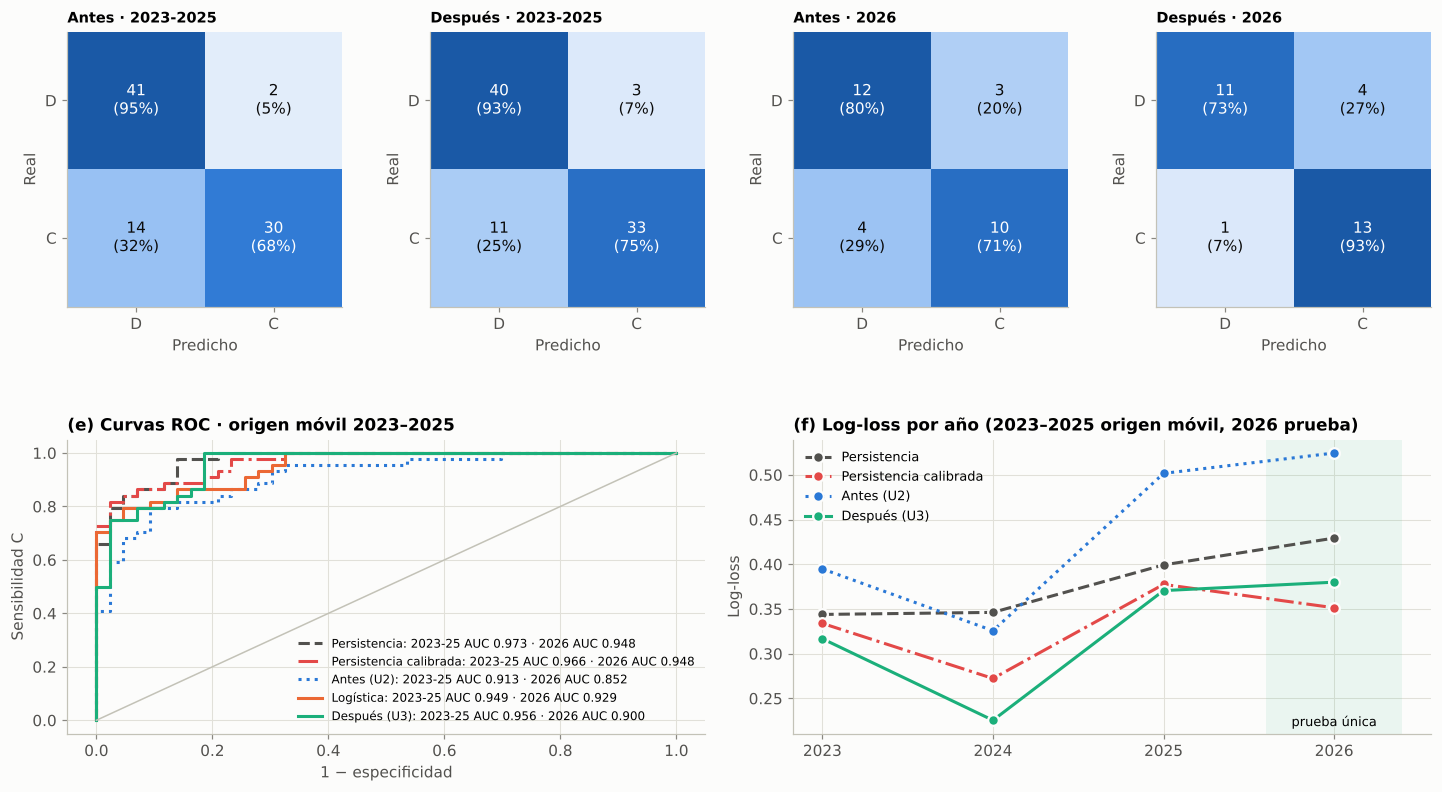

In [28]:
# =============================================================================
# 9.4 Matrices de confusión, ROC y desempeño por año (antes vs. después vs. persistencia)
# =============================================================================
fig = plt.figure(figsize=(16, 8.4)); gs = fig.add_gridspec(2, 4, hspace=.42, wspace=.32)
casos = [("Antes · 2023-2025", oosF.y, oosF.antes), ("Después · 2023-2025", oosF.y, oosF.final), ("Antes · 2026", T26.y, T26.antes), ("Después · 2026", T26.y, T26.final)]
for k, (tit, y_, p_) in enumerate(casos):
    ax = fig.add_subplot(gs[0, k]); cm = confusion_matrix(np.asarray(y_).astype(int), (np.asarray(p_) >= UMBRAL).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap=G.CMAP_P, vmin=0, vmax=cm.max() * 1.3); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / max(cm[i].sum(), 1):.0%})", ha="center", va="center", fontsize=10, color="white" if cm[i, j] > cm.max() * .65 else TINTA)
    ax.set_xticks([0, 1], ["D", "C"]); ax.set_yticks([0, 1], ["D", "C"]); ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(tit, fontsize=9.5)
ax = fig.add_subplot(gs[1, :2])
for nombre, c, color, ls in [("Persistencia", "pers", COL["pers"], "--"), ("Persistencia calibrada", "pers_cal", COL["A"], "-."), ("Antes (U2)", "antes", COL["mlp"], ":"), ("Logística", "logistica", COL["logit"], "-"), ("Después (U3)", "final", COL["u3"], "-")]:
    fpr, tpr, _ = roc_curve(oosF.y, oosF[c]); ax.plot(fpr, tpr, color=color, ls=ls, label=f"{nombre}: 2023-25 AUC {roc_auc_score(oosF.y, oosF[c]):.3f} · 2026 AUC {roc_auc_score(T26.y, T26[c]):.3f}")
ax.plot([0, 1], [0, 1], color=EJE, lw=1); ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad C"); ax.set_title("(e) Curvas ROC · origen móvil 2023–2025"); ax.legend(fontsize=7.8, loc="lower right")
ax = fig.add_subplot(gs[1, 2:])
anual = pd.concat([oosF.assign(particion=oosF.particion.astype(str)), T26.assign(particion="2026")])
for nombre, c, color, ls in [("Persistencia", "pers", COL["pers"], "--"), ("Persistencia calibrada", "pers_cal", COL["A"], "-."), ("Antes (U2)", "antes", COL["mlp"], ":"), ("Después (U3)", "final", COL["u3"], "-")]:
    s_ = anual.groupby("particion").apply(lambda g: E.bce(g.y, g[c]))
    ax.plot(s_.index, s_.values, color=color, ls=ls, marker="o", mec=FONDO, mew=1.5, ms=7, label=nombre)
ax.axvspan(2.6, 3.4, color=COL["test"], alpha=.08, lw=0); ax.text(3, ax.get_ylim()[0] + .005, "prueba única", ha="center", va="bottom", fontsize=8.5)
ax.set_ylabel("Log-loss"); ax.set_title("(f) Log-loss por año (2023–2025 origen móvil, 2026 prueba)"); ax.legend(fontsize=8.5)
guardar(fig, "fig11_antes_despues"); plt.show()

**Lectura de la prueba 2026 (única evaluación).**

* El modelo final mejora frente al de la U2 en el año de prueba. Log-loss 0,380 frente a 0,524 del modelo entregado
  (0,547 en la fase 2 documentada en la U2) y 0,470 de la base con ensamble (Δ = −0,090; IC95 [−0,162; −0,024]).
  ECE 0,074, el mejor calibrado de los modelos de la tabla.
* Frente a la inercia no hay ventaja demostrada. Frente a la persistencia cruda, Δ = −0,049 con IC95 [−0,162; +0,092].
  La persistencia calibrada obtiene 0,351, mejor que el modelo (Δ = +0,029; IC95 [−0,055; +0,125]).
* La degradación desde la selección es moderada: log-loss 0,304 → 0,380 y AUC 0,956 → 0,900. 2026 es un año de
  desescalamiento, y el AUC de la persistencia también bajó (0,973 → 0,948).
* Lo que falló: las 4 transiciones de 2026, todas C → D (Bolívar, Chocó, Magdalena y Valle del Cauca). El modelo les dio
  entre 0,55 y 0,88 de probabilidad de C y no acertó ninguna; la persistencia tampoco, por construcción, y el modelo de la
  U2 acertó Magdalena (0,40). Tres de ellas tienen $s^C$ de 2026 entre 0,45 y 0,50, en la franja que §2.3 identificó como
  ambigua con 33 semanas, así que parte de ese error puede corregirse cuando cierre el año. La sensibilidad para C es alta
  (0,93: solo un C perdido, Cesar) y la especificidad de 0,73 resume esas desescaladas.
* El embedding descartado salió mejor en 2026, y lo reportamos tal cual. Obtuvo log-loss 0,314, AUC 0,933 y MCC 0,81, y
  acertó 1 de las 4 transiciones. Esto debilita en parte el argumento de la regla 8: en 2023–2025 acertaba menos
  transiciones, en 2026 una más. No cambiamos el modelo, porque elegir ahora con 2026 convertiría la prueba en un conjunto
  de selección y su cifra dejaría de ser una estimación válida. Mientras el uso se limite a los mismos 33 departamentos,
  los efectos fijos territoriales tienen valor predictivo que las variables actuales no capturan. Queda como
  recomendación (R7, §13): reevaluar el embedding cuando cierre 2026, con prueba en 2027, y a escala municipal
  reemplazarlo por las variables que expliquen esos efectos ($x_3$ municipal, distancia a cabecera).

---
# 10. Análisis crítico del desempeño

## 10.1 ¿Dónde se equivoca el modelo final y qué errores corrigió?

departamento,anio,perfil_prev,perfil,s_C,eventos,P persist.,P antes,P después,transicion,cerca del umbral
Casanare,2023,C,C,0.69,13,0.93,0.23,0.32,False,False
Huila,2023,C,C,0.60,83,0.73,0.27,0.36,False,False
Cesar,2023,C,C,0.52,124,0.51,0.31,0.38,False,True
Bolívar,2023,D,D,0.35,409,0.39,0.66,0.53,False,False
Valle del Cauca,2023,C,D,0.44,285,0.61,0.86,0.84,True,True
Casanare,2024,C,C,0.81,31,0.69,0.09,0.41,False,False
Huila,2024,C,C,0.64,76,0.60,0.44,0.47,False,False
Valle del Cauca,2024,D,D,0.44,288,0.44,0.48,0.51,False,True
Córdoba,2025,D,C,0.55,131,0.48,0.19,0.21,True,True
Magdalena,2025,D,C,0.56,131,0.40,0.22,0.21,True,True


,Errores después,Aciertos después
% transiciones,"0,58","0,02"
% a ±10 pp del umbral,"0,58","0,19"
Mediana de eventos,131,92
Filas,19,97


acierto después,después acierta,después falla
acierto antes,,
antes acierta,91,2
antes falla,6,17


Transiciones 2023-2026: 13 | persistencia: 0 | persistencia calibrada: 1 | antes (semilla 42): 3 | antes (ensamble 10): 4 | después: 2
Regla de decisión por bandas frente al perfil observado:


Filas  En banda consolidada  Aciertos en banda consolidada C consolidado (C real / total) D consolidado (D real / total)  En transición
Conjunto  Modelo                                                                                                                                                         
2023-2025 Después: MLP U3            87                    71                             66                          31/32                          35/39             16
          Persistencia               87                    45                             45                          19/19                          26/26             42
          Persistencia calibrada     87                    56                             54                          21/21                          33/35             31
2026      Después: MLP U3            29                    24                             21                          10/13                          11/11              5
          Persistencia               29                    13                             12                            5/6                            7/7             16
          Persistencia calibrada     29                    20                             19                          12/13                            7/7              9

P(C) después                   Perfil observado               
anio                    2023  2024  2025  2026             2023 2024 2025 2026
departamento                                                                  
Arauca                  0.84  0.77  0.85  0.79                C    C    C    C
Bolívar                 0.53  0.35  0.31  0.81                D    D    C    D
Casanare                0.32  0.41  0.64  0.50                C    C    C    C
Cesar                   0.38  0.46  0.25  0.45                C    D    C    C
Chocó                   0.85  0.85  0.92  0.88                C    C    C    D
Huila                   0.36  0.47  0.63  0.77                C    C    C    C
Meta                    0.78  0.41  0.25  0.76                C    D    C    C
Valle del Cauca         0.84  0.51  0.48  0.76                D    D    C    D

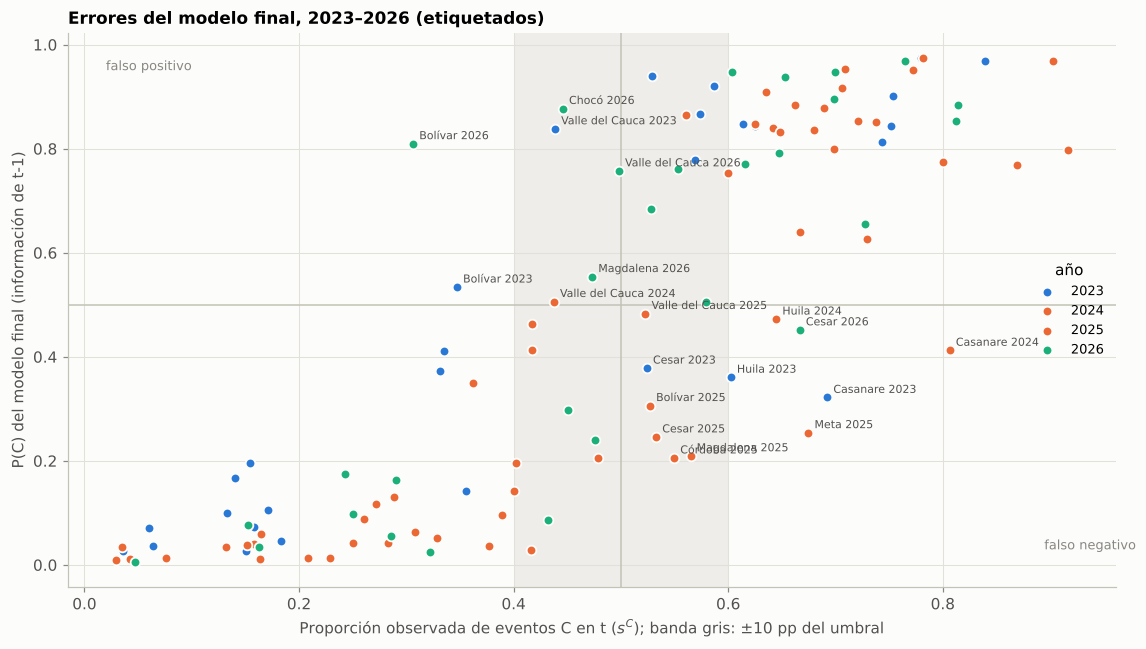

In [29]:
# =============================================================================
# 10.1 Análisis de errores: 2023-2025 (origen móvil) + 2026 (prueba)
# =============================================================================
cols_f = ["departamento", "depto", "anio", "y", "s_C", "perfil", "perfil_prev", "transicion", "eventos", "pers", "pers_cal", "antes", "antes10", "final"]
fuera = pd.concat([oosF[cols_f], T26[cols_f]], ignore_index=True)
fuera["acierto antes"] = (fuera.antes >= UMBRAL) == (fuera.y == 1)
fuera["acierto después"] = (fuera.final >= UMBRAL) == (fuera.y == 1)
fuera["cerca del umbral"] = (fuera.s_C - .5).abs() < .1
err = fuera[~fuera["acierto después"]].sort_values(["anio", "final"])
display(err[["departamento", "anio", "perfil_prev", "perfil", "s_C", "eventos", "pers", "antes", "final", "transicion", "cerca del umbral"]]
        .rename(columns={"pers": "P persist.", "antes": "P antes", "final": "P después"})
        .style.format({"s_C": "{:.2f}", "P persist.": "{:.2f}", "P antes": "{:.2f}", "P después": "{:.2f}"}).hide(axis="index"))
perfil_err = pd.DataFrame({
    "Errores después": [err.transicion.mean(), err["cerca del umbral"].mean(), err.eventos.median(), len(err)],
    "Aciertos después": [fuera.loc[fuera["acierto después"], "transicion"].mean(), fuera.loc[fuera["acierto después"], "cerca del umbral"].mean(),
                         fuera.loc[fuera["acierto después"], "eventos"].median(), int(fuera["acierto después"].sum())]},
    index=["% transiciones", "% a ±10 pp del umbral", "Mediana de eventos", "Filas"])
tabla(perfil_err, dec=2)
cruce = pd.crosstab(fuera["acierto antes"].map({True: "antes acierta", False: "antes falla"}),
                    fuera["acierto después"].map({True: "después acierta", False: "después falla"}))
display(cruce)
tr_f = fuera[fuera.transicion]
tr_ok = lambda c: int(((tr_f[c] >= UMBRAL) == (tr_f.y == 1)).sum())
print(f"Transiciones 2023-2026: {len(tr_f)} | persistencia: {tr_ok('pers')} | persistencia calibrada: {tr_ok('pers_cal')} | "
      f"antes (semilla 42): {tr_ok('antes')} | antes (ensamble {K_ENS}): {tr_ok('antes10')} | después: {tr_ok('final')}")
# Regla de decisión por bandas (P >= 0,7 C consolidado; 0,3-0,7 transición; < 0,3 D consolidado) frente al perfil observado
def banda(p_):
    return np.where(np.asarray(p_) >= .7, "C consolidado", np.where(np.asarray(p_) >= .3, "Transición", "D consolidado"))
filas_b = []
for conj, df_ in [("2023-2025", fuera[fuera.anio <= 2025]), ("2026", fuera[fuera.anio == 2026])]:
    for nombre, c in [("Después: MLP U3", "final"), ("Persistencia", "pers"), ("Persistencia calibrada", "pers_cal")]:
        b_ = banda(df_[c]); cons = b_ != "Transición"
        ok_ = ((b_ == "C consolidado") & (df_.perfil == "C")) | ((b_ == "D consolidado") & (df_.perfil == "D"))
        filas_b.append({"Conjunto": conj, "Modelo": nombre, "Filas": len(df_), "En banda consolidada": int(cons.sum()),
                        "Aciertos en banda consolidada": int(ok_.sum()),
                        "C consolidado (C real / total)": f"{int(((b_ == 'C consolidado') & (df_.perfil == 'C')).sum())}/{int((b_ == 'C consolidado').sum())}",
                        "D consolidado (D real / total)": f"{int(((b_ == 'D consolidado') & (df_.perfil == 'D')).sum())}/{int((b_ == 'D consolidado').sum())}",
                        "En transición": int((~cons).sum())})
BANDAS = pd.DataFrame(filas_b).set_index(["Conjunto", "Modelo"])
print("Regla de decisión por bandas frente al perfil observado:")
display(BANDAS)
seg = fuera[fuera.depto.isin(["arauca", "casanare", "meta", "cesar", "valle del cauca", "bolivar", "choco", "huila"])].pivot_table(index="departamento", columns="anio", values="final").round(2)
obs = fuera.pivot_table(index="departamento", columns="anio", values="perfil", aggfunc="first").reindex(seg.index)
display(pd.concat({"P(C) después": seg, "Perfil observado": obs}, axis=1))

fig, ax = plt.subplots(figsize=(10.5, 6))
for anio_, color in zip(sorted(fuera.anio.unique()), [COL["mlp"], COL["logit"], COL["val"], COL["test"]]):
    s_ = fuera[fuera.anio == anio_]
    ax.scatter(s_.s_C, s_.final, s=40, color=color, edgecolor=FONDO, lw=1.2, label=str(anio_), zorder=3)
for _, r in err.iterrows():
    ax.annotate(f"{r.departamento} {r.anio}", (r.s_C, r.final), xytext=(4, 3), textcoords="offset points", fontsize=7.2, color=TINTA2)
ax.axvline(.5, color=EJE, lw=1); ax.axhline(UMBRAL, color=EJE, lw=1)
ax.axvspan(.4, .6, color=GRID, alpha=.5, lw=0, zorder=0)
ax.text(.02, .97, "falso positivo", fontsize=8.5, color=TENUE, va="top"); ax.text(.98, .03, "falso negativo", fontsize=8.5, color=TENUE, ha="right")
ax.set_xlabel("Proporción observada de eventos C en t ($s^C$); banda gris: ±10 pp del umbral"); ax.set_ylabel("P(C) del modelo final (información de t-1)")
ax.set_title("Errores del modelo final, 2023–2026 (etiquetados)"); ax.legend(fontsize=8.5, title="año", loc="center right")
fig.tight_layout(); guardar(fig, "fig12_errores"); plt.show()

**Lectura del análisis de errores.**

* Los errores se concentran donde el diagnóstico de la U2 lo predijo. De los 19 errores en 2023–2026, el 58 % son
  transiciones de perfil (frente al 2 % entre los aciertos) y el 58 % tiene $s^C$ a ±10 pp del umbral (frente al 19 %).
  El modelo falla donde la etiqueta es ambigua o donde el territorio cambia de régimen.
* Frente al modelo de la U2, 6 casos pasan de error a acierto y 2 de acierto a error; 17 fallan en ambos. Los fallos
  compartidos son casi todos transiciones.
* Arauca, el error estructural de la U2, quedó corregido: P(C) = 0,84, 0,77, 0,85 y 0,79 en 2023–2026, todos C. La
  persistencia del frente ELN entra por $m_1$ y $d_1$ (§6.3).
* Persisten cuatro patrones:
  1. Escaladas D → C de 2025 (Córdoba, Magdalena, Cesar, Meta, Bolívar y Valle): un cambio de coyuntura nacional, la
     ruptura de los diálogos, que la información de 2024 no contenía.
  2. Desescaladas C → D de 2026 (§9.3).
  3. Huila, que es C en 2023 y 2024 y recibe P(C) de 0,36 y 0,47.
  4. Casanare, con pocos eventos (13 a 31) y P(C) baja todos los años, aunque es C.

  Los dos primeros requieren información que no está en ACLED agregado ni en el conteo anual de actores de UCDP
  (I3 no ayudó): señales políticas como ceses al fuego o negociaciones. Los otros dos son ruido de pocos datos o de
  departamentos cerca del umbral.
* Transiciones. De 13 transiciones en 2023–2026, el modelo final acierta 2, el de la U2 3 (con ensamble,
  4), la persistencia calibrada 1 y la persistencia 0. La U3 mejoró la probabilidad en los territorios
  estables sin ganar capacidad de anticipar cambios.
* Regla de decisión. La decisión usa bandas (P ≥ 0,7, 0,3–0,7 y < 0,3) y no el umbral 0,5. En 2023–2025, 71 de 87
  filas caen en una banda consolidada y 66 de ellas aciertan (31 de 32 en C y 35 de 39 en D); en 2026,
  24 de 29, con 21 aciertos (10 de 13 en C y 11 de 11 en D). Con la persistencia cruda, 42 de las 87
  filas quedan en transición y la banda informa poco.

## 10.2 ¿Qué aprendió la red? Importancia por permutación e interacción memoria × estructura

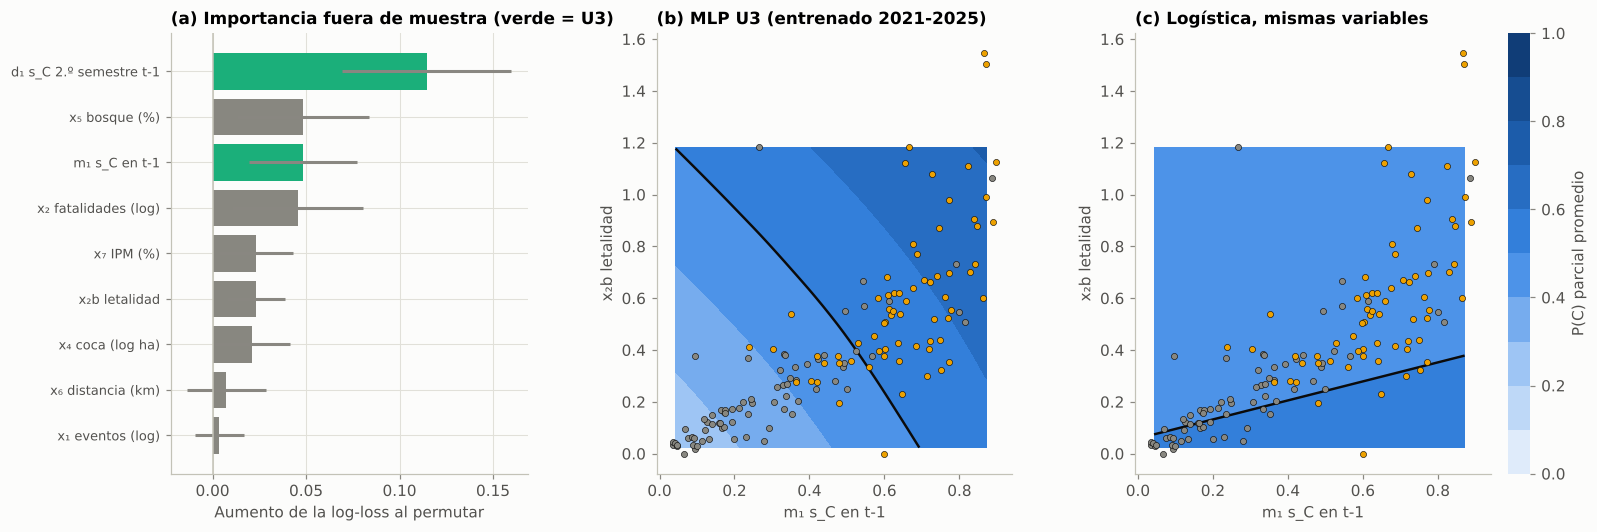

,ΔLog-loss media,Desv. est.
d₁ s_C 2.º semestre t-1,"0,1145","0,0453"
x₅ bosque (%),"0,0485","0,0353"
m₁ s_C en t-1,"0,0484","0,0287"
x₂ fatalidades (log),"0,0455","0,0351"
x₇ IPM (%),"0,0232","0,0196"
x₂b letalidad,"0,0232","0,0156"
x₄ coca (log ha),"0,0209","0,0203"
x₆ distancia (km),"0,0074","0,0211"
x₁ eventos (log),"0,0037","0,0133"


Interacción mostrada en (b)-(c): memoria m1 × x₂b letalidad


In [30]:
# =============================================================================
# 10.2 Importancia por permutación fuera de muestra (por pliegue) y dependencia parcial 2D
# =============================================================================
rng_i = np.random.default_rng(C.SEED); imp = {f: [] for f in VARS_FINAL}
spec_imp = replace(FINAL, semillas=SEM5)
for v, tr, te in E.particiones_origen_movil(datos):
    m_, e_ = P.entrenar_especificacion(datos, SEQ, spec_imp, tr)
    X_te = datos.loc[te, VARS_FINAL].copy(); y_te = datos.loc[te, "y"].values
    base_ll = E.bce(y_te, M.predecir_ensamble(m_, e_.transformar(X_te.values)))
    for f in VARS_FINAL:
        for _ in range(30):
            Xp = X_te.copy(); Xp[f] = rng_i.permutation(Xp[f].values)
            imp[f].append(E.bce(y_te, M.predecir_ensamble(m_, e_.transformar(Xp.values))) - base_ll)
IMP = pd.DataFrame({"ΔLog-loss media": {f: np.mean(v) for f, v in imp.items()}, "Desv. est.": {f: np.std(v) for f, v in imp.items()}}).sort_values("ΔLog-loss media")

def pdp_2d(modelos, esc, fx, fy, n=35):
    base_ = datos.loc[tr26, VARS_FINAL].reset_index(drop=True)
    gx = np.linspace(*datos[fx].quantile([.02, .98]), n); gy = np.linspace(*datos[fy].quantile([.02, .98]), n)
    GX, GY = np.meshgrid(gx, gy); rep_ = pd.concat([base_] * (n * n), ignore_index=True)
    rep_[fx] = np.repeat(GX.ravel(), len(base_)); rep_[fy] = np.repeat(GY.ravel(), len(base_))
    if isinstance(modelos, list) and hasattr(modelos[0], "predecir"):
        z = M.predecir_ensamble(modelos, esc.transformar(rep_[VARS_FINAL].values))
    else:
        z = modelos[0].predict_proba(esc.transformar(rep_[VARS_FINAL].values)[0])[:, 1]
    return gx, gy, z.reshape(n * n, len(base_)).mean(1).reshape(n, n)
LOG_MODS, LOG_ESC = P.entrenar_especificacion(datos, SEQ, LOG_F, tr26)
fig = plt.figure(figsize=(16, 5.2)); gs_ = fig.add_gridspec(1, 3, width_ratios=[1, 1.05, 1.05], wspace=.35)
ax = fig.add_subplot(gs_[0])
ax.barh(range(len(IMP)), IMP["ΔLog-loss media"], xerr=IMP["Desv. est."], color=[COL["u3"] if f not in V.BASE else COL["D"] for f in IMP.index], error_kw=dict(ecolor=TENUE))
ax.set_yticks(range(len(IMP)), [V.ETIQ[f] for f in IMP.index], fontsize=8.5); ax.axvline(0, color=EJE, lw=1)
ax.set_xlabel("Aumento de la log-loss al permutar"); ax.set_title("(a) Importancia fuera de muestra (verde = U3)")
fy_ = IMP.index[-2] if IMP.index[-1] == "m1_sC_t1" else IMP.index[-1]
fy_ = "x2b_letalidad" if fy_ in ("m1_sC_t1", "d1_sC_H2") else fy_
for k, (nombre, mods_, esc_) in enumerate([("MLP U3 (entrenado 2021-2025)", MODELOS_2025, ESC_2025), ("Logística, mismas variables", LOG_MODS, LOG_ESC)]):
    ax = fig.add_subplot(gs_[k + 1])
    gx, gy, Z = pdp_2d(mods_, esc_, "m1_sC_t1", fy_)
    cs = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap=G.CMAP_P, vmin=0, vmax=1); ax.contour(gx, gy, Z, levels=[.5], colors=TINTA, linewidths=1.6)
    for clase, color in [(0, COL["D"]), (1, COL["C"])]:
        s_ = datos[tr26 & (datos.y == clase).values]; ax.scatter(s_["m1_sC_t1"], s_[fy_], s=16, color=color, edgecolor=TINTA, lw=.4, zorder=3)
    ax.grid(False); ax.set_xlabel(V.ETIQ["m1_sC_t1"]); ax.set_ylabel(V.ETIQ[fy_]); ax.set_title(f"({'bc'[k]}) {nombre}")
cb = fig.colorbar(cs, ax=fig.axes[1:], fraction=.03, pad=.02); cb.set_label("P(C) parcial promedio"); cb.outline.set_visible(False)
guardar(fig, "fig13_importancia_pdp"); plt.show()
tabla(IMP.iloc[::-1].rename(index=V.ETIQ), dec=4)
print("Interacción mostrada en (b)-(c): memoria m1 ×", V.ETIQ[fy_])

**Lectura.**

* $d_1$ es, con diferencia, la variable más importante fuera de muestra (permutarla sube la log-loss en 0,115), más del
  doble que cualquier otra. Le siguen el bosque, $m_1$ y las fatalidades (≈ 0,05 cada una). La distancia y el volumen de
  eventos quedan casi en cero. Frente a la U2 cambió la jerarquía: las variables estructurales de la U1 siguen aportando
  (bosque, fatalidades, IPM y coca) y ahora modulan la inercia.
* La interacción que la red aprende es coherente con la U1. En (b), la frontera $P = 0{,}5$ entre memoria y letalidad es
  curva: con una letalidad de 0,6 fatalidades por evento basta una memoria de ≈ 0,45 para esperar C, y con letalidad nula
  hace falta ≈ 0,7. La violencia letal del año anterior adelanta el perfil convencional aunque la composición todavía no
  lo muestre, como anticipaba la U1 al decir que $x_2$ "distingue letalidad por arma". La logística (c) solo puede trazar
  una recta, y con pendiente contraria por la colinealidad entre memoria y letalidad (ρ = 0,84).
* Como $m_1$ y la letalidad están tan correlacionadas, la dependencia parcial promedia sobre combinaciones que casi no
  aparecen en los datos; la frontera solo debe leerse donde hay puntos. Y como la red y la logística empatan en
  desempeño (§9.1), esta interacción es plausible pero no está demostrada como necesaria. Con más unidades (municipios)
  será posible contrastarla.

---
# 11. Integración final: pipeline reproducible

El cuaderno **usa** el pipeline, pero no **es** el pipeline. Todo el proceso vive en el paquete `src/perfil_amenaza/`,
se ejecuta con una sola orden y produce un **artefacto único** de despliegue que no depende del cuaderno.

```
Proyecto_Unidad_3/
├── configuracion.json            ← escrita en §8.1: variables, red, ensamble, calibración, protocolo y decisiones
├── requirements.txt · README.md · pytest.ini
├── datos/acled-data-export.csv · datos/externos/ (coca, bosque y, si se agrega, UCDP)
├── src/perfil_amenaza/
│   ├── config.py      rutas, constantes, mapeo de subtipos, IPM, contigüidad departamental
│   ├── datos.py       contrato y auditoría, panel, bloques trimestrales, fuentes externas, UCDP, control 2026
│   ├── variables.py   predictoras en t-1 (BASE, MEMORIA, DINAMICA, VECINDAD, ACTORES) y secuencias
│   ├── modelo.py      redes Keras (MLP, multitarea, GRU, CNN, embedding), bucle GradientTape, calibración, artefacto
│   ├── evaluacion.py  métricas, ECE, bootstrap por departamento, McNemar, regla de retención, origen móvil, espacial,
│   │                  espacio-temporal, PSI con piso de ruido
│   ├── pipeline.py    orquestación de 8 etapas y línea de comandos
│   └── graficos.py    estilo de figuras
├── tests/test_pipeline.py        10 pruebas: contrato (y su caso negativo), fuga temporal, escalador, artefacto,
│                                 persistencia calibrada, partición espacio-temporal, regla de retención, determinismo, réplica U2
├── Proyecto_U3_Integrador.ipynb  este cuaderno
└── salidas_u3/                   métricas, predicciones, figuras, modelos/, TARJETA_MODELO.md
```

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


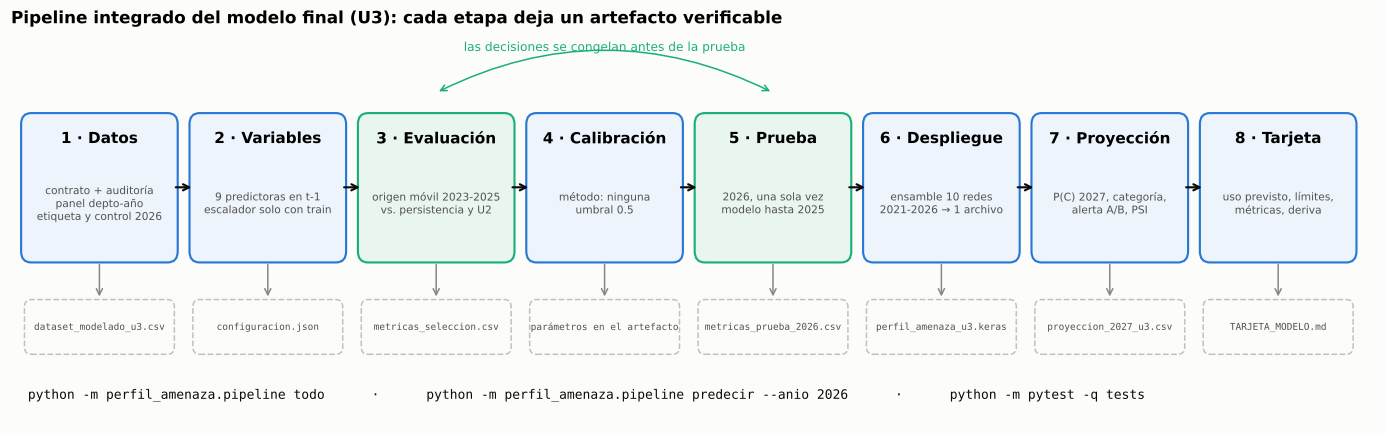

In [31]:
# =============================================================================
# 11.1 Diagrama del pipeline integrado
# =============================================================================
etapas = [("1 · Datos", "contrato + auditoría\npanel depto-año\netiqueta y control 2026", "dataset_modelado_u3.csv"),
          ("2 · Variables", f"{len(VARS_FINAL)} predictoras en t-1\nescalador solo con train", "configuracion.json"),
          ("3 · Evaluación", "origen móvil 2023-2025\nvs. persistencia y U2", "metricas_seleccion.csv"),
          ("4 · Calibración", f"método: {CALIBRACION}\numbral {UMBRAL}", "parámetros en el artefacto"),
          ("5 · Prueba", "2026, una sola vez\nmodelo hasta 2025", "metricas_prueba_2026.csv"),
          ("6 · Despliegue", f"ensamble {K_ENS} redes\n2021-2026 → 1 archivo", "perfil_amenaza_u3.keras"),
          ("7 · Proyección", "P(C) 2027, categoría,\nalerta A/B, PSI", "proyeccion_2027_u3.csv"),
          ("8 · Tarjeta", "uso previsto, límites,\nmétricas, deriva", "TARJETA_MODELO.md")]
fig, ax = plt.subplots(figsize=(16, 4.6)); ax.axis("off"); ax.grid(False)
for i, (t, d_, a) in enumerate(etapas):
    x = i * 2.0
    ax.add_patch(FancyBboxPatch((x - .05, 1.25), 1.8, 1.55, boxstyle="round,pad=0.03,rounding_size=0.12", facecolor="#eef4fc" if i not in (2, 4) else "#e8f6ef", edgecolor=COL["mlp"] if i not in (2, 4) else COL["u3"], lw=1.4))
    ax.text(x + .85, 2.55, t, ha="center", va="center", fontsize=10, fontweight="semibold")
    ax.text(x + .85, 1.85, d_, ha="center", va="center", fontsize=7, color=TINTA2)
    ax.add_patch(FancyBboxPatch((x - .02, .25), 1.74, .55, boxstyle="round,pad=0.02,rounding_size=0.08", facecolor=FONDO, edgecolor=EJE, lw=1, ls="--"))
    ax.text(x + .85, .52, a, ha="center", va="center", fontsize=6.2, color=TINTA2, family="monospace")
    ax.annotate("", xy=(x + .85, .82), xytext=(x + .85, 1.23), arrowprops=dict(arrowstyle="->", color=TENUE, lw=1))
    if i < len(etapas) - 1:
        ax.annotate("", xy=(x + 1.98, 2.03), xytext=(x + 1.72, 2.03), arrowprops=dict(arrowstyle="->", color=TINTA, lw=1.4))
ax.annotate("", xy=(4 * 2 + .85, 3.05), xytext=(2 * 2 + .85, 3.05), arrowprops=dict(arrowstyle="<->", color=COL["u3"], lw=1, connectionstyle="arc3,rad=-0.25"))
ax.text(3 * 2 + .85, 3.5, "las decisiones se congelan antes de la prueba", ha="center", fontsize=8, color=COL["u3"])
ax.text(0, -.25, "python -m perfil_amenaza.pipeline todo      ·      python -m perfil_amenaza.pipeline predecir --anio 2026      ·      python -m pytest -q tests",
        fontsize=8.5, family="monospace", color=TINTA)
ax.set_xlim(-.2, 16); ax.set_ylim(-.5, 3.7); ax.set_title("Pipeline integrado del modelo final (U3): cada etapa deja un artefacto verificable")
guardar(fig, "fig14_pipeline"); plt.show()

In [32]:
# =============================================================================
# 11.2 Pruebas automáticas y ejecución de extremo a extremo por línea de comandos
# =============================================================================
entorno = {**os.environ, "PYTHONPATH": str(RAIZ / "src"), "TF_CPP_MIN_LOG_LEVEL": "3"}
t0 = time.time()
r_test = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], cwd=RAIZ, env=entorno, capture_output=True, text=True)
print("$ python -m pytest -q tests"); print("\n".join(l for l in r_test.stdout.strip().splitlines() if "passed" in l or "failed" in l or "PASS" in l or "FAIL" in l or "::" in l))
print(f"({time.time() - t0:.0f} s)\n")
t0 = time.time()
r_cli = subprocess.run([sys.executable, "-m", "perfil_amenaza.pipeline", "todo"], cwd=RAIZ, env=entorno, capture_output=True, text=True)
print("$ python -m perfil_amenaza.pipeline todo"); print(r_cli.stdout.strip())
if r_cli.returncode != 0:
    print(r_cli.stderr[-3000:])
assert r_test.returncode == 0 and r_cli.returncode == 0

$ python -m pytest -q tests
10 passed in 7.51s
(9 s)



$ python -m perfil_amenaza.pipeline todo
[1-2] datos: 171 filas, 30 departamentos, 9 predictoras
[3-4] origen móvil 2023-2025 (n=87): AUC 0.956, log-loss 0.304 (persistencia 0.363; persistencia calibrada 0.328; base U2 0.407; base U2 ensamble 0.376); calibración: ninguna
[5] prueba 2026 (n=29): AUC 0.900, log-loss 0.380 (persistencia 0.429; persistencia calibrada 0.351; base U2 ensamble 0.470)
[6] artefacto: perfil_amenaza_u3.keras (152 KB, 10 redes)
[7] proyección 2027: {'C consolidado': 11, 'Transición': 11, 'D consolidado': 11} | PSI > 0,25: 1; PSI por encima del ruido de muestreo (p95): 1
[8] tarjeta del modelo escrita. Tiempo total: 57 s


In [33]:
# =============================================================================
# 11.3 El artefacto único: carga, estructura y consistencia con lo evaluado
# =============================================================================
ART, META = P.cargar_artefacto()
ruta_art = C.DIR_MODELOS / "perfil_amenaza_u3.keras"
print(f"{ruta_art.name}: {ruta_art.stat().st_size / 1024:.0f} KB | entrada: {tuple(ART.inputs[0].shape)} (variables crudas: {', '.join(META['variables'])}) | "
      f"salidas: {[tuple(o.shape) for o in ART.outputs]} | calibración: {META['calibracion']}")
capas_art = pd.DataFrame([(l.name, type(l).__name__, M.n_parametros(l) if hasattr(l, "trainable_variables") else 0) for l in ART.layers], columns=["Capa", "Tipo", "Parámetros entrenables"])
display(capas_art.style.hide(axis="index"))
met_cli_sel = pd.read_csv(C.DIR_SALIDA / "metricas_seleccion.csv", index_col=0)
met_cli_te = pd.read_csv(C.DIR_SALIDA / "metricas_prueba_2026.csv", index_col=0)
fin_cli = met_cli_sel.index[-1]
consist = pd.DataFrame({"Cuaderno (§9)": [T91.loc["Después: MLP U3 (ensamble)", "Log-loss"], T93.loc["Después: MLP U3 (ensamble)", "Log-loss"]],
                        "Pipeline CLI": [met_cli_sel.loc[fin_cli, "Log-loss"], met_cli_te.loc[fin_cli, "Log-loss"]]}, index=["Log-loss origen móvil 2023-2025", "Log-loss prueba 2026"])
consist["Diferencia"] = consist["Pipeline CLI"] - consist["Cuaderno (§9)"]
tabla(consist, dec=4)
PSI = pd.read_csv(C.DIR_SALIDA / "deriva_psi_2026.csv", index_col=0)
print("Deriva de las predictoras de la proyección (información 2026, los 30 departamentos del entrenamiento) frente a las filas "
      "de entrenamiento; 'p95 sin deriva' es el percentil 95 del PSI de una muestra del mismo tamaño sacada de la referencia:")
tabla(PSI.rename(index=V.ETIQ), dec=3)
display(Markdown((C.DIR_SALIDA / "TARJETA_MODELO.md").read_text(encoding="utf-8")))

perfil_amenaza_u3.keras: 152 KB | entrada: (None, 9) (variables crudas: x1_eventos, x2_fatalidades, x2b_letalidad, x4_coca, x5_bosque, x6_distancia, x7_ipm, m1_sC_t1, d1_sC_H2) | salidas: [(None, 1)] | calibración: ninguna


Capa,Tipo,Parámetros entrenables
x_crudo_t_1,InputLayer,0
estandarizacion,Normalization,0
miembro_1,Functional,177
miembro_2,Functional,177
miembro_3,Functional,177
miembro_4,Functional,177
miembro_5,Functional,177
miembro_6,Functional,177
miembro_7,Functional,177
miembro_8,Functional,177


,Cuaderno (§9),Pipeline CLI,Diferencia
Log-loss origen móvil 2023-2025,"0,3043","0,3043","0,0000"
Log-loss prueba 2026,"0,3800","0,3800","0,0000"


Deriva de las predictoras de la proyección (información 2026, los 30 departamentos del entrenamiento) frente a las filas de entrenamiento; 'p95 sin deriva' es el percentil 95 del PSI de una muestra del mismo tamaño sacada de la referencia:


,PSI,estado,p95 sin deriva,supera el ruido
variable,,,,
x₁ eventos (log),"0,076",estable,"0,371",no
x₂ fatalidades (log),"0,019",estable,"0,375",no
x₂b letalidad,"0,454",deriva,"0,373",sí
x₄ coca (log ha),"0,000",estable,"0,214",no
x₅ bosque (%),"0,011",estable,"0,370",no
x₆ distancia (km),"0,003",estable,"0,384",no
x₇ IPM (%),"0,005",estable,"0,387",no
m₁ s_C en t-1,"0,226",vigilar,"0,379",no
d₁ s_C 2.º semestre t-1,"0,174",vigilar,"0,380",no


# Tarjeta del modelo: perfil de amenaza tecnológica (U3)

**Uso previsto.** Priorizar, con un año de anticipación, el énfasis tecnológico (ISR, C-UAS, detección de AEI)
por departamento. Insumo analítico; no sustituye la inteligencia de campo.

**No usar para:** decisiones sobre personas o municipios individuales; departamentos con menos de 10 eventos
al año (Amazonía y Orinoquía con pocos registros) sin revisión experta.

**Datos.** ACLED semanal agregado a departamento (2020-2026), SIMCI-ODC, Global Forest Watch, DANE. 171 filas.
**Modelo.** mlp (16,) relu L2=0.001 do=0 lr=0.001 pasos=560 obj=duro; ensamble de 10 semillas; sin recalibración (la calibración Platt no mejoró la log-loss fuera de muestra; ver §6.10 del cuaderno).
**Variables (9).** x1_eventos, x2_fatalidades, x2b_letalidad, x4_coca, x5_bosque, x6_distancia, x7_ipm, m1_sC_t1, d1_sC_H2

| Métrica | Origen móvil 2023-2025 | Prueba 2026 |
|---|---|---|
| ROC-AUC | 0.956 | 0.900 |
| Log-loss | 0.304 | 0.380 |
| Brier | 0.095 | 0.121 |
| MCC | 0.691 | 0.672 |
| ECE | 0.124 | 0.074 |
| Exactitud | 0.839 | 0.828 |

| Rivales | Origen móvil 2023-2025 | Prueba 2026 |
|---|---|---|
| Persistencia · ROC-AUC | 0.973 | 0.948 |
| Persistencia · Log-loss | 0.363 | 0.429 |
| Persistencia · Brier | 0.106 | 0.131 |
| Persistencia calibrada · ROC-AUC | 0.966 | 0.948 |
| Persistencia calibrada · Log-loss | 0.328 | 0.351 |
| Persistencia calibrada · Brier | 0.099 | 0.105 |

La persistencia calibrada (logística sobre logit(m1) entrenada con años anteriores) se agregó como rival tras la
revisión; no cambió el modelo adoptado. Frente a ella, la ventaja del modelo no está demostrada a escala departamental.

**Limitaciones.** 30 unidades espaciales; etiqueta 2026 con 33 semanas; x3 (actores, UCDP) evaluada y no retenida;
x6 es un proxy departamental; la prevalencia de C cambia entre años (32 % a 62 %); con la información parcial de
2026, d1 resume las semanas 8 a 33 y no el segundo semestre.

**Deriva.** PSI de la información 2026 frente al entrenamiento (mismos 30 departamentos): variables con PSI > 0,25: x2b_letalidad; por encima del percentil 95 del ruido de muestreo: x2b_letalidad.
**Mantenimiento.** Reentrenar cada año con la etiqueta cerrada, revisar el PSI con su piso de ruido y reevaluar la
calibración con encadenamiento hacia adelante (hoy no se calibra porque no mejora sin mirar el futuro).

**Lectura de la integración.**

* Las 10 pruebas pasan: contrato de datos y su caso negativo (un export sin una columna se rechaza), ausencia de fuga
  temporal (multiplicar por 5 los eventos de 2024 no cambia ninguna predictora de las filas de 2024, y sí las de 2025),
  escalador y capa `Normalization` del artefacto ajustados solo con el entrenamiento, persistencia calibrada y partición
  espacio-temporal sin acceso al año predicho, regla de retención, determinismo y reproducción exacta del dataset de la U2.
* La orden `pipeline todo` reproduce de extremo a extremo lo que el cuaderno evaluó, en 59 segundos. Las log-loss
  de selección (0,304) y de prueba (0,380) coinciden con §9 al cuarto decimal.
* El artefacto es único y autocontenido: un archivo `.keras` de 152 KB con la estandarización (capa `Normalization` con
  las medias y desviaciones de entrenamiento), las 10 redes de 177 parámetros, el promedio y la calibración. Recibe las 9
  variables en su escala original y devuelve P(C). La proyección de §12 se calcula con este archivo, no con objetos en
  memoria, y `pipeline predecir` funciona sin el cuaderno.
* Deriva (PSI). Comparamos la información de 2026 de los 30 departamentos del entrenamiento con las filas de
  entrenamiento. Con 30 filas el PSI tiene un piso de ruido alto: sin deriva, su percentil 95 está entre 0,21 y
  0,39 según la variable. Solo la letalidad lo supera (PSI 0,45 frente a un percentil 95 de 0,37): la distribución de fatalidades por evento de 2026 difiere de la del entrenamiento. $m_1$ (0,23) y $d_1$ (0,17) caen en la franja de vigilancia de los umbrales usuales (0,1–0,25), pero dentro del ruido de muestreo. La proyección 2027 debe leerse con esa cautela, sobre todo donde la letalidad pesa en la frontera (§10.2). La tarjeta del modelo fija el mantenimiento: reentrenar con cada año cerrado y
  revisar el PSI con su piso de ruido antes de usar la proyección.

---
# 12. Del modelo a la decisión: priorización territorial 2027

La proyección sale del **artefacto único** (no de objetos en memoria): ensamble de 10 redes reentrenado con todas
las etiquetas 2021–2026 y aplicado a la información de 2026 (33 semanas, anualizada). Se compara con la proyección
de la U2 para ver qué cambió al incorporar la memoria y la dinámica reciente.

> Es un **insumo analítico ilustrativo**, no una recomendación operativa: resume el patrón aprendido de datos públicos
> agregados y debe contrastarse con inteligencia de campo.

In [34]:
# =============================================================================
# 12.1 Proyección 2027 con el artefacto, incertidumbre entre redes y cambio frente a la U2
# =============================================================================
proy = pd.read_csv(C.DIR_SALIDA / "proyeccion_2027_u3.csv")
filas27, _ = V.filas_proyeccion(acled, pext, 2026, actores=ACTORES)
x27 = filas27.set_index("depto").loc[proy.depto, META["variables"]].values.astype("float32")
norm = ART.get_layer("estandarizacion")(x27)
miembros = [l for l in ART.layers if l.name.startswith("miembro_")]
P_m = np.array([np.asarray((lambda o: o[0] if isinstance(o, (list, tuple)) else o)(m(norm))).ravel() for m in miembros])
proy["DE entre redes"] = P_m.std(0)
u2p = pd.read_csv(RAIZ / "referencias_u2" / "proyeccion_2027.csv")[["depto", "P(C) 2027", "Categoría 2027"]].rename(columns={"P(C) 2027": "P(C) U2", "Categoría 2027": "Categoría U2"})
proy = proy.merge(u2p, on="depto", how="left")
# Cercanía a la inercia (no es acierto): ¿la proyección 2027 contradice el perfil observado en 2026?
proy["¿Coincide con el perfil 2026?"] = np.where(proy["perfil_info"].isna(), "–", np.where((proy["P(C) 2027"] >= .5) == (proy["perfil_info"] == "C"), "sí", "revisar"))
cols_p = ["departamento", "perfil_info", "s_C_info", "P(C) 2027", "DE entre redes", "Categoría 2027", "Categoría U2", "¿Coincide con el perfil 2026?", "s_AB observada 2025-26", "Énfasis sugerido", "confiable_info"]
display(proy[cols_p].rename(columns={"perfil_info": "Perfil 2026", "s_C_info": "s_C 2026", "confiable_info": "Datos suficientes"})
        .style.format({"s_C 2026": "{:.2f}", "P(C) 2027": "{:.2f}", "DE entre redes": "{:.3f}", "s_AB observada 2025-26": "{:.1%}"})
        .background_gradient(subset=["P(C) 2027"], cmap=G.CMAP_P, vmin=0, vmax=1).hide(axis="index"))
CAT = proy["Categoría 2027"].value_counts()
print("Categorías 2027 (U3):", CAT.to_dict(), "| U2:", proy["Categoría U2"].value_counts().to_dict())
display(pd.crosstab(proy["Categoría U2"], proy["Categoría 2027"], rownames=["U2"], colnames=["U3"]))
REVISAR = proy.loc[proy["¿Coincide con el perfil 2026?"] == "revisar", "departamento"].tolist()
ALERTA = proy.loc[proy["alerta_AB"].fillna(False), "departamento"].tolist()
print(f"Contradicen el perfil observado en 2026: {len(REVISAR)} ({', '.join(REVISAR)}) | alerta A/B: {', '.join(ALERTA)}")
POCOS = proy.loc[~proy["confiable_info"].astype(bool), ["departamento", "Categoría 2027"]]
print("Departamentos con menos de 10 eventos en 2026 (requieren revisión experta):", POCOS.set_index("departamento")["Categoría 2027"].to_dict())
ab_, nac_ = P.alerta_ab(pext)
print(f"Alerta A/B: proporción A+B 2025-2026 >= 2 × nacional ({nac_:.1%} → umbral {2 * nac_:.1%}) y >= 5 eventos A+B")

# Con la información parcial de 2026, las "últimas 26 semanas" son las semanas 8-33, no el segundo semestre.
# ¿Cuánto cambia d1 por medirlo en esa ventana? Se compara en 2020-2025, donde ambos están disponibles.
b_full = D.bloques_trimestrales(acled); b_part = D.bloques_trimestrales(acled[acled.semana_anio <= N_SEM_2026])
def d1_de(b):
    h = b[b.bloque <= 1].groupby(["depto", "anio"])[["C", "eventos"]].sum()
    return pd.Series(V.contraer(h.C, h.eventos), index=h.index)
d1c = pd.concat([d1_de(b_full).rename("2.º semestre"), d1_de(b_part).rename(f"semanas {N_SEM_2026 - 25}-{N_SEM_2026}")], axis=1).dropna()
d1c = d1c[d1c.index.get_level_values("anio") <= 2025]
D1_CORR, D1_MAE = d1c.corr().iloc[0, 1], (d1c.iloc[:, 0] - d1c.iloc[:, 1]).abs().mean()
print(f"d1 con la ventana de 2026 frente al 2.º semestre (2020-2025, {len(d1c)} celdas): correlación {D1_CORR:.2f}, error absoluto medio {D1_MAE:.3f}")

departamento,Perfil 2026,s_C 2026,P(C) 2027,DE entre redes,Categoría 2027,Categoría U2,¿Coincide con el perfil 2026?,s_AB observada 2025-26,Énfasis sugerido,Datos suficientes
Guaviare,C,0.76,0.99,0.007,C consolidado,C consolidado,sí,14.4%,"ISR, detección temprana y movilidad protegida + evaluar C-UAS / detección de AEI",True
Nariño,C,0.70,0.93,0.022,C consolidado,C consolidado,sí,6.8%,"ISR, detección temprana y movilidad protegida",True
Cauca,C,0.70,0.92,0.021,C consolidado,C consolidado,sí,13.4%,"ISR, detección temprana y movilidad protegida + evaluar C-UAS / detección de AEI",True
Caquetá,C,0.81,0.92,0.034,C consolidado,C consolidado,sí,9.8%,"ISR, detección temprana y movilidad protegida",True
Putumayo,C,0.81,0.89,0.080,C consolidado,Transición,sí,3.7%,"ISR, detección temprana y movilidad protegida",True
Antioquia,C,0.65,0.88,0.023,C consolidado,C consolidado,sí,6.8%,"ISR, detección temprana y movilidad protegida",True
Amazonas,C,0.78,0.88,0.041,C consolidado,C consolidado,sí,0.0%,"ISR, detección temprana y movilidad protegida",False
Norte de Santander,C,0.60,0.86,0.026,C consolidado,C consolidado,sí,10.2%,"ISR, detección temprana y movilidad protegida",True
Vaupés,C,0.50,0.84,0.131,C consolidado,C consolidado,sí,0.0%,"ISR, detección temprana y movilidad protegida",False
Vichada,C,0.73,0.79,0.087,C consolidado,Transición,sí,5.9%,"ISR, detección temprana y movilidad protegida",True


Categorías 2027 (U3): {'C consolidado': 11, 'Transición': 11, 'D consolidado': 11} | U2: {'Transición': 13, 'C consolidado': 10, 'D consolidado': 10}


U3,C consolidado,D consolidado,Transición
U2,,,
C consolidado,8,0,2
D consolidado,0,9,1
Transición,3,2,8


Contradicen el perfil observado en 2026: 3 (Chocó, Valle del Cauca, Meta) | alerta A/B: Guaviare, Cauca
Departamentos con menos de 10 eventos en 2026 (requieren revisión experta): {'Amazonas': 'C consolidado', 'Vaupés': 'C consolidado', 'San Andrés': 'Transición', 'Guainía': 'Transición'}
Alerta A/B: proporción A+B 2025-2026 >= 2 × nacional (6.4% → umbral 12.7%) y >= 5 eventos A+B
d1 con la ventana de 2026 frente al 2.º semestre (2020-2025, 198 celdas): correlación 0.88, error absoluto medio 0.084


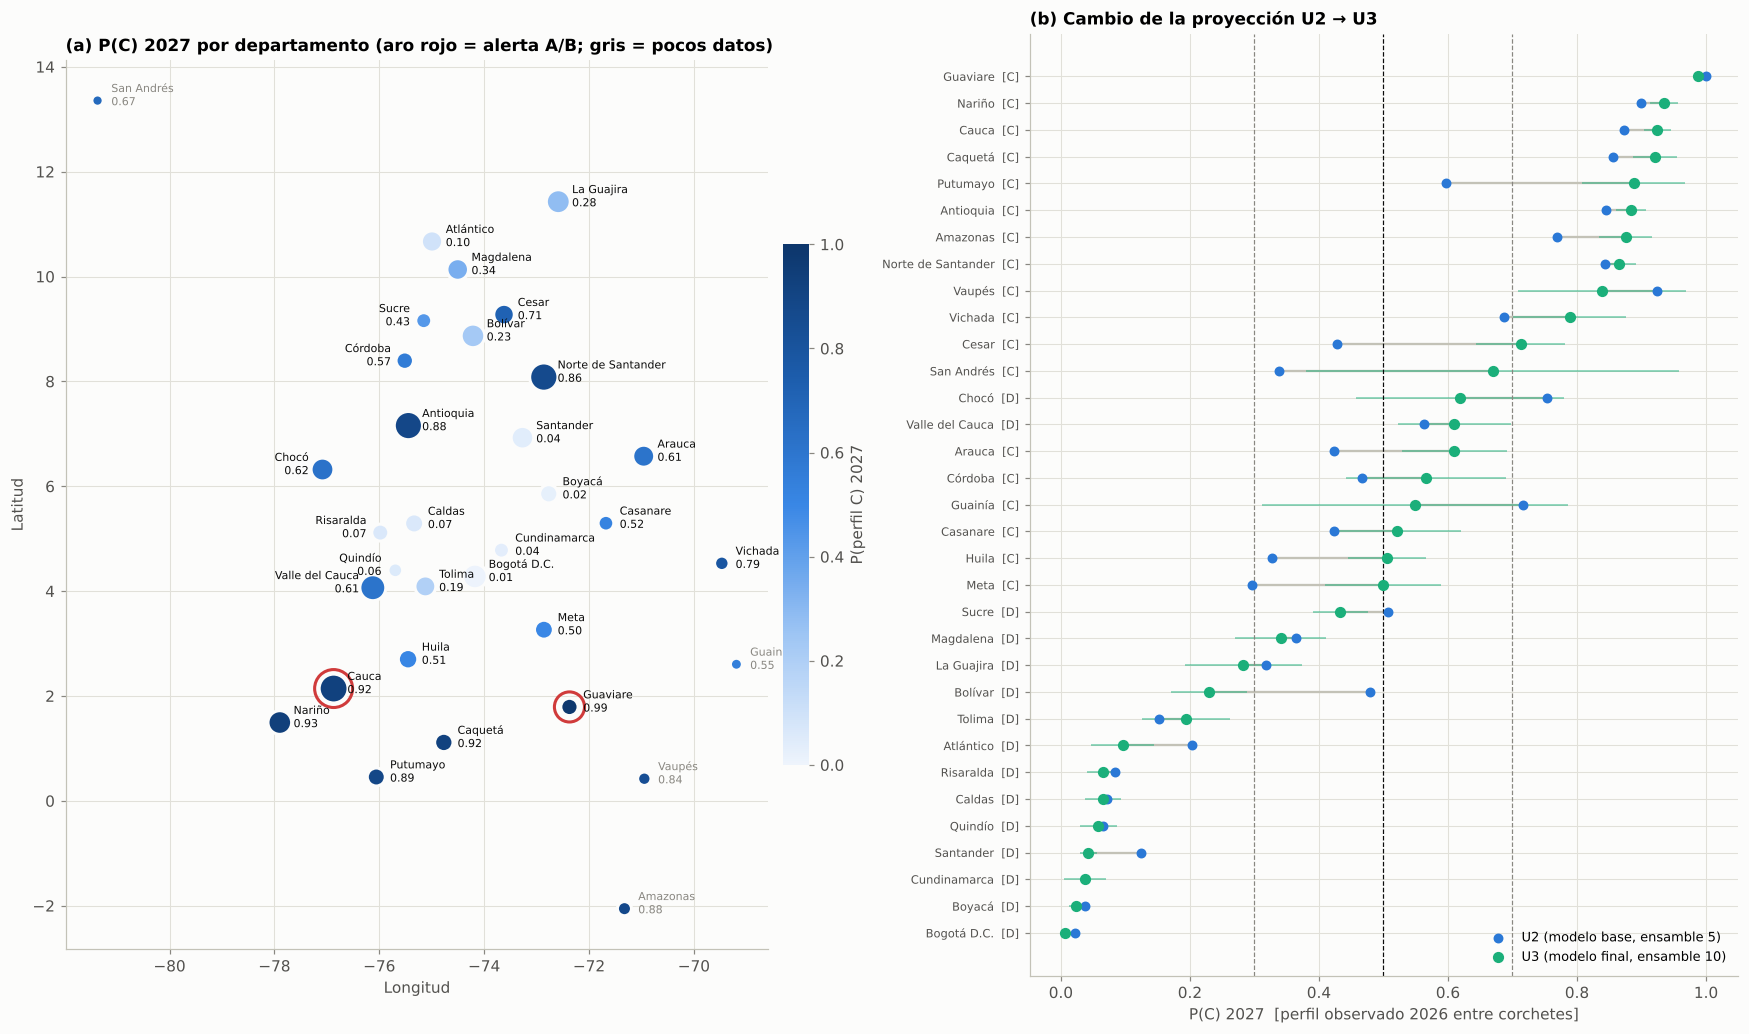

In [35]:
# =============================================================================
# 12.2 Mapa esquemático de la proyección 2027 (centroides) y transición U2 -> U3
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 9.5), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axes[0]
tam = 40 + 12 * np.sqrt((proy["eventos_info"] / proy["semanas"] * 52).clip(lower=1))
sc = ax.scatter(proy.lon, proy.lat, s=tam, c=proy["P(C) 2027"], cmap=G.CMAP_P, vmin=0, vmax=1, edgecolor=FONDO, lw=2, zorder=3)
al = proy[proy["alerta_AB"].fillna(False)]
ax.scatter(al.lon, al.lat, s=tam[al.index] + 260, facecolor="none", edgecolor="#d03b3b", lw=2, zorder=2)
izq = {"valle del cauca", "risaralda", "quindio", "sucre", "cordoba", "choco"}
for _, r in proy.iterrows():
    i_ = r.depto in izq
    ax.annotate(f"{r.departamento}\n{r['P(C) 2027']:.2f}", (r.lon, r.lat), xytext=(-9 if i_ else 9, -3), textcoords="offset points",
                ha="right" if i_ else "left", fontsize=7.2, color=TINTA if r.confiable_info else TENUE)
cb = fig.colorbar(sc, ax=ax, fraction=.035, pad=.02); cb.set_label("P(perfil C) 2027"); cb.outline.set_visible(False)
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect("equal")
ax.set_title("(a) P(C) 2027 por departamento (aro rojo = alerta A/B; gris = pocos datos)")
ax = axes[1]
orden = proy.sort_values("P(C) 2027")
y_ = np.arange(len(orden))
ax.hlines(y_, orden["P(C) U2"], orden["P(C) 2027"], color=EJE, lw=1.5)
ax.scatter(orden["P(C) U2"], y_, color=COL["mlp"], s=30, label="U2 (modelo base, ensamble 5)", zorder=3)
ax.scatter(orden["P(C) 2027"], y_, color=COL["u3"], s=40, label="U3 (modelo final, ensamble 10)", zorder=3)
ax.errorbar(orden["P(C) 2027"], y_, xerr=orden["DE entre redes"], fmt="none", ecolor=COL["u3"], lw=1, alpha=.6)
ax.set_yticks(y_, [f"{d}  [{p if isinstance(p, str) else '–'}]" for d, p in zip(orden.departamento, orden.perfil_info)], fontsize=7.5)
for u in (.3, .5, .7):
    ax.axvline(u, color=TENUE if u != .5 else TINTA, lw=.8, ls="--")
ax.set_xlabel("P(C) 2027  [perfil observado 2026 entre corchetes]"); ax.set_title("(b) Cambio de la proyección U2 → U3"); ax.legend(fontsize=8.5, loc="lower right")
fig.tight_layout(); guardar(fig, "fig15_proyeccion_2027"); plt.show()

**Lectura para la decisión.**

* 11 departamentos C consolidados (P ≥ 0,7): Guaviare, Nariño, Cauca, Caquetá, Putumayo, Antioquia, Norte de
  Santander, Vichada y Cesar, más Amazonas y Vaupés, que tienen menos de 10 eventos en 2026 y requieren revisión experta
  (en gris en el mapa). Prioridad para ISR, detección temprana y movilidad protegida. Guaviare (14,4 % de eventos A+B) y
  Cauca (13,4 %) cumplen la alerta A/B (proporción A+B de 2025–2026 de al menos el doble de la nacional, 6,4 %, y 5 o más
  eventos A+B): allí conviene sumar C-UAS y detección de AEI.
* 11 en transición (0,3–0,7): San Andrés y Guainía (pocos datos), Chocó, Valle del Cauca, Arauca, Córdoba, Casanare,
  Huila, Meta, Sucre y Magdalena. Portafolio flexible y monitoreo trimestral. Meta (0,50), Huila (0,51) y Casanare
  (0,52) están justo en el umbral.
* 11 D consolidados: el eje andino y urbano, más La Guajira, Bolívar y Atlántico. Orden público y capacidades mixtas.
* Frente a la U2, 25 de 33 departamentos conservan su categoría. Putumayo, Vichada y Cesar pasan de transición a C
  consolidado, porque la memoria pesa ahora más que la estructura. Chocó y Guainía bajan de C a transición, y Bolívar y
  La Guajira de transición a D. La proyección contradice el perfil observado en 2026 en 3 departamentos (Chocó, Valle del
  Cauca y Meta; en la U2 eran 10). Es una medida de cercanía a la inercia y no de acierto, y señala los casos que conviene
  revisar con inteligencia de campo. Chocó y Valle son desescaladas recientes con $s^C$ de 2026 en 0,45–0,50.
* Incertidumbre. La desviación entre las 10 redes es menor de 0,04 en los extremos (C y D consolidados) y crece en la
  franja de transición: Chocó 0,16, Córdoba 0,12 y los de pocos registros, San Andrés 0,29 y Guainía 0,24.
* Ventana de $d_1$. La información de 2026 cubre 33 semanas, así que $d_1$ resume las semanas 8 a 33 y no el segundo
  semestre. En 2020–2025, $d_1$ medido en esa ventana tiene correlación 0,88 con el semestral y difiere en 0,084 en
  promedio. La proyección debe repetirse al cerrar 2026, sobre todo para los departamentos en el umbral.

---
# 13. Conclusiones técnicas y recomendaciones

1. Coherencia problema–datos–modelo–decisión. El modelo final responde la pregunta de la U1 a escala departamental
   (el export gratuito de ACLED no llega a municipio), con la misma etiqueta, el mismo diseño $t-1 \rightarrow t$ y las
   mismas variables estructurales. Agrega dos variables que llevan la "intensidad histórica" de la U1 a la composición
   reciente. Cada cambio frente a la U2 se justifica en un hallazgo del diagnóstico y se valida con el protocolo de §3.1.
2. Dónde estuvo la mejora. De diez frentes evaluados se retuvieron tres ($m_1$, $d_1$ y el ensamble). Las demás
   intervenciones no cumplieron la regla de retención, salvo la vecindad, que mejoró solo en el eje que no era el de su
   hipótesis, y el embedding, que la cumplió y se descartó por la regla 8. La rejilla de hiperparámetros no ofreció una
   alternativa que se sostuviera al año siguiente.
3. Frente al modelo de la U2 la mejora es clara: con ensamble en los dos lados, la log-loss baja de 0,376 a 0,304 en
   selección y de 0,470 a 0,380 en la prueba 2026.
4. Frente a la inercia, la ventaja es de calibración y no está demostrada a escala departamental. El modelo supera a la
   persistencia cruda en log-loss porque ella usa una proporción como probabilidad, pero ordena y clasifica peor que
   ella. Frente a una persistencia calibrada gana por 0,024 en selección, pierde por 0,029 en 2026 y en
   territorios nuevos queda en 0,361 frente a 0,332.
5. La limitación principal sigue siendo anticipar cambios de régimen. El modelo acierta 2 de 13 transiciones (el de la
   U2, 3). Las escaladas de 2025 y las desescaladas de 2026 responden a coyunturas que las variables de ACLED agregado no
   contienen.
6. Los efectos fijos territoriales importan. El embedding de departamento, descartado por la regla 8, fue mejor en la
   prueba 2026. Las variables actuales no explican todo lo que distingue a un departamento de otro (R2 y R7).
7. La red no demostró ser mejor que una logística en el eje temporal. En departamentos nuevos obtiene menos log-loss
   (0,361 frente a 0,416, con un IC95 de la diferencia que incluye el cero; §9.2), que es la razón, débil, para mantenerla. La logística y la persistencia calibrada quedan como rivales permanentes.
8. Para la pregunta de inversión, la evidencia sostiene para 2027 priorizar ISR, detección temprana y movilidad
   protegida en los 9 departamentos C consolidados con datos suficientes, sumar C-UAS y detección de AEI en Guaviare y
   Cauca, mantener portafolio flexible en los 11 de transición y revisar con inteligencia de campo Chocó, Valle del Cauca
   y Meta. Como una inercia calibrada da casi la misma probabilidad a esta escala, el modelo aporta hoy un procedimiento
   reproducible que integra composición reciente, variables estructurales e incertidumbre entre redes; su ventaja
   predictiva queda por probar a escala municipal (R1).

**Recomendaciones (en orden de impacto esperado):**

| # | Recomendación | Evidencia | Acción concreta |
|---|---|---|---|
| R1 | Migrar a municipio con el registro de ACLED por evento (M3) | Con 30 departamentos el modelo está limitado por varianza (U2) y en territorios nuevos empata con la inercia (§9.2) | Solicitar el acceso académico; reentrenar con el mismo pipeline (cambian `datos.py` y las constantes departamentales de `config.py`) |
| R2 | Redefinir $x_3$ a escala municipal | El conteo anual de actores por departamento empeoró el modelo (§6.3), pero los territorios sin historia necesitan una variable de actores | Con el registro por evento, medir actores por municipio y su cambio reciente (entradas y salidas de grupos) en lugar del conteo anual |
| R3 | Señales adelantadas de transición | 11 de 19 errores son transiciones; escaladas 2025 y desescaladas 2026 | Variables mensuales del último trimestre, ceses al fuego y negociaciones; evaluar con la misma regla |
| R4 | Reentrenar cada año con la etiqueta cerrada y vigilar el PSI con su piso de ruido | Prevalencia de C entre 41 % y 62 % en los años validados; en 2026 solo la letalidad supera el piso de ruido del PSI (§11.3) | Ejecutar `pipeline todo` al cierre de cada año; no usar umbrales fijos; decidir con las bandas |
| R5 | Re-evaluar los logaritmos y `MIN_EVENTOS` a escala municipal | Controles de §7 (Δ −0,012 sin logaritmos; 5 ≈ 10 eventos) | Repetir la batería de controles con el nuevo dataset |
| R6 | Mantener la persistencia calibrada y la logística como rivales permanentes | Empatan con el modelo dentro del ruido (§9) | Reportarlas en cada ejecución del pipeline y en la tarjeta del modelo |
| R7 | Reevaluar el embedding de departamento cuando cierre 2026 | Cumplió la regla 5 en 2023–2025 y fue mejor en la prueba 2026 (log-loss 0,314 frente a 0,380) | Incluirlo como candidato en la próxima selección (origen móvil 2024–2026, con prueba en 2027) y, a escala municipal, sustituirlo por $x_3$ y distancia municipal |

---
# 14. Trabajo en equipo, bitácora y uso de IA

## 14.1 Roles técnicos en la Unidad 3

La guía pide distribuir cuatro roles: modelado, evaluación, documentación y presentación. Mantenemos la división
de las Unidades 1 y 2 (Juan Diego en la implementación técnica, Laura en la interpretación estratégica y la
comunicación) y la llevamos a esos cuatro roles.

| Rol (guía U3) | Responsable | Entregables en este repositorio | Respaldo |
|---|---|---|---|
| **Modelado** | Juan Diego | `src/perfil_amenaza/` (datos, variables, modelo, pipeline); intervenciones I1–I9 (§6); rejilla y validación anidada (§6.8) | Laura |
| **Evaluación** | Conjunta: cálculo Juan Diego, interpretación Laura | Protocolo y regla de retención (§3), controles (§7), antes vs. después (§9), análisis de errores (§10) | – |
| **Documentación** | Laura | Lecturas del cuaderno, tarjeta del modelo, informe PDF (12 páginas), README | Juan Diego |
| **Presentación** | Laura (guion y narrativa) · Juan Diego (demostración del pipeline) | Video MP4 de 8–10 min y sustentación sincrónica | Conjunta |

Cómo trabajamos en esta unidad. Juan Diego propuso e implementó las intervenciones a partir del diagnóstico de la U2 y
escribió el paquete; Laura revisó cada resultado contra las salidas del cuaderno, redactó las lecturas y propuso la
lectura para la decisión (bandas, alerta A/B y énfasis tecnológico). Las decisiones de protocolo las tomamos juntos
antes de ejecutar: seleccionar solo con origen móvil 2023–2025 y usar 2026 una vez (D11), medir contra la persistencia
con log-loss (D12), la regla de retención (D13) y mantener la capacidad de la U2 si la rejilla no ofrecía una
alternativa estable (D16). Dos decisiones salieron de discutir resultados que no esperábamos: no adoptar el embedding de
departamento (regla 8, §6.7) y no cambiar los logaritmos aunque el control los favoreciera (regla 7, §7). Después de la
revisión del informe agregamos la persistencia calibrada como rival y la validación espacio-temporal, sin cambiar el
modelo. Ambos podemos reproducir el proceso con las tres órdenes de §11 y defender cada decisión con la evidencia citada.

## 14.2 Bitácora de decisiones técnicas (continúa la D1–D10 de la U2)

| # | Decisión | Alternativas consideradas | Justificación | Evidencia |
|---|---|---|---|---|
| D11 | Seleccionar solo con origen móvil 2023–2025; 2026 se evalúa una vez | Seguir usando 2026 en la selección | 2026 ya se miró en la U2; reusarlo para elegir sesgaría la prueba | §3.1 |
| D12 | La persistencia es el rival y la log-loss la métrica de decisión | Exactitud; comparar solo contra el MLP base | La persistencia es lo que haría un planificador sin modelo; la log-loss es una regla de puntuación propia (Gneiting y Raftery, 2007) | §3.1, §4 |
| D13 | Regla de retención: mejora > 1 EE pareado entre semillas | Aceptar cualquier mejora media | Con 87 predicciones, diferencias menores que el ruido entre semillas no se sostienen | §3.1, §6 |
| D14 | Proporciones con contracción bayesiana (α = 4) | Proporción cruda | Estabiliza celdas y semestres con pocos eventos; se verifica en §7 | §2.4, §7 |
| D15 | Variables finales según la cascada I1–I4 | Usar todas las candidatas | Solo entran las que superan la regla; las demás se documentan como descartadas | §6.1–§6.4 |
| D16 | Mantener capacidad, L2 y presupuesto de la U2 | Adoptar el mínimo de la rejilla | La validación anidada muestra que la selección no transfiere al año siguiente | §6.8 |
| D17 | Ensamble de 10 redes | 1 o 20 redes | La curva de K se estabiliza; reduce la dispersión entre semillas | §6.9 |
| D18 | Calibración solo si mejora sin mirar el futuro | Platt ajustado con 2023–2025 completo | El sesgo de calibración cambia de signo y tamaño entre años (prevalencia) | §6.10 |
| D19 | Pipeline como paquete con artefacto único `.keras` (estandarización + ensamble + calibración) | Cuaderno como único entregable | Reproducibilidad, pruebas automáticas y predicción sin el cuaderno | §11 |
| D20 | $x_3$ con UCDP GED (reducido a Colombia con `herramientas/preparar_ucdp.py`); no se retiene | Esperar el registro por evento de ACLED (licencia) | Fuente abierta verificada; se evaluó con la misma regla y empeoró la log-loss | §6.3 |

## 14.3 Declaración de uso de inteligencia artificial

Usamos Claude (Anthropic) como apoyo en la programación del pipeline y del cuaderno y en la revisión de la redacción y
la organización del informe. La propuesta del proyecto, la búsqueda y selección de datos, el análisis, las decisiones
metodológicas y las conclusiones son del equipo, que ejecutó, revisó y verificó todos los resultados.

---
# 15. Matriz rúbrica → evidencia

| Criterio de la rúbrica (Excelente = 1,0) | Qué pide el nivel Excelente | Evidencia en este cuaderno |
|---|---|---|
| **Coherencia metodológica integral** (problema–datos–modelo–evaluación) | Integra problema, datos, modelo y conclusiones con trazabilidad clara y evidencia cuantitativa | Trazabilidad U1 → U2 → U3 de variables y decisiones (§1.1–§1.3); reproducción de la U2 al dígito (§2.4, §4); cada intervención nace de un diagnóstico U2 con hipótesis refutable (§5); la regla 8, agregada durante las intervenciones, se declara (§3.1); la salida vuelve a la pregunta de inversión (§12, §13.8); conclusiones con cifras (§13) |
| **Preparación y representación de datos** | Evalúa y justifica transformaciones, partición y controles experimentales, con impacto en el entrenamiento | Contrato y auditoría (§2.1); control de la etiqueta parcial de 2026, 94,9 % (§2.3); variables nuevas con justificación y contracción bayesiana (§2.4–§2.5); protocolo temporal sin fuga (§3); 9 controles con efecto medido y curvas de entrenamiento: sin estandarización no converge, fuga del escalador = +0,002 artificial, etiquetas barajadas AUC 0,32 (§7) |
| **Calidad técnica del modelo y optimización** | Diseña y optimiza la arquitectura con configuración documentada, curvas de desempeño e intervención estratégica basada en diagnóstico | 10 frentes de intervención con regla de retención previa (§3.1, §6); comparativos GRU, CNN, embedding y profundo (§6.7); rejilla de 48 configuraciones con validación anidada (§6.8); curva del ensamble (§6.9); configuración en `configuracion.json` (§8.1); curvas de aprendizaje antes vs. después (§8.3); escalera de mejora (§6.11) |
| **Evaluación del desempeño e interpretación** | Evalúa métricas pertinentes interpretando resultados, errores y comparación experimental con rigor técnico | Log-loss, Brier, ECE, AUC, MCC, exactitud y transiciones (§3.1); persistencia cruda y calibrada como rivales y ensamble del modelo base como antes justo (§9.1); IC bootstrap por departamento y McNemar (§9.1); validación espacial y espacio-temporal (§9.2); prueba 2026 única (§9.3); matrices de confusión y ROC (§9.4); análisis de errores y evaluación de las bandas de decisión (§10.1); importancia e interacción (§10.2); límites declarados (§9, §10.1, §13) |
| **Entregables finales y comunicación ejecutiva** | Integra informe y sustentación con estructura profesional, coherencia técnica y articulación del equipo | Resumen ejecutivo; pipeline con 10 pruebas, línea de comandos y artefacto único (§11); tarjeta del modelo; decisión territorial 2027 (§12); roles, bitácora D11–D20 y declaración de IA (§14); figuras en tamaño de impresión para el informe (Anexo A) |

**Contenidos del Producto 1 (informe de 12 páginas) → secciones de origen:** planteamiento (§1), dataset y
preprocesamiento (§2, §7), arquitectura (§6.7, §8), entrenamiento y evaluación (§3, §8.3, §9), optimización y
comparación (§5, §6, §9), análisis crítico (§9, §10), integración en el pipeline (§11), conclusiones y recomendaciones
(§13). **Producto 2 (video de 8–10 min):** síntesis del problema (§1), decisiones técnicas (§6.11, D11–D20), resultados
(§9, figuras R1–R2), conclusiones estratégicas (§12, §13).

---
# 16. Artefactos y figuras para el informe

In [36]:
# =============================================================================
# 16.1 Artefactos producidos (cuaderno + pipeline)
# =============================================================================
pd.DataFrame({"tiempo total del cuaderno (min)": [round((time.time() - T0_CUADERNO) / 60, 1)]}).pipe(display)
dec_tab = pd.DataFrame(DECISIONES); dec_tab.to_csv(C.DIR_SALIDA / "decisiones_intervenciones.csv", index=False)
ESC.to_csv(C.DIR_SALIDA / "escalera_mejora.csv"); CTRL.to_csv(C.DIR_SALIDA / "controles_datos.csv"); REJ.to_csv(C.DIR_SALIDA / "rejilla_I6.csv", index=False)
T91.to_csv(C.DIR_SALIDA / "antes_despues_origen_movil.csv"); T93.to_csv(C.DIR_SALIDA / "antes_despues_prueba_2026.csv"); esp_tab.to_csv(C.DIR_SALIDA / "validacion_espacial.csv")
ET_TAB.to_csv(C.DIR_SALIDA / "validacion_espacio_temporal.csv"); BANDAS.to_csv(C.DIR_SALIDA / "bandas_decision.csv")
pd.concat({"origen móvil 2023-2025": PAR_91, "prueba 2026": PAR_26, "espacio-temporal": PAR_ET}).to_csv(C.DIR_SALIDA / "comparaciones_pareadas.csv")
archivos = sorted(p for p in C.DIR_SALIDA.rglob("*") if p.is_file())
display(pd.DataFrame({"Archivo": [str(p.relative_to(C.DIR_SALIDA)) for p in archivos], "KB": [round(p.stat().st_size / 1024, 1) for p in archivos]}).style.hide(axis="index"))

,tiempo total del cuaderno (min)
0,20.4


Archivo,KB
TARJETA_MODELO.md,2.400000
antes_despues_origen_movil.csv,1.700000
antes_despues_prueba_2026.csv,2.000000
bandas_decision.csv,0.400000
comparaciones_pareadas.csv,2.800000
controles_datos.csv,0.900000
dataset_modelado_u3.csv,69.600000
decisiones_intervenciones.csv,2.600000
deriva_psi_2026.csv,0.600000
escalera_mejora.csv,0.400000


## Anexo A. Figuras del informe en tamaño de impresión

Las figuras del cuaderno están pensadas para pantalla. Esta celda redibuja las que usará el informe (máximo 12
páginas) con el ancho útil de una página carta (6,6 pulgadas), a 300 dpi, **a partir de los resultados ya
calculados**, sin reentrenar nada. Se guardan en `salidas_u3/figuras_informe/`.

In [37]:
# =============================================================================
# Anexo A. Figuras R1-R5 para el informe (carta, 6,6" de ancho, 300 dpi)
# =============================================================================
DIR_INF = C.DIR_SALIDA / "figuras_informe"
with mpl.rc_context({"font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5, "xtick.labelsize": 6.8, "ytick.labelsize": 6.8, "legend.fontsize": 6.8}):
    # R1 escalera
    fig, ax = plt.subplots(figsize=(6.6, 2.6)); x = np.arange(len(ESC))
    ax.bar(x, ESC["LL media"], yerr=ESC["LL DE"], color=[COL["mlp"]] + [COL["u3"]] * (len(ESC) - 1), width=.6, ecolor=TINTA2, capsize=2)
    for xi, v in zip(x, ESC["LL media"]):
        ax.text(xi, v + .005, f"{v:.3f}", ha="center", fontsize=6.5)
    ax.axhline(M_PERS["Log-loss"], color=COL["pers"], ls="--", lw=1); ax.text(len(ESC) - .5, M_PERS["Log-loss"], "persistencia", ha="right", va="bottom", fontsize=6.5)
    ax.set_xticks(x, ESC.index, rotation=12); ax.set_ylabel("Log-loss 2023–2025"); ax.set_ylim(.25, ESC["LL media"].max() * 1.1)
    ax.set_title("Escalera de mejora (media ± DE entre semillas)"); fig.tight_layout(); guardar(fig, "R1_escalera", DIR_INF, 300); plt.close(fig)
    # R2 antes vs después por año
    fig, ax = plt.subplots(figsize=(6.6, 2.5))
    for nombre, c, color, ls in [("Persistencia", "pers", COL["pers"], "--"), ("Antes (U2)", "antes", COL["mlp"], ":"), ("Después (U3)", "final", COL["u3"], "-")]:
        s_ = anual.groupby("particion").apply(lambda g: E.bce(g.y, g[c])); ax.plot(s_.index, s_.values, color=color, ls=ls, marker="o", ms=4, label=nombre)
    ax.set_ylabel("Log-loss"); ax.set_title("Log-loss por año (2026 = prueba única)"); ax.legend(ncol=3, loc="upper left")
    fig.tight_layout(); guardar(fig, "R2_antes_despues_anual", DIR_INF, 300); plt.close(fig)
    # R3 controles
    fig, ax = plt.subplots(figsize=(6.6, 2.4)); o = CTRL["ΔLog-loss"].sort_values().index
    ax.barh(range(len(o)), CTRL.loc[o, "ΔLog-loss"], xerr=CTRL.loc[o, "EE"], color=[COL["A"] if v > 0 else COL["u3"] for v in CTRL.loc[o, "ΔLog-loss"]], height=.6)
    ax.axvline(0, color=TINTA, lw=.8); ax.set_yticks(range(len(o)), [s.replace("ctrl: ", "") for s in o]); ax.set_xlabel("Δ log-loss vs. referencia (+ = peor)")
    ax.set_title("Controles de preparación de datos"); fig.tight_layout(); guardar(fig, "R3_controles", DIR_INF, 300); plt.close(fig)
    # R4 rejilla anidada
    fig, ax = plt.subplots(figsize=(3.3, 2.4)); x = np.arange(3)
    ax.bar(x - .18, ANIDADA.iloc[:3, 1], width=.34, color=COL["D"], label="2023-24 (elección)"); ax.bar(x + .18, ANIDADA.iloc[:3, 2], width=.34, color=COL["val"], label="2025 (fuera)")
    ax.set_xticks(x, ["Mínimo", "1 EE", "Vigente"]); ax.set_ylabel("Log-loss"); ax.set_title("Validación anidada (I6)"); ax.legend(loc="upper left")
    fig.tight_layout(); guardar(fig, "R4_anidada", DIR_INF, 300); plt.close(fig)
    # R5 proyección
    fig, ax = plt.subplots(figsize=(6.6, 4.2)); o = proy.sort_values("P(C) 2027"); yy = np.arange(len(o))
    ax.hlines(yy, o["P(C) U2"], o["P(C) 2027"], color=EJE, lw=1); ax.scatter(o["P(C) U2"], yy, s=10, color=COL["mlp"], label="U2"); ax.scatter(o["P(C) 2027"], yy, s=14, color=COL["u3"], label="U3")
    ax.set_yticks(yy, o.departamento, fontsize=5.6); [ax.axvline(u, color=TENUE, lw=.6, ls="--") for u in (.3, .5, .7)]
    ax.set_xlabel("P(C) 2027"); ax.set_title("Proyección 2027: U2 vs. U3"); ax.legend(loc="lower right"); fig.tight_layout(); guardar(fig, "R5_proyeccion", DIR_INF, 300); plt.close(fig)
print("Figuras del informe:", sorted(p.name for p in DIR_INF.glob("*.png")))
print(f"Figuras del cuaderno ({len(G.FIGURAS)}):", ", ".join(G.FIGURAS))

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Figuras del informe: ['R1_escalera.png', 'R2_antes_despues_anual.png', 'R3_controles.png', 'R4_anidada.png', 'R5_proyeccion.png']
Figuras del cuaderno (20): fig01_etiqueta_parcial.png, fig02_eda_variables_nuevas.png, fig03_protocolo.png, fig04_rejilla_anidada.png, fig05_ensamble.png, fig06_calibracion_umbral.png, fig07_escalera_mejora.png, fig08_controles_datos.png, fig09_arquitectura_final.png, fig10_curvas_aprendizaje.png, fig11_antes_despues.png, fig12_errores.png, fig13_importancia_pdp.png, fig14_pipeline.png, fig15_proyeccion_2027.png, R1_escalera.png, R2_antes_despues_anual.png, R3_controles.png, R4_anidada.png, R5_proyeccion.png


---
# Referencias

ACLED. (2024). *ACLED codebook*. Armed Conflict Location & Event Data Project. https://acleddata.com

Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences, 191*, 192–213. https://doi.org/10.1016/j.ins.2011.12.028

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research, 11*, 2079–2107.

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. En *Proceedings of EMNLP* (pp. 1724–1734).

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232.

Géron, A. (2017). *Hands-on machine learning with Scikit-Learn and TensorFlow*. O'Reilly Media.

Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378.

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. En *Proceedings of ICML* (pp. 1321–1330).

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning* (2.ª ed.). Springer.

Hegre, H., Bell, C., Colaresi, M., Croicu, M., Hoyles, F., Jansen, R., … Vesco, P. (2021). ViEWS2020: Revising and evaluating the ViEWS political violence early-warning system. *Journal of Peace Research, 58*(3), 599–611.

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. En *ICLR*. https://arxiv.org/abs/1412.6980

Lakshminarayanan, B., Pritzel, A., & Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. En *Advances in NeurIPS 30*.

Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., … Gebru, T. (2019). Model cards for model reporting. En *Proceedings of FAT\** (pp. 220–229).

Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. En *Advances in Large Margin Classifiers* (pp. 61–74). MIT Press.

Raleigh, C., Linke, A., Hegre, H., & Karlsen, J. (2010). Introducing ACLED: An armed conflict location and event dataset. *Journal of Peace Research, 47*(5), 651–660.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., … Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929.

Ruder, S. (2017). An overview of multi-task learning in deep neural networks. *arXiv:1706.05098*.

Sundberg, R., & Melander, E. (2013). Introducing the UCDP Georeferenced Event Dataset. *Journal of Peace Research, 50*(4), 523–532.

Yurdakul, B. (2018). *Statistical properties of population stability index* (Tesis de doctorado). Western Michigan University.

*(Las referencias de datos de la U2 —SIMCI-UNODC/ODC, Global Forest Watch, DANE— siguen vigentes y se citan en el informe.)*